In [1]:
"""
Quick-start example — replace PATH and orbit numbers as needed.
"""

%reload_ext autoreload
%autoreload 2

from core.data_loader  import SimulationDataLoader
from core.variables    import SimulationVariablesCalculator
from core.streamlines  import SimulationDataStreamlines
from core.processor    import SimulationDataProcessor
from analysis.orbital_evolution import da_dt_calculator
from analysis.stokes   import relative_velocity_calculator, Stokes_from_Particle
from analysis.fft_analysis import FFT_1D_Analyzer
from utils.visualization   import animate_dust_gas
from get_parameters import read_par


import numpy as np
import matplotlib.pyplot as plt
import random

from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "astro_blue",
    [
        "#000000",  # black
        "#0a0f2a",  # very dark blue
        "#162a5c",  # deep blue
        "#2b5da8",  # medium blue
        "#4fa3d9",  # cyan-ish
        "#a6d5e3",  # light cyan
        "#f2f2f2"   # near white
    ]
)

cmap_dust = LinearSegmentedColormap.from_list(
    "astro_orange",
    [
        "#000000",  # black
        "#2a150a",  # very dark brown-orange
        "#5c2e16",  # deep burnt orange
        "#a85a2b",  # medium orange
        "#d98f4f",  # warm orange
        "#e3c5a6",  # light peach
        "#f2f2f2"   # near white
    ]
)

# 1.1 Streamline Method

C:\Users\david\AppData\Local\Temp\ipykernel_10004\3214112287.py:25: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_10004\3214112287.py:31: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)


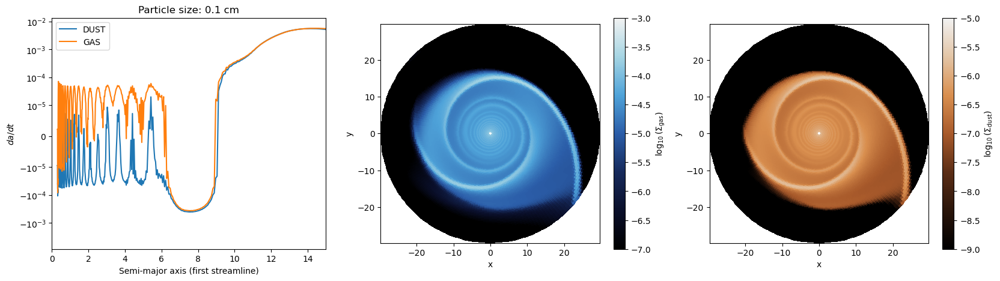

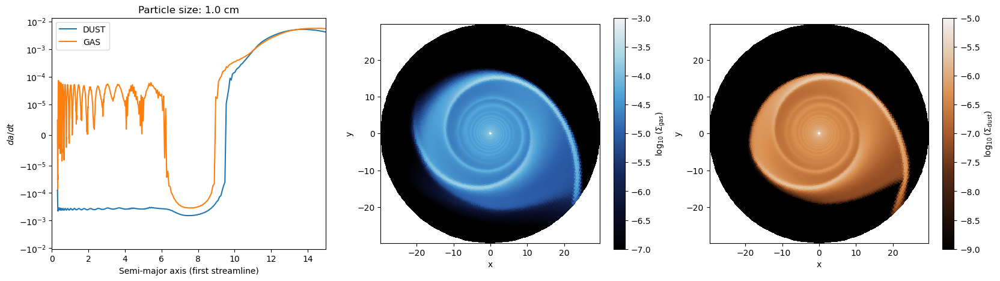

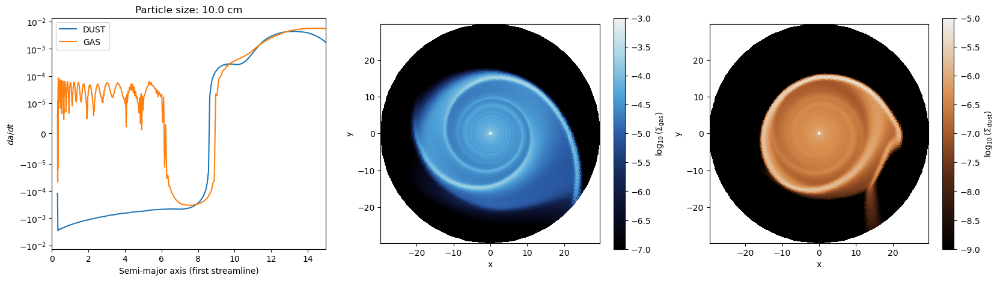

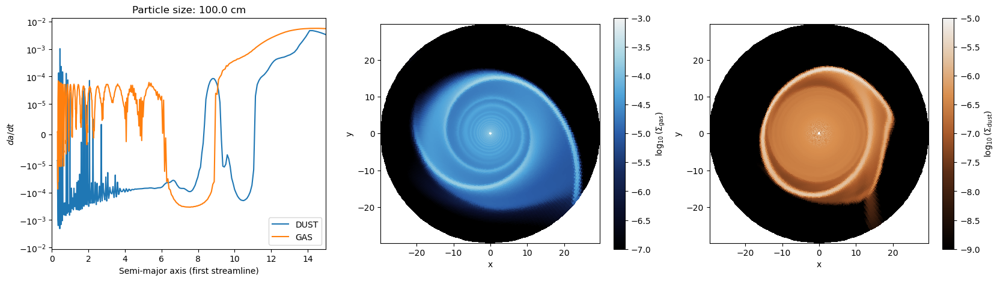

In [61]:
%reload_ext autoreload
%autoreload 2

def plot_streamline_method(path, orbit, material, dust_num):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)


    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    ax[0].plot(a_array, da_dt_arr, label=rf'{material.upper()}')
    ax[0].set_xlabel('Semi-major axis (first streamline)')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_yscale('symlog', linthresh=1e-5)
    ax[0].set_xlim(0, 15)
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)
        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x')
        ax[1].set_ylabel('y')
        ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
        cm = plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x')
        ax[2].set_ylabel('y')
        ax[2].set_aspect('equal')
    return a_array, da_dt_arr



paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        ]
ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']
for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_streamline_method(path, ORBIT, material, dust_num)


# 1.2: $\nabla a$ Method

C:\Users\david\AppData\Local\Temp\ipykernel_10004\4243976604.py:34: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_10004\4243976604.py:40: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)


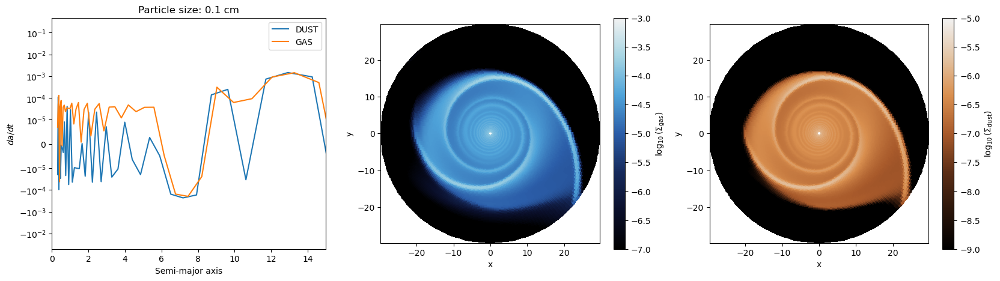

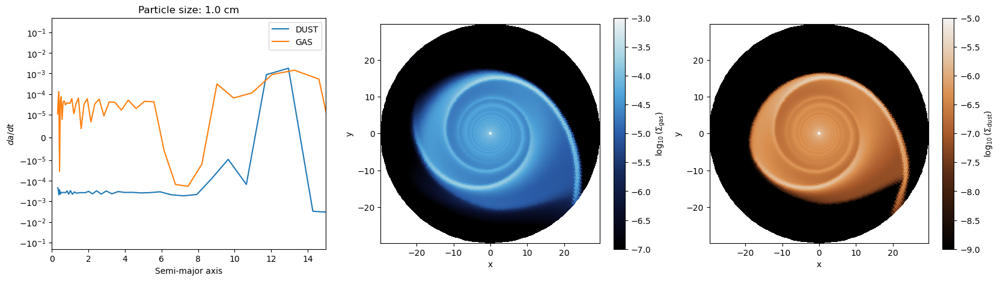

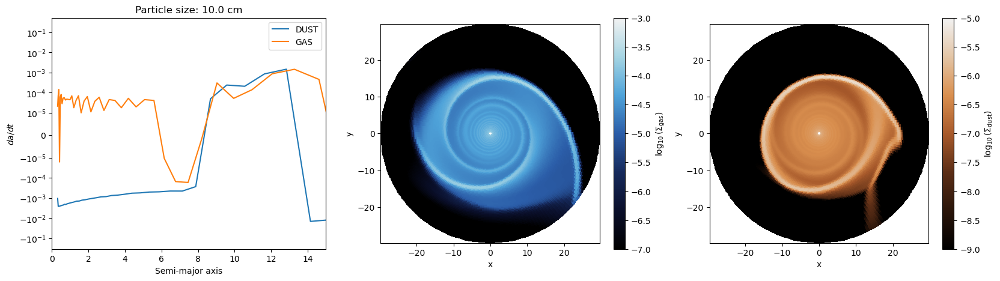

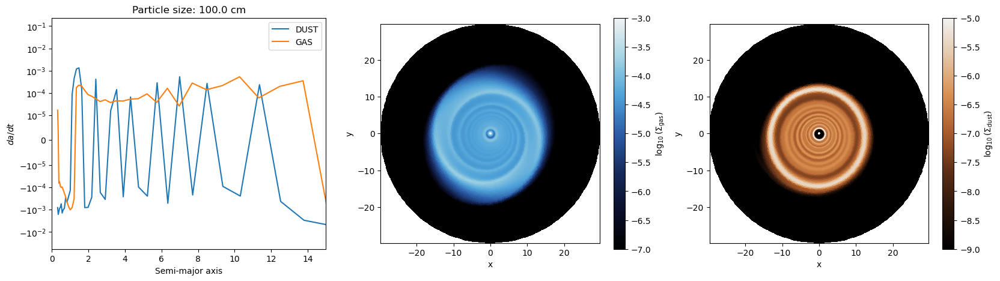

In [137]:
%reload_ext autoreload
%autoreload 2

from scipy.stats import binned_statistic

def plot_nabla_method(path, orbit, material, dust_num, method):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
    a_flat = a_map.flatten()
    da_dt_flat = da_dt_map.flatten()
    n_bins = 50
    bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
    da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
    a_map_binned = (bin_edges[:-1] + bin_edges[1:]) / 2
    da_dt_binned = da_dt_mean
    ax[0].plot(a_map_binned, da_dt_binned, label=rf'{material.upper()}')
    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_yscale('symlog', linthresh=1e-5)
    ax[0].set_xlim(0, 15)
    #ax[0].set_xlim(0, np.nanmax(a_map))
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)
        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x')
        ax[1].set_ylabel('y')
        ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
        cm = plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x')
        ax[2].set_ylabel('y')
        ax[2].set_aspect('equal')
    return a_map_binned, da_dt_binned



paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_30orbits/'
        ]
ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']
method = 'sim'
for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_nabla_method(path, ORBIT, material, dust_num, method)


# 1.3: Terminal Velocity Approximation

C:\Users\david\AppData\Local\Temp\ipykernel_10004\3841729658.py:34: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_10004\3841729658.py:40: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)


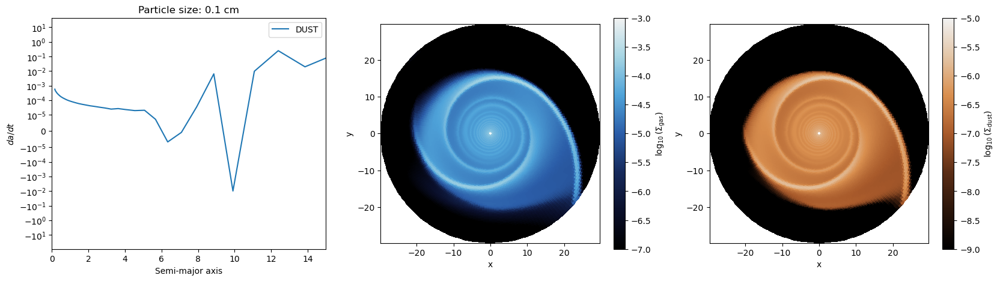

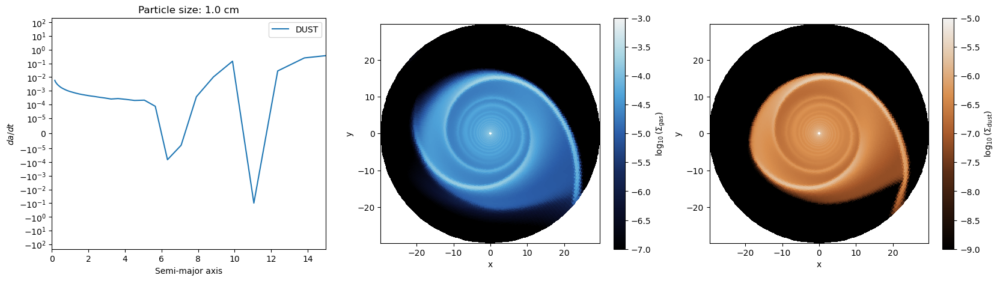

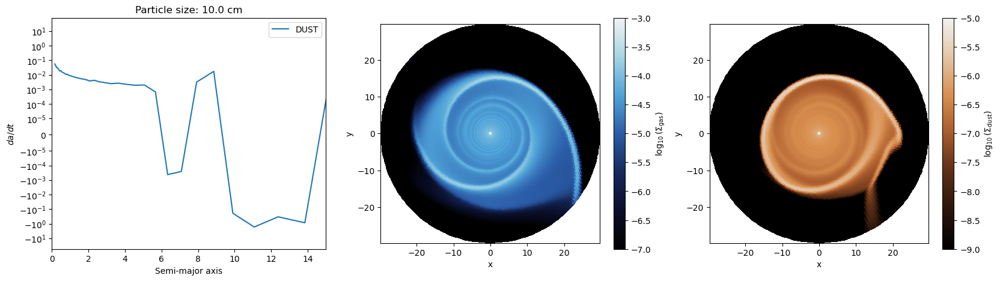

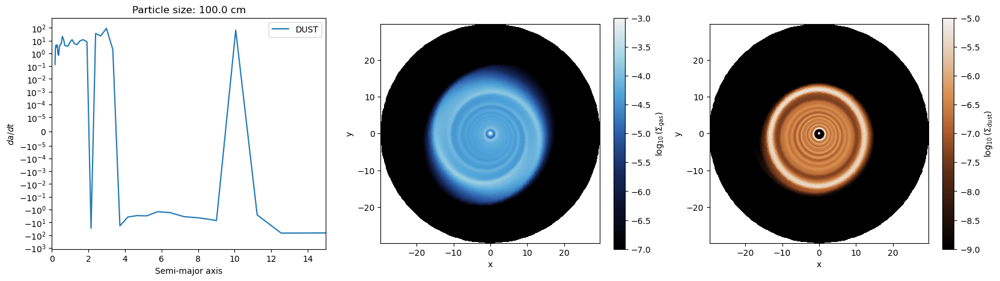

In [136]:
%reload_ext autoreload
%autoreload 2

from scipy.stats import binned_statistic

def plot_tva_method(path, orbit, material, dust_num, method):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
    a_flat = a_map.flatten()
    da_dt_flat = da_dt_map.flatten()
    n_bins = 50
    bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
    da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
    a_map_binned = (bin_edges[:-1] + bin_edges[1:]) / 2
    da_dt_binned = da_dt_mean
    ax[0].plot(a_map_binned, da_dt_binned, label=rf'{material.upper()}')
    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_yscale('symlog', linthresh=1e-5)
    ax[0].set_xlim(0, 15)
    #ax[0].set_xlim(0, np.nanmax(a_map))
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    
    gasdens = loader.load_gasdens(orbit)
    dust_dens = loader.load_dustdens(orbit, dust_num)
    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[1].set_aspect('equal')

    pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
    cm = plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    ax[2].set_xlabel('x')
    ax[2].set_ylabel('y')
    ax[2].set_aspect('equal')
    return a_map_binned, da_dt_binned



paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_30orbits/'
        ]
ORBIT = 20
dust_num = 1
materials = ['dust']
method = 'drag'
for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_tva_method(path, ORBIT, material, dust_num, method)


turn results into d/rho dt
compare streamlines to dust-agnoistic methods
calculate d\rho da from nabla method


take a look at eiteher Cossins et al 2009, Longarini et al 2025

# 2.1: Terminal Velocity Approximation using Statler Model

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\core\processor.py:113: RuntimeWarning: invalid value encountered in divide
  Sigma       = np.where(counts > 0, Sigma / counts, 0)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  phi_grid = self.data_loader.phi_grid
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:77: RuntimeWarning: divide by zero encountered in divide
  dp_dphi = np.gradient(pres_map, phi_grid, axis=1)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:77: RuntimeWarning: invalid value encountered in multiply
  dp_dphi = np.gradient(pres_map, phi_grid, axis=1)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:78: RuntimeWarning: divide by zero encountered in divide
  
c:\Users\david\Documents\Circumstel

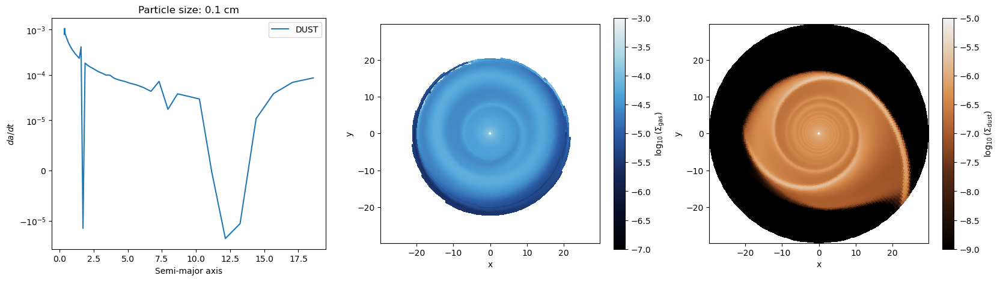

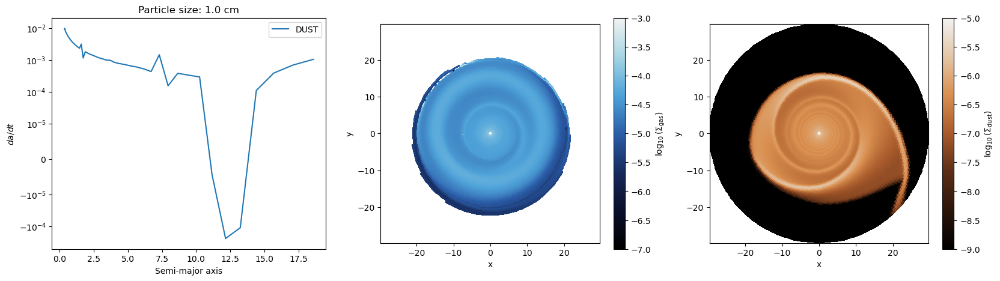

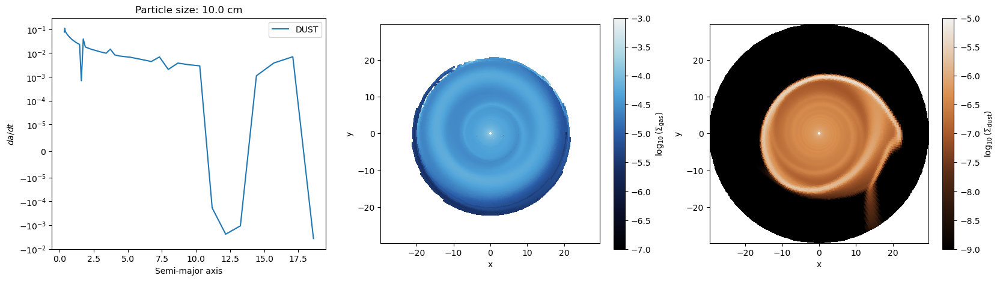

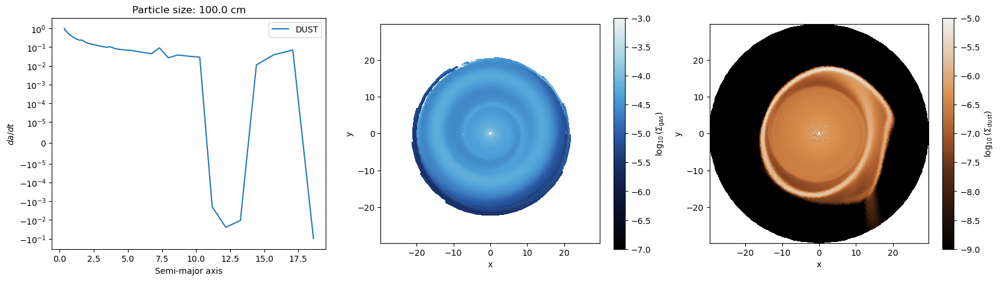

In [ ]:
%reload_ext autoreload
%autoreload 2

from scipy.stats import binned_statistic

def plot_tva_method(path, orbit, material, dust_num, method):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
    a_flat = a_map.flatten()
    da_dt_flat = da_dt_map.flatten()
    n_bins = 50
    bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
    da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
    a_map_binned = (bin_edges[:-1] + bin_edges[1:]) / 2
    da_dt_binned = da_dt_mean
    ax[0].plot(a_map_binned, da_dt_binned, label=rf'{material.upper()}')
    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_yscale('symlog', linthresh=1e-5)
    #ax[0].set_xlim(0, np.nanmax(a_map))
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    gasdens = rvc.calculate_statler_components(orbit)[2]
    dust_dens = loader.load_dustdens(orbit, dust_num)
    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[1].set_aspect('equal')

    pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
    cm = plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    ax[2].set_xlabel('x')
    ax[2].set_ylabel('y')
    ax[2].set_aspect('equal')
    return a_map_binned, da_dt_binned



paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        ]
ORBIT = 20
dust_num = 1
materials = ['dust']
method = 'statler'
for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_tva_method(path, ORBIT, material, dust_num, method)


# 2.2: Terminal Velocity Approximation using Axisymmetric Disk from FARGO3D data

Stokes number range: 0.006310288705405816 - 4.669367233757188


ValueError: x and y must have same first dimension, but have shapes (256,) and (2, 200)

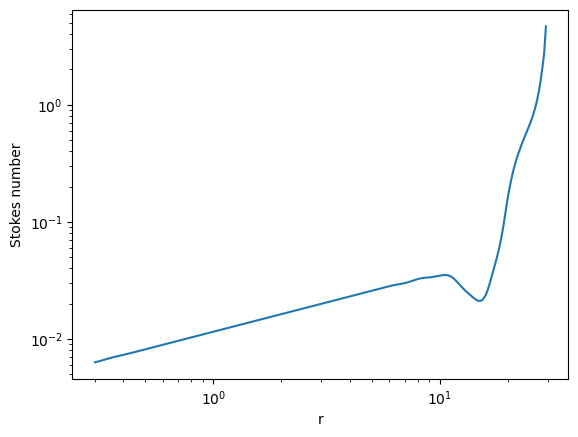

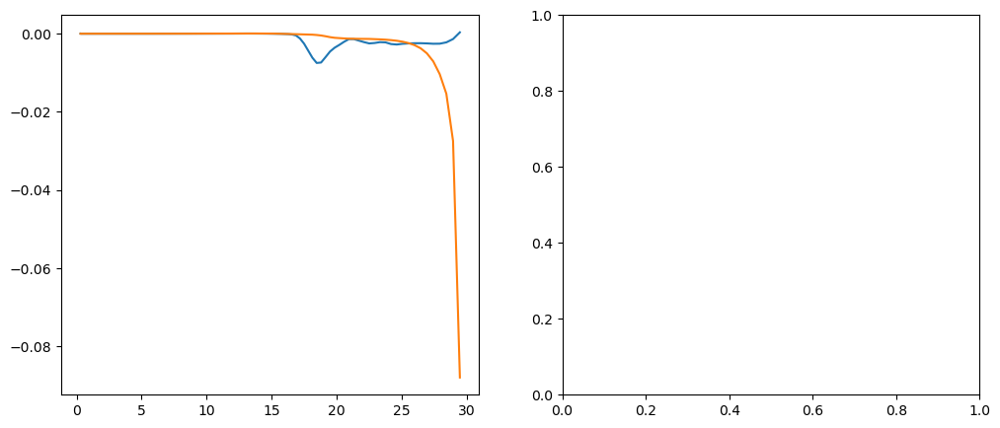

In [ ]:
%reload_ext autoreload
%autoreload 2

def axisymmetric_avg(data):
    return np.mean(data, axis=1)


def axisymmetric_relative_vel(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    processor = SimulationDataProcessor(loader, variables, streamlines)
    rvc = relative_velocity_calculator(loader, variables, streamlines, DUST, 'axisymmetric')

    vr_fargo_sim = rvc.calculate_relative_velocity(orbit)
    particle_type = 'particle'
    vr_TVA = rvc.TVA(orbit, path, particle_type)
    vr_llambay = rvc.llambay_19(orbit, path, particle_type)

    r_grid = loader.r_grid

    vr_sim_avg = axisymmetric_avg(vr_fargo_sim)
    vr_TVA_avg = axisymmetric_avg(vr_TVA)
    vr_llambay_avg = axisymmetric_avg(vr_llambay)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(r_grid, vr_sim_avg, label='FARGO Sim')
    ax[0].plot(r_grid, vr_TVA_avg, label='TVA')
    ax[0].plot(r_grid, vr_llambay_avg, label='Llambay+19')
    ax[0].set_xlim(0, 15)
    ax[0].set_xlabel('r')
    ax[0].set_ylabel(r'$v_{r_{dust}} - v_{r_{gas}}$', fontsize= 15)
    ax[0].set_yscale('symlog', linthresh=1e-5)

    vr_sim_local_maxima = r_grid[(np.diff(np.sign(np.diff(vr_sim_avg))) < 0).nonzero()[0] + 1]


    gasdens = loader.load_gasdens(orbit)
    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
    #add circles in constant r where local maxima occur in vr_sim_avg
    for r in vr_sim_local_maxima:
        circle = plt.Circle((0, 0), r, color='white', fill=False, linestyle='--', alpha=0.5)
        ax[1].add_artist(circle)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[0].legend()
    plt.tight_layout()
    plt.show()

paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        ]
ORBIT = 20
DUST  = 1

for path in paths:
    axisymmetric_relative_vel(path, ORBIT)

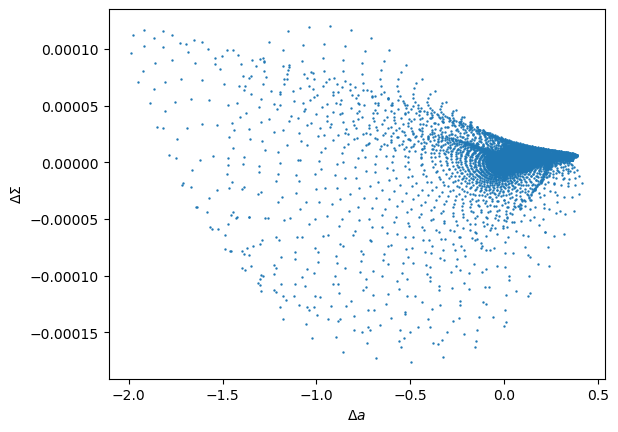

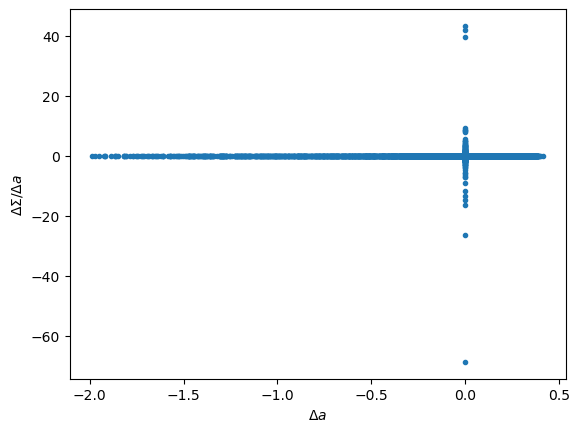

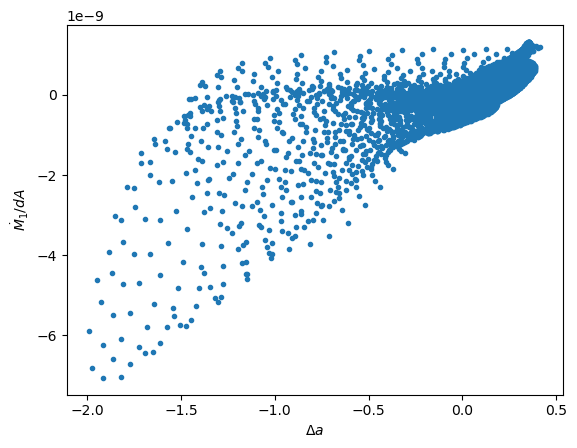

In [83]:

paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        ]

ORBIT = 19

def get_drho_da(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)

    v_r_0, v_phi_0 = loader.load_dustvel(orbit, 1)
    v_r_1, v_phi_1 = loader.load_dustvel(orbit + 1, 1)

    mass_0 = variables.calculate_dust_mass(orbit, 1)
    mass_1 = variables.calculate_dust_mass(orbit + 1, 1)

    r_grid = loader.r_grid


    spec_energy_0 = 0.5 * (v_r_0**2 + v_phi_0**2) - 1 / r_grid[:, None]
    spec_energy_1 = 0.5 * (v_r_1**2 + v_phi_1**2) - 1 / r_grid[:, None]

    a_0 = -1 / (2 * spec_energy_0)
    a_1 = -1 / (2 * spec_energy_1)

    Sigma_0 = loader.load_gasdens(orbit)
    Sigma_1 = loader.load_gasdens(orbit + 1)

    dot_m_1 = v_r_1 * Sigma_1
    dot_m_0 = v_r_0 * Sigma_0

    da = a_1 - a_0
    dSigma = Sigma_1 - Sigma_0
    mask = r_grid < 15

    plt.scatter((a_1 - a_0)[mask, :].flatten(), (Sigma_1 - Sigma_0)[mask, :].flatten(), s = 0.5)
    plt.ylabel(r'$\Delta \Sigma$')
    plt.xlabel(r'$\Delta a$')
    plt.show()


    da = a_1 - a_0
    dSigma = Sigma_1 - Sigma_0
    drho_da = (dSigma) / (da)
    
    
    plt.plot(da[mask, :].flatten(), drho_da[mask, :].flatten(), '.')
    plt.ylabel(r'$\Delta \Sigma / \Delta a$')
    plt.xlabel(r'$\Delta a$')
    plt.show()


    plt.plot(da[mask, :].flatten(), dot_m_1[mask, :].flatten() * mass_1[mask, :].flatten() / Sigma_1[mask, :].flatten(), '.')
    plt.ylabel(r'$\dot{M}_1 / dA$')
    plt.xlabel(r'$\Delta a$')
    plt.show()

get_drho_da(paths[0], ORBIT)

In [ ]:
def compare_all_methods(path, orbit, material, dust_num):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
        variables = SimulationVariablesCalculator(loader)
        streamlines = SimulationDataStreamlines(loader, variables)
        da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)


        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        ax[0].plot(a_array, da_dt_arr, label=rf'{material.upper()}')
        ax[0].set_xlabel('Semi-major axis (first streamline)')
        ax[0].set_ylabel(r'$da/dt$')
        ax[0].set_yscale('symlog', linthresh=1e-5)
        ax[0].set_xlim(0, 15)
        ax[0].legend()

paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        ]
ORBIT = 20
DUST  = 1


compare_all_methods(paths[0], ORBIT, 'dust', 1)

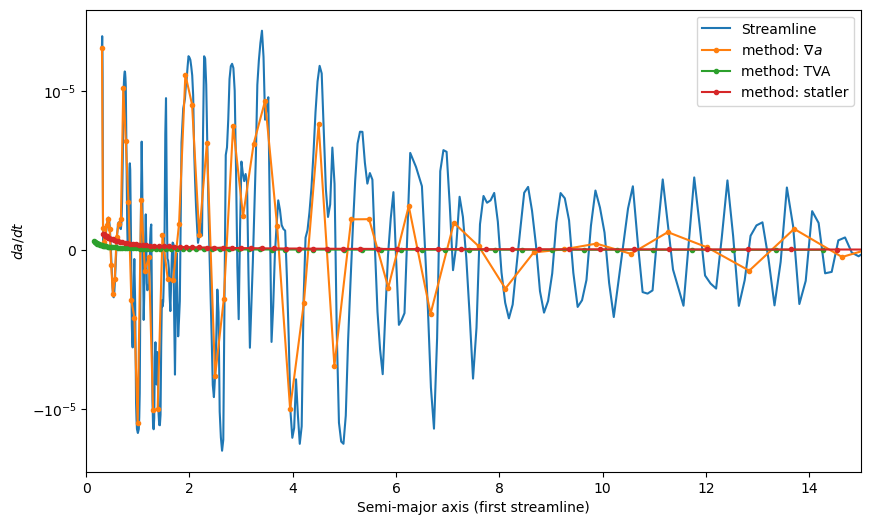

In [ ]:
def compare_all_methods(path, orbit, material, dust_num):
    #params = read_par(path)
    #particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    ax.plot(a_array, da_dt_arr, label=rf'Streamline')
    ax.set_xlabel('Semi-major axis (first streamline)')
    ax.set_ylabel(r'$da/dt$')
    ax.set_yscale('symlog', linthresh=1e-5)
    ax.set_xlim(0, 15)

    methods = ['sim', 'drag', 'statler']
    for method in methods:
        a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
        a_flat = a_map.flatten()
        da_dt_flat = da_dt_map.flatten()
        n_bins = 70
        bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
        da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
        a_map_binned = (bin_edges[:-1] + bin_edges[1:]) / 2
        da_dt_binned = da_dt_mean
        if method == 'sim':
            method = rf'$\nabla a$'

        elif method == 'drag':
            method = 'TVA'

        ax.plot(a_map_binned, da_dt_binned, '.-', label=rf'method: {method}')

    ax.legend()

paths = [#f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/'
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
        ]
ORBIT = 20
DUST  = 1
for orbit in range(1, ORBIT):
    for path in paths:
        fig, ax = plt.subplots(1, 1, figsize=(10, 6))
        compare_all_methods(path, orbit, 'dust', 1)

C:\Users\david\AppData\Local\Temp\ipykernel_10004\3148201791.py:46: RuntimeWarning: Mean of empty slice
  stream_avg = np.nanmean(stacked_stream, axis=0)
c:\Users\david\anaconda3\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\david\AppData\Local\Temp\ipykernel_10004\3148201791.py:48: RuntimeWarning: Mean of empty slice
  method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}


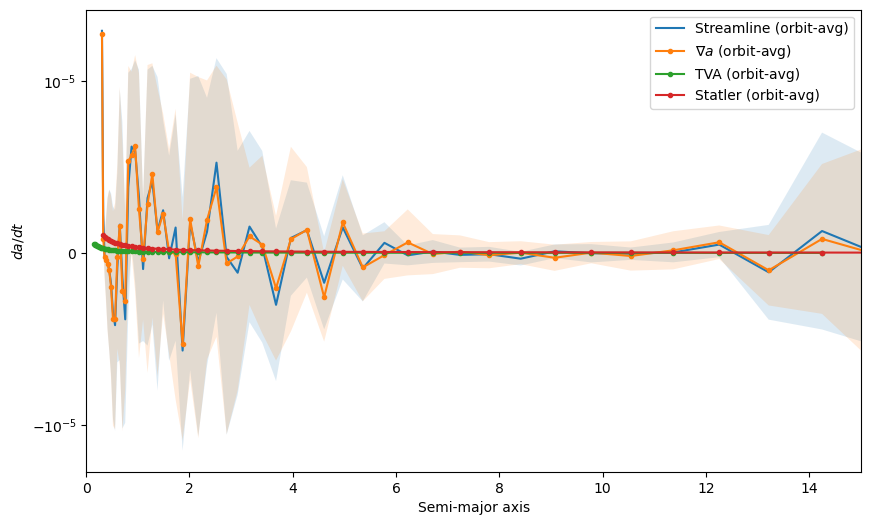

In [97]:
import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.logspace(np.log10(a_min), np.log10(a_max), n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for method in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[method][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Plot ---
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.plot(bin_centers, stream_avg, label='Streamline (orbit-avg)')
    ax.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for method in methods:
        ax.plot(bin_centers, method_avg[method], '.-', label=f'{method_labels[method]} (orbit-avg)')
        ax.fill_between(bin_centers, method_avg[method] - method_std[method],
                         method_avg[method] + method_std[method], alpha=0.15)

    ax.set_xlabel('Semi-major axis')
    ax.set_ylabel(r'$da/dt$')
    ax.set_yscale('symlog', linthresh=1e-5)
    ax.set_xlim(0, 15)
    ax.legend()
    return fig, ax, bin_centers, stream_avg, method_avg


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
orbits = range(10, 20)
fig, ax, a_centers, stream_avg, method_avg = orbit_averaged_compare(path, orbits, 'dust', 1)

C:\Users\david\AppData\Local\Temp\ipykernel_10004\2816048558.py:47: RuntimeWarning: Mean of empty slice
  stream_avg = np.nanmean(stacked_stream, axis=0)
C:\Users\david\AppData\Local\Temp\ipykernel_10004\2816048558.py:49: RuntimeWarning: Mean of empty slice
  method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}


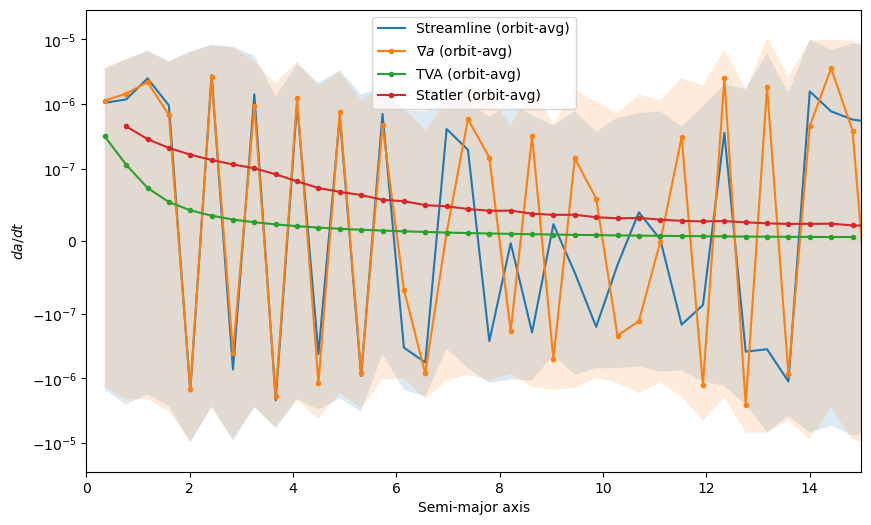

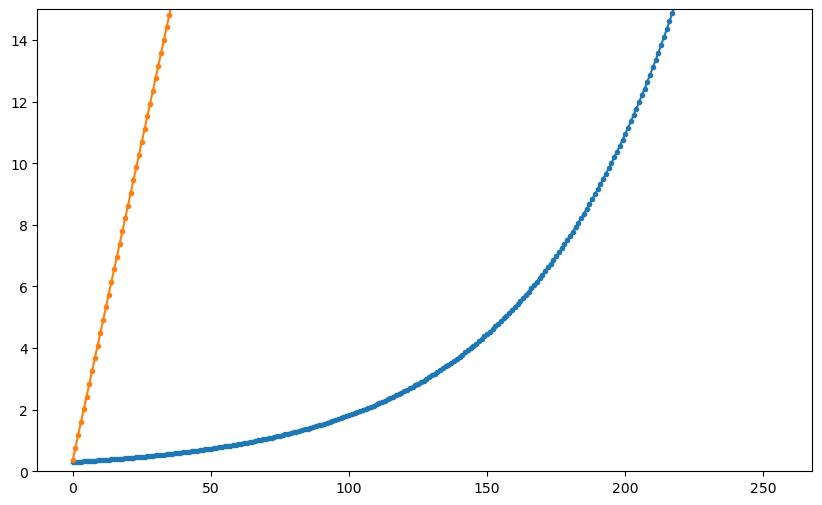

In [119]:
import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.logspace(np.log10(a_min), np.log10(a_max), n_bins + 1)
    bin_edges = np.linspace(a_min, a_max, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for method in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[method][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Plot ---
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.plot(bin_centers, stream_avg, label='Streamline (orbit-avg)')
    ax.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for method in methods:
        ax.plot(bin_centers, method_avg[method], '.-', label=f'{method_labels[method]} (orbit-avg)')
        ax.fill_between(bin_centers, method_avg[method] - method_std[method],
                         method_avg[method] + method_std[method], alpha=0.15)

    ax.set_xlabel('Semi-major axis')
    ax.set_ylabel(r'$da/dt$')
    ax.set_yscale('symlog', linthresh=1e-7)
    ax.set_xlim(0, 15)
    ax.legend()

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    r_grid = loader.r_grid
    plt.plot(r_grid, '.-', label = 'r')
    plt.plot(bin_centers, '.-', label = 'a')
    plt.ylim(0, 15)

    return fig, ax, bin_centers, stream_avg, method_avg


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
orbits = range(10, 20)
fig, ax, a_centers, stream_avg, method_avg = orbit_averaged_compare(path, orbits, 'dust', 1)

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  a_mesh = np.where(counts > 0, a_mesh / counts, np.nan)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:79: RuntimeWarning: divide by zero encountered in divide
  return a_map, v_r, v_phi
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:79: RuntimeWarning: invalid value encountered in multiply
  return a_map, v_r, v_phi
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:80: RuntimeWarning: divide by zero encountered in divide
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:80: RuntimeWarning: invalid value encountered in multiply
  
C:\Users\david\AppData\Local\Temp\ipykernel_16604\2429261687.py:51: RuntimeWarning: Mean of empty slice
  s

Stokes number range: 6.310366022375633e-06 - 6.253883635469561e-05


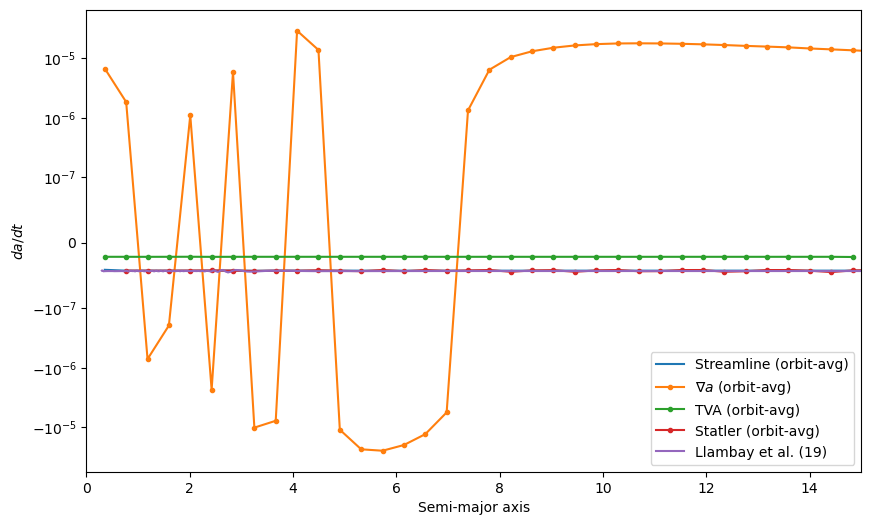

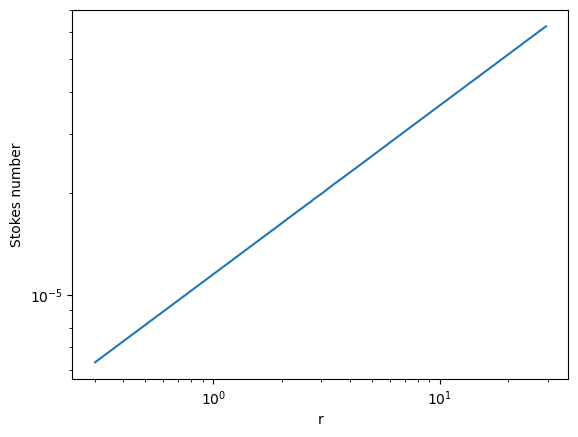

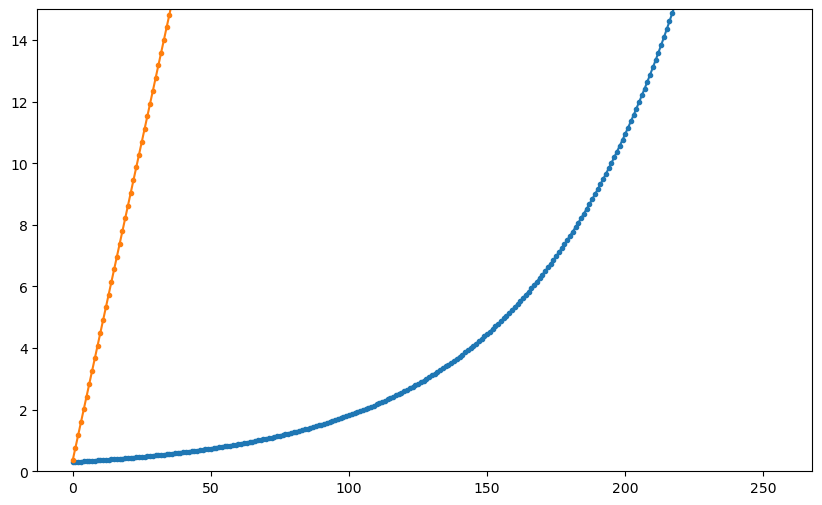

In [23]:
import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)    
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.logspace(np.log10(a_min), np.log10(a_max), n_bins + 1)
    bin_edges = np.linspace(a_min, a_max, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
        da_dt_arr = (da_dt_arr - da_dt_arr_gas)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for method in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, method)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[method][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Plot ---
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.plot(bin_centers, stream_avg, label='Streamline (orbit-avg)')
    ax.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for method in methods:
        ax.plot(bin_centers, method_avg[method], '.-', label=f'{method_labels[method]} (orbit-avg)')
        ax.fill_between(bin_centers, method_avg[method] - method_std[method],
                         method_avg[method] + method_std[method], alpha=0.15)

    ax.set_xlabel('Semi-major axis')
    ax.set_ylabel(r'$da/dt$')
    ax.set_yscale('symlog', linthresh=1e-7)
    ax.set_xlim(0, 15)

    vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    r_grid = loader.r_grid
    ax.plot(r_grid, vr_llambay[:, 0], label='Llambay et al. (19)')



    ax.legend()

    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    r_grid = loader.r_grid
    plt.plot(r_grid, '.-', label = 'r')
    plt.plot(bin_centers, '.-', label = 'a')
    plt.ylim(0, 15)

    return fig, ax, bin_centers, stream_avg, method_avg


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_30orbits/'
orbits = range(1, 2)
fig, ax, a_centers, stream_avg, method_avg = orbit_averaged_compare(path, orbits, 'dust', 1)

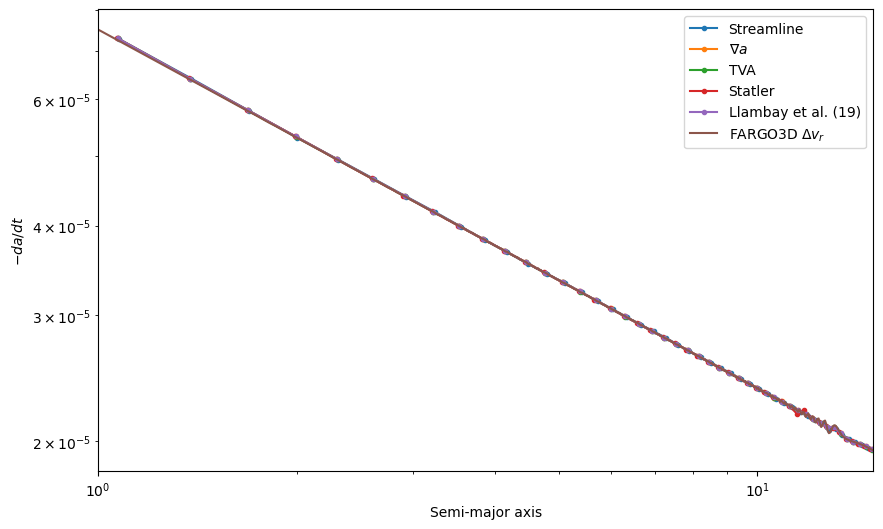

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, 'stokes')

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    #methods = ['sim', 'drag', 'llambay']
    #methods = ['llambay']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        #centers, means = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        results[m] = (centers, means)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(1, 15)
    ax1.legend()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner_wfb/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 1
single_snapshot_compare(path, orbit, 'dust', 1)

C:\Users\david\AppData\Local\Temp\ipykernel_32300\4279674798.py:20: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
C:\Users\david\AppData\Local\Temp\ipykernel_32300\4279674798.py:26: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)


Stopping time: 0.001024334673725637 5.456539990785264
Stokes: 0.006192111709938724-0.05384022590293443
0.9956805791619027 1.0031994954809065


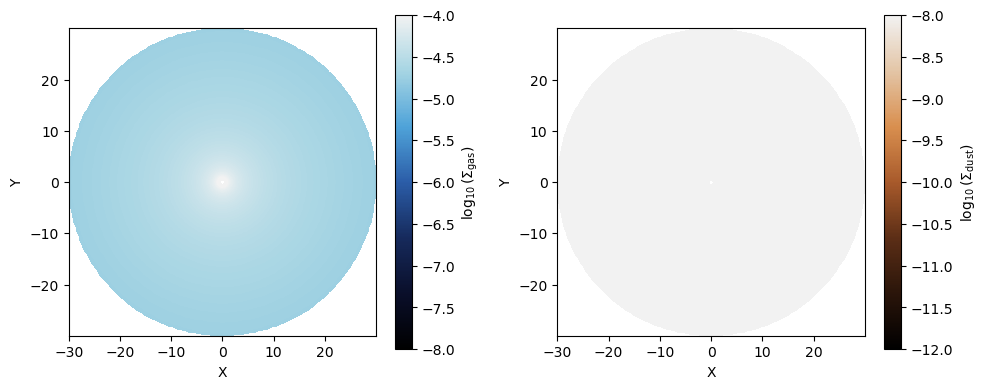

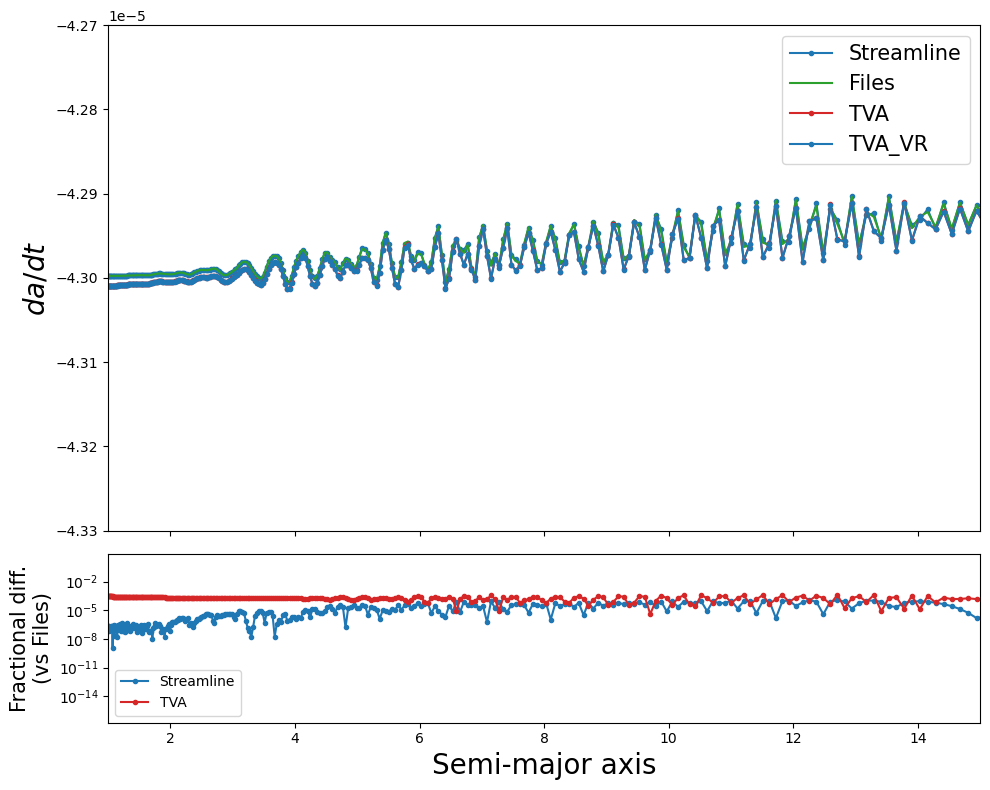

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from analysis.orbital import fit_ellipse_polar

def single_snapshot_compare(path, orbit, material, dust_num):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    dustdens = loader.load_dustdens(orbit, 1)
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
    gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    gasax[0].set_xlabel('X')
    gasax[0].set_ylabel('Y')
    gasax[0].set_aspect('equal')

    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)
    gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    gasax[1].set_xlabel('X')
    gasax[1].set_ylabel('Y')
    gasax[1].set_aspect('equal')
    plt.tight_layout()

    color_map = {
        'Streamline': 'tab:blue',
        'Files':      'tab:green',
        'TVA':        'tab:red',
    }

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    order = np.argsort(a_array)
    a_array = a_array[order]
    da_dt_arr = da_dt_arr[order]
    ax1.plot(a_array, da_dt_arr, '.-', label='Streamline', color=color_map['Streamline'])

    vr_gas, _ = loader.load_gasvel(orbit)
    vr_dust, _ = loader.load_dustvel(orbit, 1)

    r_grid = loader.r_grid
    files_vals = vr_dust[:, 0] - vr_gas[:, 0]
    ax1.plot(r_grid, files_vals, '-', label='Files', color=color_map['Files'])

    a_tva, da_dt_tva, delta_vr, _ = da_dt.compute_da_dt_mass_flux(orbit, material, 'drag')
    a_tva = a_tva[:, 0]
    da_dt_tva = da_dt_tva[:, 0]
    delta_vr = delta_vr[:, 0]
    ax1.plot(a_tva, da_dt_tva, '.-', label='TVA', color=color_map['TVA'])
    ax1.plot(a_tva, delta_vr, '.-', label='TVA_VR')

    ax1.set_ylabel(r'$da/dt$', fontsize=20)
    ax1.set_xlim(1, 15)
    ax1.set_ylim(-4.33*10**(-5), -4.27*10**(-5))
    ax1.axhline(0, color='k', lw=0.8)
    ax1.legend(fontsize=15)

    files_on_streamline = np.interp(a_array, r_grid, files_vals)
    frac_diff_streamline = np.abs(da_dt_arr / files_on_streamline - 1)
    ax2.plot(a_array, frac_diff_streamline, '.-', label='Streamline', color=color_map['Streamline'])

    files_on_tva = np.interp(a_tva, r_grid, files_vals)
    frac_diff_tva = np.abs(da_dt_tva / files_on_tva - 1)
    ax2.plot(a_tva, frac_diff_tva, '.-', label='TVA', color=color_map['TVA'])

    ax2.axhline(0, color='k', lw=0.8)
    ax2.set_xlabel('Semi-major axis', fontsize=20)
    ax2.set_ylabel(r'Fractional diff.' + '\n' + r'(vs Files)', fontsize=15)
    ax2.set_yscale('log')
    ax2.legend(fontsize=10)

    plt.tight_layout()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner/'

orbit = 8
dusttype = 'particle'
single_snapshot_compare(path, orbit, 'dust', 1)
#confirm with very small stokes number (Constant stokes)

C:\Users\david\AppData\Local\Temp\ipykernel_14500\3767240873.py:20: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
C:\Users\david\AppData\Local\Temp\ipykernel_14500\3767240873.py:27: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)


(1024, 200) (1024, 200) (1024, 200)


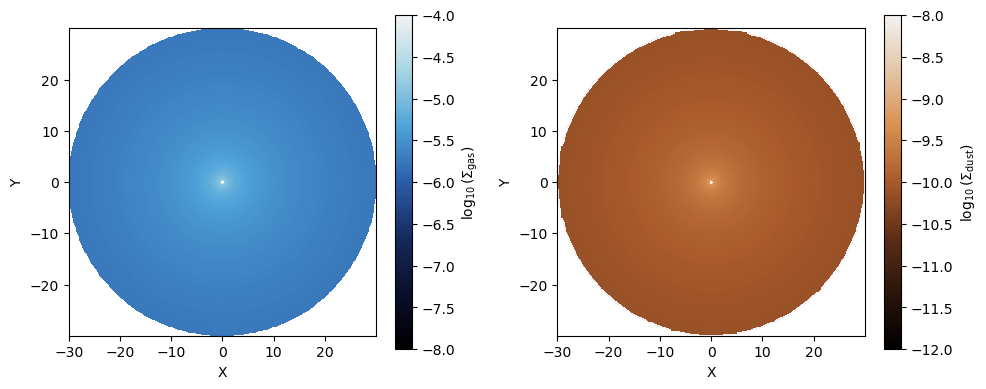

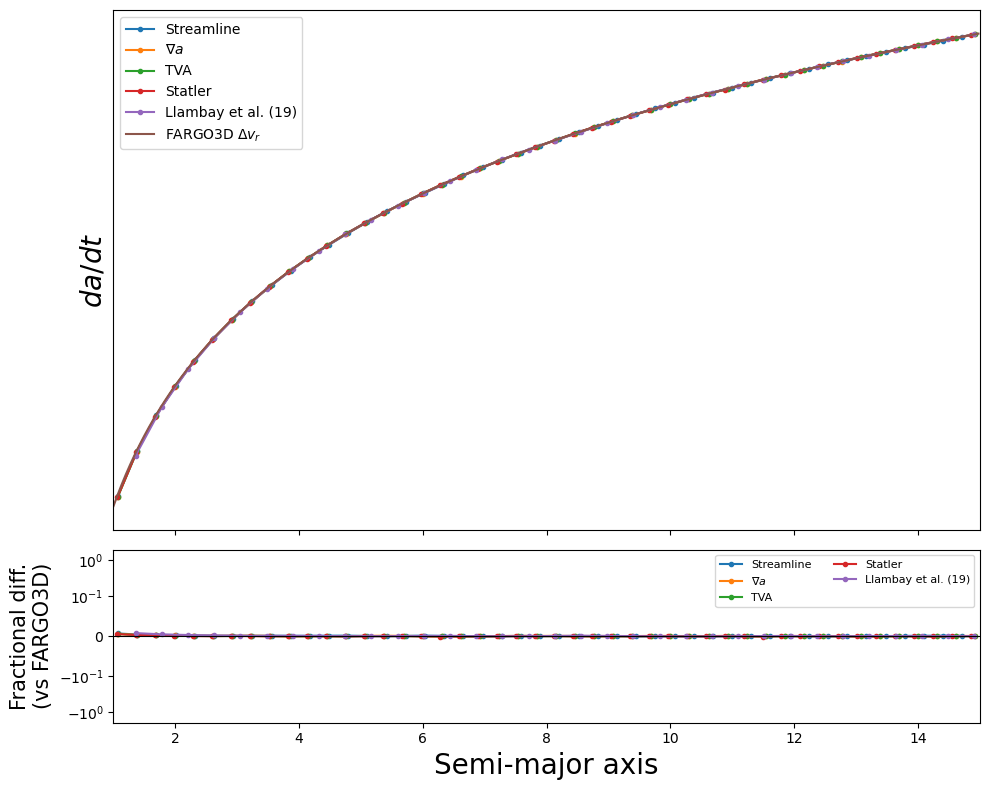

In [110]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    dustdens = loader.load_dustdens(orbit, 1)
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
    gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    gasax[0].set_xlabel('X')
    gasax[0].set_ylabel('Y')
    gasax[0].set_aspect('equal')


    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)
    gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    gasax[1].set_xlabel('X')
    gasax[1].set_ylabel('Y')
    gasax[1].set_aspect('equal')
    plt.tight_layout()

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    #methods = ['sim', 'drag', 'llambay']
    #methods = ['sim']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    streamline_centers = centers[mask]
    streamline_vals = means[mask]
    ax1.plot(streamline_centers, streamline_vals, '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        mask = (centers > 1) & (centers < 15)
        results[m] = (centers[mask], means[mask])
        ax1.plot(centers[mask], means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference (used as reference for ax2) ---
    r_grid = loader.r_grid
    phi_grid = loader.phi_grid
    mask = (r_grid > 1) & (r_grid < 15)
    a_map = da_dt.calc_a_from_streamlines(orbit, 'dust')
    da_dr = np.gradient(a_map, r_grid, axis=0)
    da_dphi = np.gradient(a_map, phi_grid, axis=1)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    delta_vphi_files = loader.load_dustvel(orbit, 1)[1] - loader.load_gasvel(orbit)[1]
    ref_centers = r_grid[mask]
    ref_vals = (delta_vr_files * da_dr)[mask, :] + (delta_vphi_files * da_dphi / r_grid[:, None])[mask, :]
    ref_vals = np.mean(ref_vals, axis=1)
    ax1.plot(ref_centers, ref_vals, label=r'FARGO3D $\Delta v_r$')

    ax1.set_ylabel(r'$da/dt$', fontsize=20)
    ax1.set_yscale('symlog', linthresh = 1e-6)
    ax1.set_xlim(1, 15)
    #ax1.set_ylim(4.27*10**(-5), 4.33*10**(-5))
    ax1.legend()

    # --- Fractional difference panel, relative to FARGO3D direct Δv_r ---
    def frac_diff(c, v):
        ref_on_c = np.interp(c, ref_centers, ref_vals)
        return (v / ref_on_c) - 1

    ax2.plot(streamline_centers, frac_diff(streamline_centers, streamline_vals),
              '.-', label='Streamline')
    for m in methods:
        c, v = results[m]
        ax2.plot(c, frac_diff(c, v), '.-', label=method_labels[m])

    ax2.axhline(0, color='k', lw=0.8)
    ax2.set_xlabel('Semi-major axis', fontsize=20)
    ax2.set_ylabel('Fractional diff.\n(vs FARGO3D)', fontsize=15)
    ax2.set_yscale('symlog', linthresh=1e-1)
    ax2.set_ylim(-2, 2)
    ax2.legend(fontsize=8, ncol=2)

    plt.tight_layout()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 0
dusttype = 'stokes'
single_snapshot_compare(path, orbit, 'dust', 1)

C:\Users\david\AppData\Local\Temp\ipykernel_32300\3133998504.py:21: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
C:\Users\david\AppData\Local\Temp\ipykernel_32300\3133998504.py:27: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)


-4.077567376664199e-14 4.472979623798572
-4.077567376664199e-14 4.472979623798572
[0.99900002 0.9990154  0.99938249 0.99967375 0.99912259 0.9981868
 0.99801589 0.99988063 1.00613907 1.02422123 1.09591307 0.68513947
 0.90953166 0.94009251 0.95330111 0.9603267  0.96255889 0.96198707
 0.95916614 0.95600033 0.94738915 0.7433038  0.99482428 0.98331652
 0.98135117 0.98104549 0.98239865 0.98378566 0.98546643 0.98746603
 0.98842036 0.9898526 ]


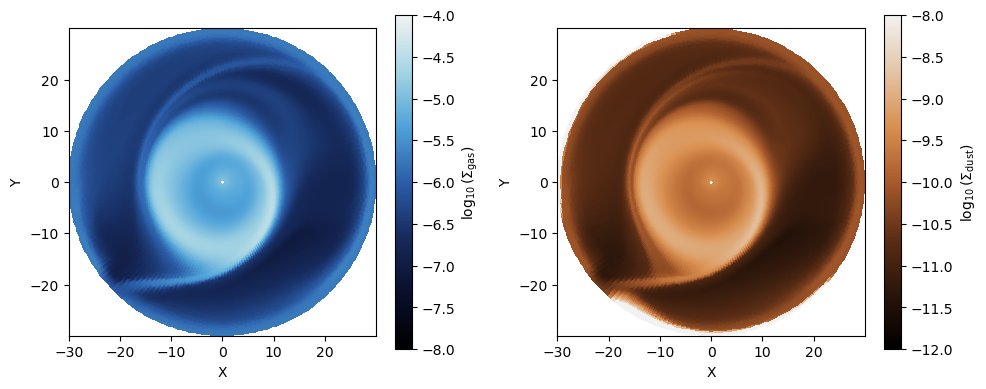

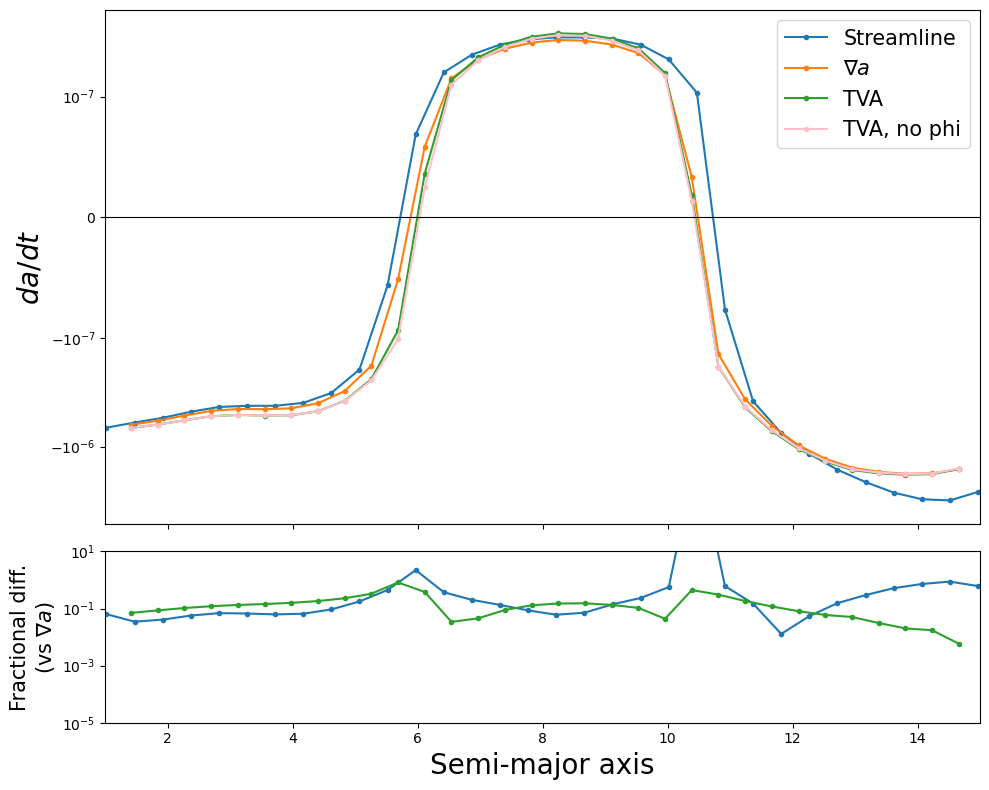

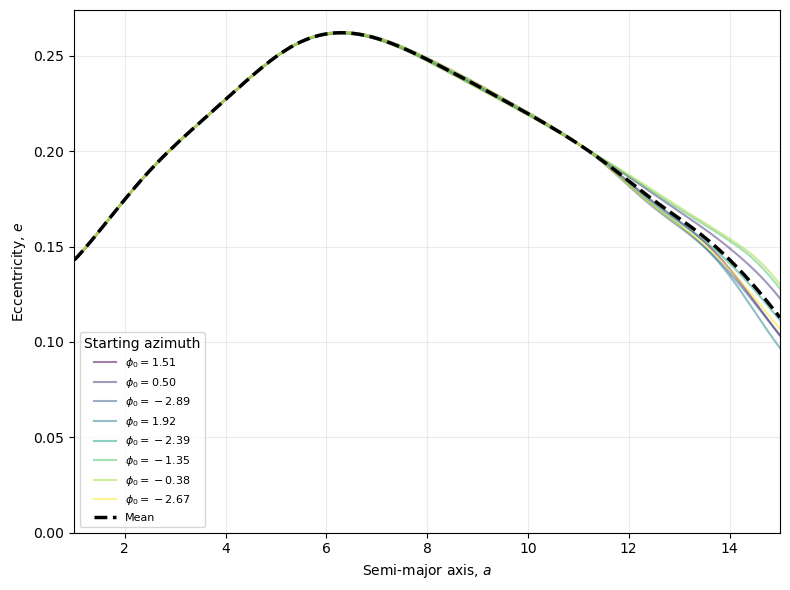

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt
from analysis.orbital import fit_ellipse_polar

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    dustdens = loader.load_dustdens(orbit, 1)
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
    gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    gasax[0].set_xlabel('X')
    gasax[0].set_ylabel('Y')
    gasax[0].set_aspect('equal')

    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)
    gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    gasax[1].set_xlabel('X')
    gasax[1].set_ylabel('Y')
    gasax[1].set_aspect('equal')
    plt.tight_layout()

    methods = ['sim', 'drag', 'statler', 'axisymmetric']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'axisymmetric': 'Axisymmetric Disk'}
    #methods = ['sim', 'drag', 'llambay']
    #methods = ['sim', 'drag']

    # --- Fixed color per line, shared between ax1 and ax2 ---
    color_map = {
        'Streamline': 'tab:blue',
        'sim':        'tab:orange',
        'drag':       'tab:green',
        'statler':    'tab:red',
        'axisymmetric':    'tab:purple',
    }

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    streamline_centers = centers[mask]
    streamline_vals = means[mask]
    ax1.plot(streamline_centers, streamline_vals, '.-', label='Streamline', color=color_map['Streamline'])

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    results2 = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        vr_c, vr_m = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        mask = (centers > 1) & (centers < 15)
        results[m] = (centers[mask], means[mask])
        results2[m] = (vr_c[mask], vr_m[mask])
        ax1.plot(centers[mask], means[mask], '.-', label=method_labels[m], color=color_map[m])
        if m == 'drag':
            ax1.plot(vr_c[mask], vr_m[mask], '.-', label='TVA, no phi', color='pink')
            ratio = vr_m[mask] / means[mask]
            print(ratio)
            #print(np.nanmin(ratio[np.isfinite(ratio)]), np.nanmax(ratio[np.isfinite(ratio)]))

    ax1.set_ylabel(r'$da/dt$', fontsize=20)
    ax1.set_yscale('symlog', linthresh=1e-7)
    ax1.set_xlim(1, 15)
    #ax1.set_ylim(-1e-4, -1e-5)
    ax1.axhline(0, color='k', lw=0.8)
    ax1.legend(fontsize=15)

    # --- Fractional difference panel, relative to the sim (∇a) method ---
    ref_centers, ref_vals = results['sim']

    def frac_diff(c, v):
        ref_on_c = np.interp(c, ref_centers, ref_vals)
        return (v / ref_on_c) - 1

    ax2.plot(streamline_centers, np.abs(frac_diff(streamline_centers, streamline_vals)),
              '.-', label='Streamline', color=color_map['Streamline'])
    for m in methods:
        if m == 'sim':
            continue  # sim is the reference, skip plotting it against itself
        c, v = results[m]
        ax2.plot(c, np.abs(frac_diff(c, v)), '.-', label=method_labels[m], color=color_map[m])

    ax2.axhline(0, color='k', lw=0.8)
    ax2.set_xlabel('Semi-major axis', fontsize=20)
    ax2.set_ylabel(r'Fractional diff.' + '\n' + r'(vs $\nabla a$)', fontsize=15)
    ax2.set_yscale('log')
    ax2.set_ylim(1e-5, 10)
    #ax2.legend(fontsize=15, ncol=2)

    plt.tight_layout()



    rng = np.random.default_rng(100)
    n_random_phi = 8
    r_grid, phi_grid = loader.r_grid, loader.phi_grid
    phi_indices = rng.choice(len(phi_grid), size=n_random_phi, replace=False)

    r_min = max(r_grid[0], 1.0)
    r_max = min(r_grid[-1], 15.0)
    r_starts = np.linspace(1, 20, 300)

    a_common = np.linspace(r_min, r_max, 200)
    e_on_common = []

    fig_e, ax_e = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, n_random_phi))

    for color, phi_index in zip(colors, phi_indices):
        fitted_a = []
        fitted_e = []
        streamline, _, _, _ = streamlines.get_streamline_vectorized(
            r_starts, int(phi_index), orbit, 'gas', dust_num
        )
        dphi = phi_grid[1] - phi_grid[0]

        for stream in streamline:
            phi_stream = phi_grid[phi_index] + dphi * np.arange(len(stream))
            a_fit, e_fit, _ = fit_ellipse_polar(stream, phi_stream)
            if a_fit is not None and e_fit is not None:
                fitted_a.append(a_fit)
                fitted_e.append(e_fit)

        ax_e.plot(
            fitted_a,
            fitted_e,
            '-',
            color=color,
            alpha=0.5,
            label=rf'$\phi_0={phi_grid[phi_index]:.2f}$',
        )

        a_arr = np.asarray(fitted_a)
        e_arr = np.asarray(fitted_e)
        order = np.argsort(a_arr)
        e_on_common.append(
            np.interp(a_common, a_arr[order], e_arr[order], left=np.nan, right=np.nan)
        )

    stack = np.array(e_on_common)
    count = np.isfinite(stack).sum(axis=0)
    e_mean = np.where(count > 0, np.nansum(stack, axis=0) / np.maximum(count, 1), np.nan)

    ax_e.plot(a_common, e_mean, 'k--', lw=2.5, label='Mean')

    ax_e.set_xlabel('Semi-major axis, $a$')
    ax_e.set_ylabel('Eccentricity, $e$')
    ax_e.set_xlim(r_min, r_max)
    ax_e.set_ylim(bottom=0)
    ax_e.grid(alpha=0.25)
    ax_e.legend(title='Starting azimuth', fontsize=8)
    fig_e.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner_wfb/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002_e0.25/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 40
dusttype = 'stokes'
single_snapshot_compare(path, orbit, 'dust', 1)
# compare if relaxed/unrelaxed sims are different with a binary
# try turning binary slowly
# change Llambay label to something related to axisymmetric
# calc TVA ignoring dp/dphi
# no boundary damping

C:\Users\david\AppData\Local\Temp\ipykernel_47640\1098686963.py:22: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
C:\Users\david\AppData\Local\Temp\ipykernel_47640\1098686963.py:28: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)


-3.9031615239488815 9.844535596346873


ValueError: too many values to unpack (expected 3)

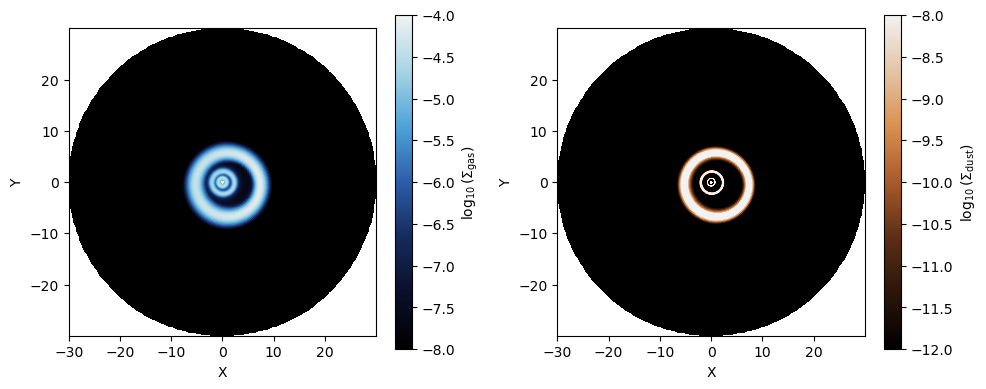

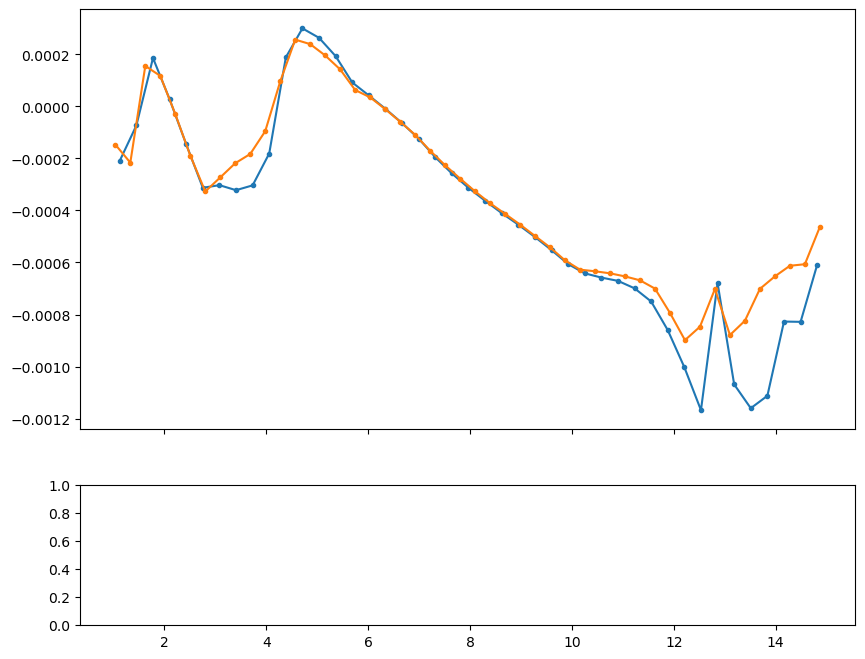

In [2]:
# %reload_ext autoreload
# %autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt
from analysis.orbital import fit_ellipse_polar


def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    dustdens = loader.load_dustdens(orbit, 1)
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
    gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    gasax[0].set_xlabel('X')
    gasax[0].set_ylabel('Y')
    gasax[0].set_aspect('equal')

    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-8)
    gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    gasax[1].set_xlabel('X')
    gasax[1].set_ylabel('Y')
    gasax[1].set_aspect('equal')
    plt.tight_layout()

    methods = ['sim', 'drag', 'statler', 'axisymmetric']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'axisymmetric': 'Axisymmetric Disk'}
    #methods = ['sim', 'drag', 'llambay']
    #methods = ['sim', 'drag']

    # --- Fixed color per line, shared between ax1 and ax2 ---
    color_map = {
        'Streamline': 'tab:blue',
        'sim':        'tab:orange',
        'drag':       'tab:green',
        'statler':    'tab:red',
        'axisymmetric':    'tab:purple',
    }

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    streamline_centers = centers[mask]
    streamline_vals = means[mask]
    ax1.plot(streamline_centers, streamline_vals, '.-', label='Streamline', color=color_map['Streamline'])

    # --- sim / drag / axisymmetric: 2D maps, flattened and binned ---
    # --- statler: already orbit-averaged 1D (a_list, da_dt_avg) ---
    results = {}
    results2 = {}
    for m in methods:
        if m == 'statler':
            a_s, da_dt_s = da_dt.compute_da_dt_statler(orbit)
            centers, means = bin_own_range(a_s, da_dt_s, n_bins)
            mask = (centers > 1) & (centers < 15)
            results[m] = (centers[mask], means[mask])
            ax1.plot(centers[mask], means[mask], '.-',
                     label=method_labels[m], color=color_map[m])
            continue

        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        vr_c, vr_m = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        mask = (centers > 1) & (centers < 15)
        results[m] = (centers[mask], means[mask])
        results2[m] = (vr_c[mask], vr_m[mask])
        ax1.plot(centers[mask], means[mask], '.-', label=method_labels[m], color=color_map[m])
        if m == 'drag':
            ax1.plot(vr_c[mask], vr_m[mask], '.-', label='TVA, no phi', color='pink')
            ratio = vr_m[mask] / means[mask]
            print(ratio)
            #print(np.nanmin(ratio[np.isfinite(ratio)]), np.nanmax(ratio[np.isfinite(ratio)]))

    ax1.set_ylabel(r'$da/dt$', fontsize=20)
    ax1.set_yscale('symlog', linthresh=1e-7)
    ax1.set_xlim(1, 15)
    #ax1.set_ylim(-1e-4, -1e-5)
    ax1.axhline(0, color='k', lw=0.8)
    ax1.legend(fontsize=15)

    # --- Fractional difference panel, relative to the sim (∇a) method ---
    ref_centers, ref_vals = results['sim']

    def frac_diff(c, v):
        ref_on_c = np.interp(c, ref_centers, ref_vals)
        return (v / ref_on_c) - 1

    ax2.plot(streamline_centers, np.abs(frac_diff(streamline_centers, streamline_vals)),
              '.-', label='Streamline', color=color_map['Streamline'])
    for m in methods:
        if m == 'sim':
            continue  # sim is the reference, skip plotting it against itself
        c, v = results[m]
        ax2.plot(c, np.abs(frac_diff(c, v)), '.-', label=method_labels[m], color=color_map[m])

    ax2.axhline(0, color='k', lw=0.8)
    ax2.set_xlabel('Semi-major axis', fontsize=20)
    ax2.set_ylabel(r'Fractional diff.' + '\n' + r'(vs $\nabla a$)', fontsize=15)
    ax2.set_yscale('log')
    ax2.set_ylim(1e-5, 10)
    #ax2.legend(fontsize=15, ncol=2)

    plt.tight_layout()

    # --- Eccentricity vs semi-major axis from streamline fits ---
    rng = np.random.default_rng(100)
    n_random_phi = 8
    r_grid, phi_grid = loader.r_grid, loader.phi_grid
    phi_indices = rng.choice(len(phi_grid), size=n_random_phi, replace=False)

    r_min = max(r_grid[0], 1.0)
    r_max = min(r_grid[-1], 15.0)
    r_starts = np.linspace(1, 20, 300)

    a_common = np.linspace(r_min, r_max, 200)
    e_on_common = []

    fig_e, ax_e = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, n_random_phi))

    for color, phi_index in zip(colors, phi_indices):
        fitted_a = []
        fitted_e = []
        streamline, _, _, _ = streamlines.get_streamline_vectorized(
            r_starts, int(phi_index), orbit, 'gas', dust_num
        )
        dphi = phi_grid[1] - phi_grid[0]

        for stream in streamline:
            phi_stream = phi_grid[phi_index] + dphi * np.arange(len(stream))
            a_fit, e_fit, _ = fit_ellipse_polar(stream, phi_stream)
            if a_fit is not None and e_fit is not None:
                fitted_a.append(a_fit)
                fitted_e.append(e_fit)

        ax_e.plot(
            fitted_a,
            fitted_e,
            '-',
            color=color,
            alpha=0.5,
            label=rf'$\phi_0={phi_grid[phi_index]:.2f}$',
        )

        a_arr = np.asarray(fitted_a)
        e_arr = np.asarray(fitted_e)
        order = np.argsort(a_arr)
        e_on_common.append(
            np.interp(a_common, a_arr[order], e_arr[order], left=np.nan, right=np.nan)
        )

    stack = np.array(e_on_common)
    count = np.isfinite(stack).sum(axis=0)
    e_mean = np.where(count > 0, np.nansum(stack, axis=0) / np.maximum(count, 1), np.nan)

    ax_e.plot(a_common, e_mean, 'k--', lw=2.5, label='Mean')

    ax_e.set_xlabel('Semi-major axis, $a$')
    ax_e.set_ylabel('Eccentricity, $e$')
    ax_e.set_xlim(r_min, r_max)
    ax_e.set_ylim(bottom=0)
    ax_e.grid(alpha=0.25)
    ax_e.legend(title='Starting azimuth', fontsize=8)
    fig_e.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner_wfb/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.01_m0.3/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 100
dusttype = 'stokes'
single_snapshot_compare(path, orbit, 'dust', 1)
# compare if relaxed/unrelaxed sims are different with a binary
# try turning binary slowly
# change Llambay label to something related to axisymmetric
# calc TVA ignoring dp/dphi
# no boundary damping

# write up this code cell
# do orbit-averaged TVA

# orbit-average nabla a
# increase mass ratio
# do slightly higher stokes number sims

#fravtional diff as function of mass ratio and ecc (local)

C:\Users\david\AppData\Local\Temp\ipykernel_4380\2628514829.py:39: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
C:\Users\david\AppData\Local\Temp\ipykernel_4380\2628514829.py:45: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-6)


(1024, 200) (1024, 200) (1024, 200)


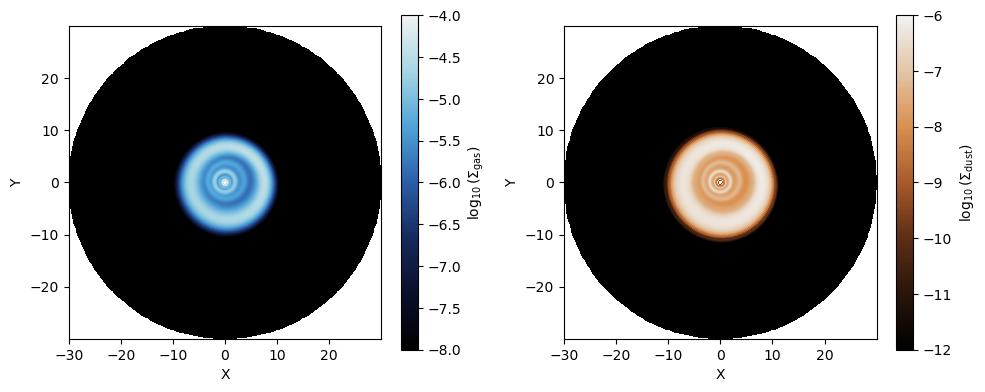

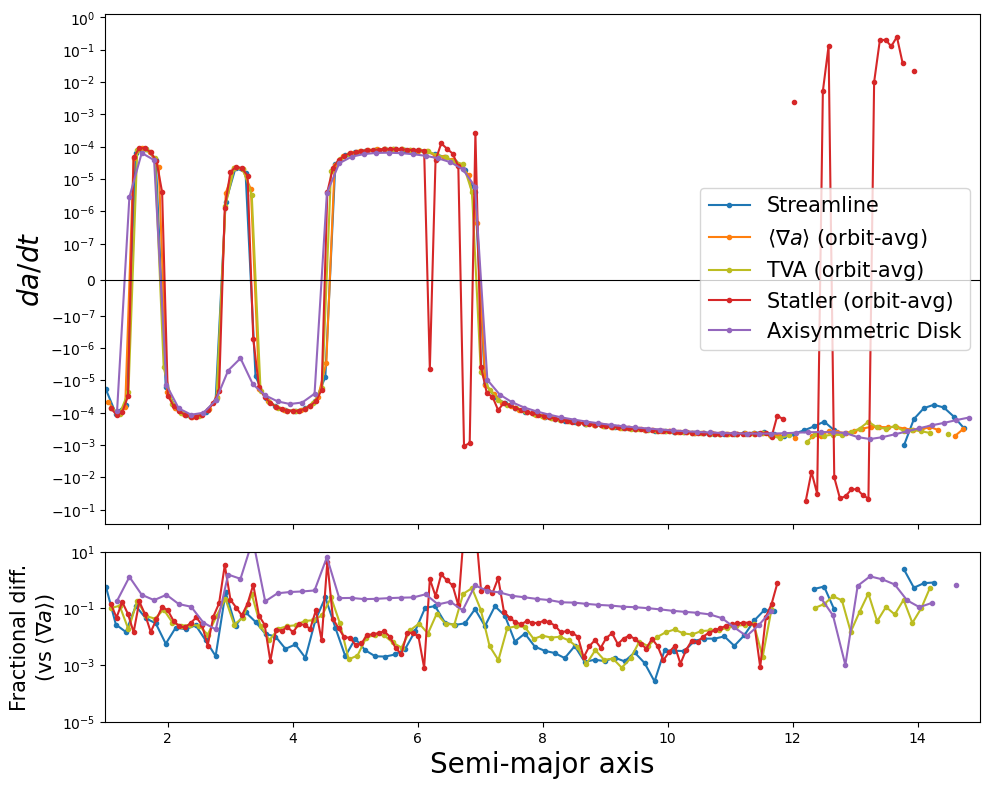

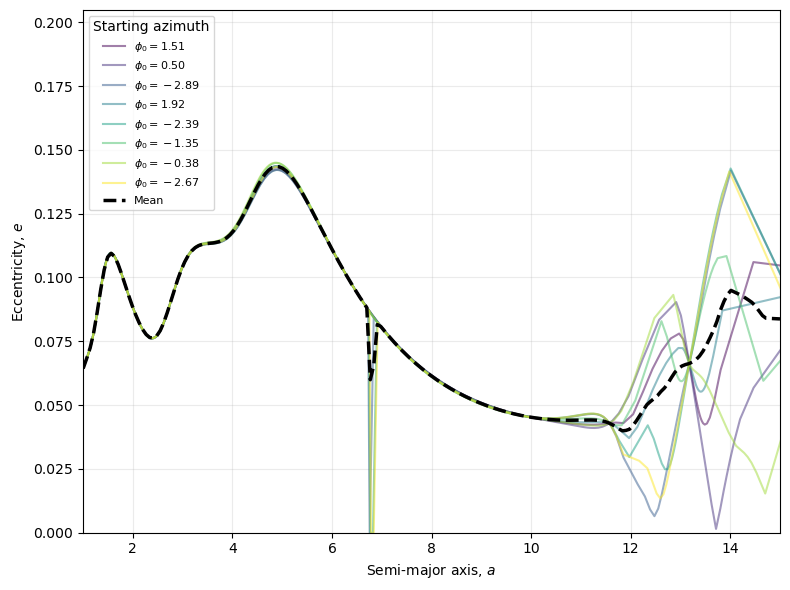

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt
from analysis.orbital import fit_ellipse_polar

# NOTE: SimulationDataLoader, SimulationVariablesCalculator, SimulationDataStreamlines,
# relative_velocity_calculator, da_dt_calculator, cmap and cmap_dust are expected to be
# imported/defined earlier in the notebook, as in the original cell.


def bin_own_range(a_arr, da_dt_arr, n_bins):
    a_arr = np.asarray(a_arr)
    da_dt_arr = np.asarray(da_dt_arr)
    valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
    a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
    if a_arr.size == 0:
        return np.array([]), np.array([])
    edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
    return centers, means


def single_snapshot_compare(path, orbit, material, dust_num, dusttype='stokes', n_bins=150):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, 'sim')
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    # --- Density snapshots ---
    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    dustdens = loader.load_dustdens(orbit, 1)
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
    gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    gasax[0].set_xlabel('X')
    gasax[0].set_ylabel('Y')
    gasax[0].set_aspect('equal')

    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-12, vmax=-6)
    gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
    gasax[1].set_xlabel('X')
    gasax[1].set_ylabel('Y')
    gasax[1].set_aspect('equal')
    plt.tight_layout()

    methods = ['sim', 'drag_avg', 'statler', 'axisymmetric']
    #methods = ['sim']
    method_labels = {
        'sim':          r'$\langle\nabla a\rangle$ (orbit-avg)',
        'drag_avg':     'TVA (orbit-avg)',
        'statler':      'Statler (orbit-avg)',
        'axisymmetric': 'Axisymmetric Disk',
    }

    # --- Fixed color per line, shared between ax1 and ax2 ---
    color_map = {
        'Streamline':   'tab:blue',
        'sim':          'tab:orange',
        'drag_avg':     'tab:olive',
        'statler':      'tab:red',
        'axisymmetric': 'tab:purple',
    }

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    streamline_centers = centers[mask]
    streamline_vals = means[mask]
    ax1.plot(streamline_centers, streamline_vals, '.-', label='Streamline', color=color_map['Streamline'])

    # --- sim / drag_avg / statler: orbit-averaged 1D (a_list, <da/dt>) ---
    # --- axisymmetric: 2D map, flattened and binned ---
    results = {}
    for m in methods:
        if m in ('statler', 'sim', 'drag_avg'):
            if m == 'statler':
                a_s, da_dt_s = da_dt.compute_da_dt_statler(orbit)
            elif m == 'sim':
                a_s, da_dt_s = da_dt.compute_da_dt_sim_avg(orbit, material)
            else:
                a_s, da_dt_s = da_dt.compute_da_dt_drag_avg(orbit, material)
            centers, means = bin_own_range(a_s, da_dt_s, n_bins)
            mask = (centers > 1) & (centers < 15)
            results[m] = (centers[mask], means[mask])
            ax1.plot(centers[mask], means[mask], '.-',
                     label=method_labels[m], color=color_map[m])
            continue

        # axisymmetric: 2D map, flattened and binned
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        mask = (centers > 1) & (centers < 15)
        results[m] = (centers[mask], means[mask])
        ax1.plot(centers[mask], means[mask], '.-', label=method_labels[m], color=color_map[m])

    ax1.set_ylabel(r'$da/dt$', fontsize=20)
    ax1.set_yscale('symlog', linthresh=1e-7)
    ax1.set_xlim(1, 15)
    ax1.axhline(0, color='k', lw=0.8)
    ax1.legend(fontsize=15)

    # --- Fractional difference panel, relative to the orbit-averaged sim method ---
    ref_centers, ref_vals = results['sim']

    def frac_diff(c, v):
        ref_on_c = np.interp(c, ref_centers, ref_vals)
        return (v / ref_on_c) - 1

    ax2.plot(streamline_centers, np.abs(frac_diff(streamline_centers, streamline_vals)),
             '.-', label='Streamline', color=color_map['Streamline'])
    for m in methods:
        if m == 'sim':
            continue  # sim is the reference, skip plotting it against itself
        c, v = results[m]
        ax2.plot(c, np.abs(frac_diff(c, v)), '.-', label=method_labels[m], color=color_map[m])

    ax2.axhline(0, color='k', lw=0.8)
    ax2.set_xlabel('Semi-major axis', fontsize=20)
    ax2.set_ylabel(r'Fractional diff.' + '\n' + r'(vs $\langle\nabla a\rangle$)', fontsize=15)
    ax2.set_yscale('log')
    ax2.set_ylim(1e-5, 10)

    plt.tight_layout()

    # --- Eccentricity vs semi-major axis from streamline fits ---
    rng = np.random.default_rng(100)
    n_random_phi = 8
    r_grid, phi_grid = loader.r_grid, loader.phi_grid
    phi_indices = rng.choice(len(phi_grid), size=n_random_phi, replace=False)

    r_min = max(r_grid[0], 1.0)
    r_max = min(r_grid[-1], 15.0)
    r_starts = np.linspace(1, 20, 300)

    a_common = np.linspace(r_min, r_max, 200)
    e_on_common = []

    fig_e, ax_e = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, n_random_phi))

    for color, phi_index in zip(colors, phi_indices):
        fitted_a = []
        fitted_e = []
        streamline, _, _, _ = streamlines.get_streamline_vectorized(
            r_starts, int(phi_index), orbit, 'gas', dust_num
        )
        dphi = phi_grid[1] - phi_grid[0]

        for stream in streamline:
            phi_stream = phi_grid[phi_index] + dphi * np.arange(len(stream))
            a_fit, e_fit, _ = fit_ellipse_polar(stream, phi_stream)
            if a_fit is not None and e_fit is not None:
                fitted_a.append(a_fit)
                fitted_e.append(e_fit)

        ax_e.plot(
            fitted_a,
            fitted_e,
            '-',
            color=color,
            alpha=0.5,
            label=rf'$\phi_0={phi_grid[phi_index]:.2f}$',
        )

        a_arr = np.asarray(fitted_a)
        e_arr = np.asarray(fitted_e)
        order = np.argsort(a_arr)
        e_on_common.append(
            np.interp(a_common, a_arr[order], e_arr[order], left=np.nan, right=np.nan)
        )

    stack = np.array(e_on_common)
    count = np.isfinite(stack).sum(axis=0)
    e_mean = np.where(count > 0, np.nansum(stack, axis=0) / np.maximum(count, 1), np.nan)

    ax_e.plot(a_common, e_mean, 'k--', lw=2.5, label='Mean')

    ax_e.set_xlabel('Semi-major axis, $a$')
    ax_e.set_ylabel('Eccentricity, $e$')
    ax_e.set_xlim(r_min, r_max)
    ax_e.set_ylim(bottom=0)
    ax_e.grid(alpha=0.25)
    ax_e.legend(title='Starting azimuth', fontsize=8)
    fig_e.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner_wfb/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002_nooutdamptest_outflow_alpha-5/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.01_m0.5_nofb/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 10
dusttype = 'stokes'
single_snapshot_compare(path, orbit, 'dust', 1, dusttype=dusttype)

# compare if relaxed/unrelaxed sims are different with a binary
# try turning binary slowly
# change Llambay label to something related to axisymmetric
# calc TVA ignoring dp/dphi
# no boundary damping

# write up this code cell
# do orbit-averaged TVA

# orbit-average nabla a  (done: compute_da_dt_sim_avg)
# increase mass ratio
# do slightly higher stokes number sims

#fractional diff as function of mass ratio and ecc (local)

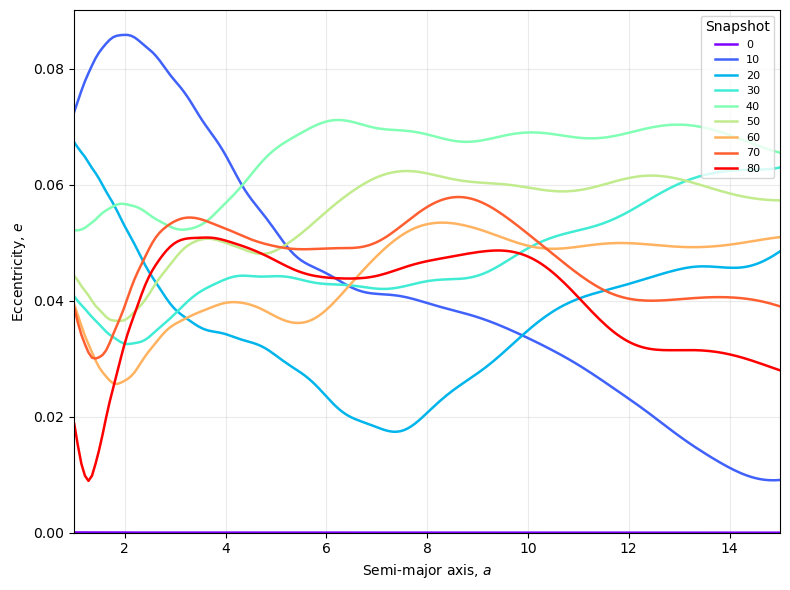

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors
from analysis.orbital import fit_ellipse_polar

def eccentricity_vs_time(path, orbits, material='gas', dust_num=1, dusttype='stokes',
                         a_targets=(2, 4, 6, 8), a_range=(1, 15), n_a=200,
                         orbits_per_snapshot=1.0):
    """
    Eccentricity from streamline ellipse fits at every snapshot in `orbits`.

    Returns (t, a_common, e_map) with e_map of shape (n_snapshots, n_a); NaN where
    a fit failed or the semi-major axis is outside the fitted range.

    material            : 'gas' or 'dust', whose streamlines are fitted
    a_targets           : semi-major axes at which to draw e(t) lines
    orbits_per_snapshot : multiply the snapshot number by this to get time in orbits
    """
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    a_common = np.linspace(a_range[0], a_range[1], n_a)
    orbits = list(orbits)
    e_map = np.full((len(orbits), n_a), np.nan)

    for k, n in enumerate(orbits):
        try:
            _, _, a_arr, e_arr, _, _ = da_dt.calc_a_from_streamlines(
                n, material, return_orbits=True
            )
        except Exception as err:
            print(f"snapshot {n} skipped: {err}")
            continue

        a_arr = np.asarray(a_arr, dtype=float)
        e_arr = np.asarray(e_arr, dtype=float)
        ok = np.isfinite(a_arr) & np.isfinite(e_arr) & (a_arr > 0) & (e_arr < 1)
        if ok.sum() < 2:
            continue
        order = np.argsort(a_arr[ok])
        e_map[k] = np.interp(a_common, a_arr[ok][order], e_arr[ok][order],
                             left=np.nan, right=np.nan)

    t = np.asarray(orbits) * orbits_per_snapshot

    # --- Plot: e(t) at fixed a, and the full e(a, t) map ---
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9), sharex=True,
                                   gridspec_kw={'height_ratios': [1, 1]})

    colors = plt.cm.viridis(np.linspace(0, 1, len(a_targets)))
    for color, a_t in zip(colors, a_targets):
        col = np.argmin(np.abs(a_common - a_t))
        ax1.plot(t, e_map[:, col], '.-', color=color, label=rf'$a = {a_common[col]:.1f}$')
    ax1.set_ylabel('Eccentricity, $e$', fontsize=16)
    ax1.set_ylim(bottom=0)
    ax1.grid(alpha=0.25)
    ax1.legend(fontsize=11, ncol=2)

    pcm = ax2.pcolormesh(t, a_common, e_map.T, shading='nearest', cmap='magma', vmin=0)
    fig.colorbar(pcm, ax=ax2, label='Eccentricity, $e$')
    ax2.set_ylabel('Semi-major axis, $a$', fontsize=16)
    ax2.set_xlabel('Orbit' if orbits_per_snapshot != 1.0 else 'Snapshot', fontsize=16)

    fig.tight_layout()
    plt.show()
    return t, a_common, e_map


def eccentricity_profiles_vs_time(path, orbits, material='gas', dust_num=1,
                                  n_random_phi=8, seed=100, a_range=(1.0, 15.0),
                                  r_starts=None, orbits_per_snapshot=1.0, cmap_name='rainbow'):
    """
    Mean e(a) profile (averaged over random starting azimuths, as in the single-snapshot
    plot), one line per snapshot, colored by time.
    """
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)

    r_grid, phi_grid = loader.r_grid, loader.phi_grid
    dphi = phi_grid[1] - phi_grid[0]
    rng = np.random.default_rng(seed)
    phi_indices = rng.choice(len(phi_grid), size=n_random_phi, replace=False)  # same starts every snapshot

    r_min = max(r_grid[0], a_range[0])
    r_max = min(r_grid[-1], a_range[1])
    if r_starts is None:
        r_starts = np.linspace(1, 20, 300)
    a_common = np.linspace(r_min, r_max, 200)

    orbits = list(orbits)
    t = np.asarray(orbits) * orbits_per_snapshot
    norm = mcolors.Normalize(vmin=t.min(), vmax=t.max())
    cmap_t = plt.get_cmap(cmap_name)

    fig, ax = plt.subplots(figsize=(8, 6))
    e_mean_all = np.full((len(orbits), len(a_common)), np.nan)

    for k, n in enumerate(orbits):
        e_on_common = []
        try:
            for phi_index in phi_indices:
                fitted_a, fitted_e = [], []
                streamline, _, _, _ = streamlines.get_streamline_vectorized(
                    r_starts, int(phi_index), n, material, dust_num
                )
                for stream in streamline:
                    phi_stream = phi_grid[phi_index] + dphi * np.arange(len(stream))
                    a_fit, e_fit, _ = fit_ellipse_polar(stream, phi_stream)
                    if a_fit is not None and e_fit is not None:
                        fitted_a.append(a_fit)
                        fitted_e.append(e_fit)

                a_arr = np.asarray(fitted_a, dtype=float)
                e_arr = np.asarray(fitted_e, dtype=float)
                ok = np.isfinite(a_arr) & np.isfinite(e_arr)
                if ok.sum() < 2:
                    continue
                order = np.argsort(a_arr[ok])
                e_on_common.append(
                    np.interp(a_common, a_arr[ok][order], e_arr[ok][order],
                              left=np.nan, right=np.nan)
                )
        except Exception as err:
            print(f"snapshot {n} skipped: {err}")
            continue

        if not e_on_common:
            continue
        stack = np.array(e_on_common)
        count = np.isfinite(stack).sum(axis=0)
        e_mean = np.where(count > 0, np.nansum(stack, axis=0) / np.maximum(count, 1), np.nan)
        e_mean_all[k] = e_mean
        ax.plot(a_common, e_mean, '-', label=f'{n}', color = cmap_t(norm(t[k])), lw=1.8)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap_t)
    #fig.colorbar(sm, ax=ax, label='Orbit' if orbits_per_snapshot != 1.0 else 'Snapshot')

    ax.set_xlabel('Semi-major axis, $a$')
    ax.set_ylabel('Eccentricity, $e$')
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(bottom=0)
    ax.legend(title='Snapshot', fontsize=8, loc='upper right')
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    return t, a_common, e_mean_all

path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.01_m0.02//'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 24
dusttype = 'stokes'
# Examples:
#t, a_common, e_map = eccentricity_vs_time(path, range(0, 24), material='gas')
t, a_common, e_prof = eccentricity_profiles_vs_time(path, range(0, 81, 10), material='gas')

In [63]:
from build_par_db import build_db, find_sims

root = '/Users/david/Documents/CircumstellarDisks/fargo'
build_db(root, 'sims.db')

Indexed 204 simulations, 94 parameters -> sims.db


In [64]:
import sqlite3
import pandas as pd
pd.set_option('display.max_columns', None)

con = sqlite3.connect('sims.db')
df = pd.read_sql("SELECT * FROM sims WHERE CFL < 0.44", con)
df

,path,name,ALPHA,AMBIPOLARDIFFUSIONCOEFF,ASPECT,ASPECTRATIO,AUTOCOLOR,BETA,BUFFERIN,CFL,CMAP,COLORBAR,COORDINATES,CS,DAMPINGZONE,DT,ECCENTRICITY,EPSILON,EXCLUDEHILL,FIELD,FLARINGINDEX,FRAME,FUNCARCHFILE,GAMMA,HALLEFFECTCOEFF,INCLINATION,INDIRECTTERM,INVSTOKES1,INVSTOKES2,INVSTOKES3,KILLINGBCCOLATITUDE,MASSTAPER,NINTERM,NOISE,NSNAP,NTOT,NU,NX,NY,NZ,OHMICDIFFUSIONCOEFF,OMEGAFRAME,OORTA,ORBITALRADIUS,OUTPUTDIR,PARTICLESIZE1,PARTICLESIZE2,PARTICLESIZE3,PERIODICY,PERIODICZ,PLANETCONFIG,PLANETMASS,PLOTLINE,PLOTLOG,REALTYPE,RELEASEDATE,RELEASERADIUS,RESONANCE,RHOSOLID,ROCHESMOOTHING,SEMIMAJORAXIS,SETUP,SIGMA0,SIGMASLOPE,SPACING,TAUDAMP,THICKNESSSMOOTHING,TS,VERTICALDAMPING,VMAX,VMIN,VTK,WRITEBX,WRITEBY,WRITEBZ,WRITEDENSITY,WRITEDIVERGENCE,WRITEENERGY,WRITEENERGYRAD,WRITETAU,WRITEVX,WRITEVY,WRITEVZ,XMA,XMAX,XMB,XMC,XMIN,YMA,YMAX,YMB,YMC,YMIN,YMY0,ZMAX,ZMIN
0,c:\Users\david\Documents\CircumstellarDisks\fa...,dustydisk_binary_St0.01_m0.02_nofb,0.0001,0.0,auto,0.05,0.0,0.0,0.0,0.4,magma,0.0,cylindrical,1.0,1.15,0.628319,0.1,0.01,0.0,gasdens,0.0,F,std/func_arch.cfg,1.666667,0.0,0.0,0.0,None,None,None,-0.2,0.0,214.0,0.0,0.0,21400.0,0.0,200.0,1024.0,1.0,0.0,0.0,-0.75,0.0,/project/phys-k/fargo_share/dustydisk_binary_S...,None,None,None,0.0,0.0,planets/sample.cfg,0.0,"field[:,:,0]",0.0,float64,0.0,0.0,0.5,None,0.0,0.0,dustydisk,0.00001,0.5,Log,0.1,0.1,0.01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.141593,0.0,0.0,-3.141593,0.0,30.0,0.0,0.0,0.3,1.0,1.0,0.0
1,c:\Users\david\Documents\CircumstellarDisks\fa...,dustydisk_binary_St0.01_m0.3,0.0001,0.0,auto,0.05,0.0,0.0,0.0,0.4,magma,0.0,cylindrical,1.0,1.15,0.628319,0.1,0.01,0.0,gasdens,0.0,F,std/func_arch.cfg,1.666667,0.0,0.0,0.0,None,None,None,-0.2,0.0,1000.0,0.0,0.0,100000.0,0.0,200.0,1024.0,1.0,0.0,0.0,-0.75,0.0,/project/phys-k/fargo_share/dustydisk_binary_S...,None,None,None,0.0,0.0,planets/sample.cfg,0.0,"field[:,:,0]",0.0,float64,0.0,0.0,0.5,None,0.0,0.0,dustydisk,0.00001,0.5,Log,0.1,0.1,0.01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.141593,0.0,0.0,-3.141593,0.0,30.0,0.0,0.0,0.3,1.0,1.0,0.0
2,c:\Users\david\Documents\CircumstellarDisks\fa...,dustydisk_binary_St0.01_m0.3_nofb,0.0001,0.0,auto,0.05,0.0,0.0,0.0,0.4,magma,0.0,cylindrical,1.0,1.15,0.628319,0.1,0.01,0.0,gasdens,0.0,F,std/func_arch.cfg,1.666667,0.0,0.0,0.0,None,None,None,-0.2,0.0,214.0,0.0,0.0,21400.0,0.0,200.0,1024.0,1.0,0.0,0.0,-0.75,0.0,/project/phys-k/fargo_share/dustydisk_binary_S...,None,None,None,0.0,0.0,planets/sample.cfg,0.0,"field[:,:,0]",0.0,float64,0.0,0.0,0.5,None,0.0,0.0,dustydisk,0.00001,0.5,Log,0.1,0.1,0.01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.141593,0.0,0.0,-3.141593,0.0,30.0,0.0,0.0,0.3,1.0,1.0,0.0
3,c:\Users\david\Documents\CircumstellarDisks\fa...,dustydisk_binary_St0.01_m0.5,0.0001,0.0,auto,0.05,0.0,0.0,0.0,0.4,magma,0.0,cylindrical,1.0,1.15,0.628319,0.1,0.01,0.0,gasdens,0.0,F,std/func_arch.cfg,1.666667,0.0,0.0,0.0,None,None,None,-0.2,0.0,1000.0,0.0,0.0,100000.0,0.0,200.0,1024.0,1.0,0.0,0.0,-0.75,0.0,/project/phys-k/fargo_share/dustydisk_binary_S...,None,None,None,0.0,0.0,planets/sample.cfg,0.0,"field[:,:,0]",0.0,float64,0.0,0.0,0.5,None,0.0,0.0,dustydisk,0.00001,0.5,Log,0.1,0.1,0.01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.141593,0.0,0.0,-3.141593,0.0,30.0,0.0,0.0,0.3,1.0,1.0,0.0
4,c:\Users\david\Documents\CircumstellarDisks\fa...,dustydisk_binary_St0.01_m0.5_nofb,0.0001,0.0,auto,0.05,0.0,0.0,0.0,0.4,magma,0.0,cylindrical,1.0,1.15,0.628319,0.1,0.01,0.0,gasdens,0.0,F,std/func_arch.cfg,1.666667,0.0,0.0,0.0,None,None,None,-0.2,0.0,214.0,0.0,0.0,21400.0,0.0,200.0,1024.0,1.0,0.0,0.0,-0.75,0.0,/project/phys-k/fargo_share/dustydisk_binary_S...,None,None,None,0.0,0.0,planets/sample.cfg,0.0,"field[:,:,0]",0.0,float64,0.0,0.0,0.5,None,0.0,0.0,dustydisk,0.00001,0.5,Log,0.1,0.1,0.01,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.141593,0.0,0.0,-3.141593,0.0,30.0,0.0,0.0,0.3,1.0,1.0,0.0


/tmp/ipykernel_2884533/4244675713.py:23: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap ,vmin = -8, vmax = -4)


Gas density min/max: 9.999126279128004e-14 0.00015379820816581013
[Errno 2] No such file or directory: '/project/phys-k/fargo_share/gasdisk_m0.5/dust1dens341.dat' Dust density not available for this snapshot.
Gas density min/max: 9.998609005994183e-14 0.00015379840142768978


/tmp/ipykernel_2884533/4244675713.py:36: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-10, vmax=-6)


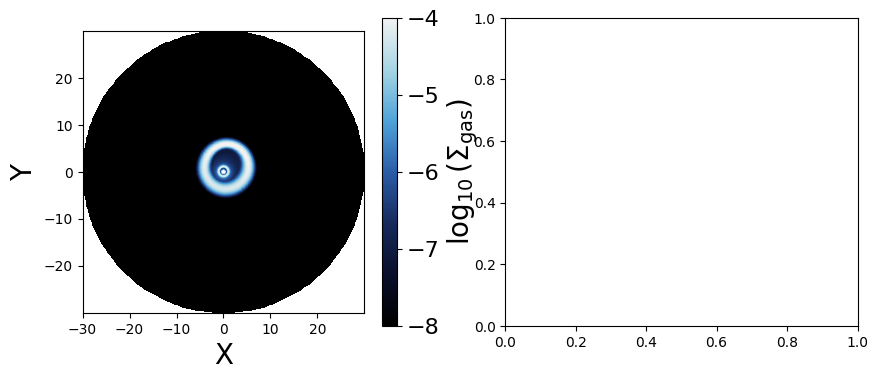

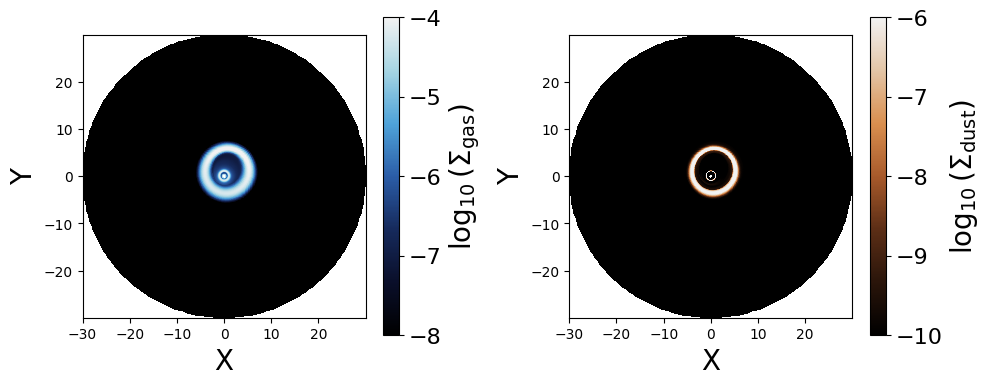

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_density(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))
    try:
        gasdens = loader.load_gasdens(orbit)
        vr_gas, vphi_gas = loader.load_gasvel(orbit)
        #print(max(vr_gas.flatten()), np.where(vr_gas == max(vr_gas.flatten())))
        #
        #pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-8, vmax=-4)
        pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap ,vmin = -8, vmax = -4)
        print("Gas density min/max:", np.nanmin(gasdens), np.nanmax(gasdens))

        cbar = gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        cbar.set_label(r'$\log_{10}(\Sigma_{\rm gas})$', fontsize=20)
        cbar.ax.tick_params(labelsize=16)
        gasax[0].set_xlabel('X', fontsize=20)
        gasax[0].set_ylabel('Y', fontsize=20)
        gasax[0].set_aspect('equal')
        #gasax[0].plot(r_grid[367] * np.cos(phi_grid[61]), r_grid[367] * np.sin(phi_grid[61]), '.')
        #gasax[0].plot(r_grid[365] * np.cos(phi_grid[61]), r_grid[365] * np.sin(phi_grid[61]), '.')

        dustdens = loader.load_dustdens(orbit, 1)
        pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-10, vmax=-6)
        cbar = gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        cbar.set_label(r'$\log_{10}(\Sigma_{\rm dust})$', fontsize=20)
        cbar.ax.tick_params(labelsize=16)
        gasax[1].set_xlabel('X', fontsize=20)
        gasax[1].set_ylabel('Y', fontsize=20)
        gasax[1].set_aspect('equal')
        plt.tight_layout()
    except Exception as e:
        print(e, "Dust density not available for this snapshot.")


path = '/project/phys-k/fargo_share/dustydisk_binary_St0.01_m0.5_nofb/'

path = '/project/phys-k/fargo_share/dustydisk_binary_St0.01_m0.5_nofb/'
path = '/project/phys-k/fargo_share/gasdisk_m0.5_CFL0.44_finedt/'

paths = ['/project/phys-k/fargo_share/gasdisk_m0.5/',
         '/project/phys-k/fargo_share/dustydisk_St0.01_m0.5/',
         '/project/phys-k/fargo_share/dustydisk_St0.01_m0.5_wfb/']

orbit = 9999
orbit = 341
#orbit = 600
dusttype = 'stokes'

for path in paths:
    single_snapshot_density(path, orbit, 'dust', 1)
# see at last snapshot for crashed sims
# reduce boundary
# find where gas is crashing in the binary sim

/tmp/ipykernel_2884533/3055879504.py:29: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  image = ax.pcolormesh(


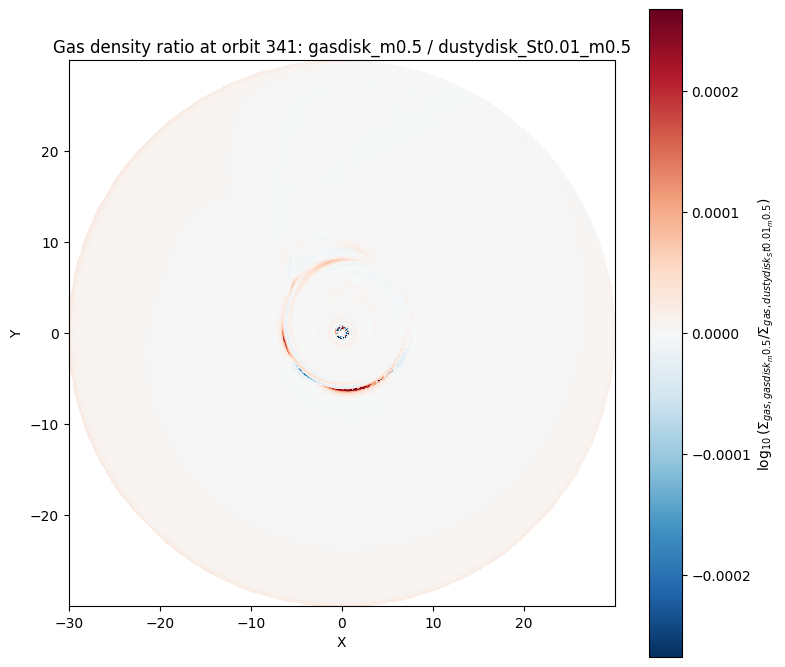

In [3]:
comparison_paths = paths
if len(comparison_paths) != 2:
    raise ValueError(f"Expected exactly two simulation paths, got {len(comparison_paths)}")

loader_a = SimulationDataLoader(comparison_paths[0])
loader_b = SimulationDataLoader(comparison_paths[1])
if loader_a.R.shape != loader_b.R.shape or not (
    np.allclose(loader_a.R, loader_b.R) and np.allclose(loader_a.PHI, loader_b.PHI)
):
    raise ValueError("The two simulations must use matching radial and azimuthal grids")

gasdens_a = loader_a.load_gasdens(orbit)
gasdens_b = loader_b.load_gasdens(orbit)
valid = (
    np.isfinite(gasdens_a)
    & np.isfinite(gasdens_b)
    & (gasdens_a > 0)
    & (gasdens_b > 0)
)
if not np.any(valid):
    raise ValueError("No finite, positive gas-density cells are available for the ratio")

log_density_ratio = np.full(gasdens_a.shape, np.nan, dtype=float)
log_density_ratio[valid] = np.log10(gasdens_a[valid] / gasdens_b[valid])
color_limit = max(float(np.nanpercentile(np.abs(log_density_ratio), 98)), 1e-12)
label_a, label_b = [path.rstrip("/").split("/")[-1] for path in comparison_paths]

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.pcolormesh(
    loader_a.X,
    loader_a.Y,
    log_density_ratio,
    cmap="RdBu_r",
    vmin=-color_limit,
    vmax=color_limit,
    shading="auto",
)
fig.colorbar(image, ax=ax, label=rf"$\log_{{10}}(\Sigma_{{gas,{label_a}}}/\Sigma_{{gas,{label_b}}})$")
ax.set(title=f"Gas density ratio at orbit {orbit}: {label_a} / {label_b}", xlabel="X", ylabel="Y")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

362107.871192719 (array([367]), array([61]))
-43903.73175893272 (array([365]), array([61]))
1.5663751701792017 1.552349621737202
v_kep = 0.799, 0.803
1.8708356808730102 (array([0]), array([44]))


/tmp/ipykernel_3889651/284446141.py:27: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, vr_gas, cmap=cmap,)
/tmp/ipykernel_3889651/284446141.py:36: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, vphi_gas, cmap=cmap_dust)


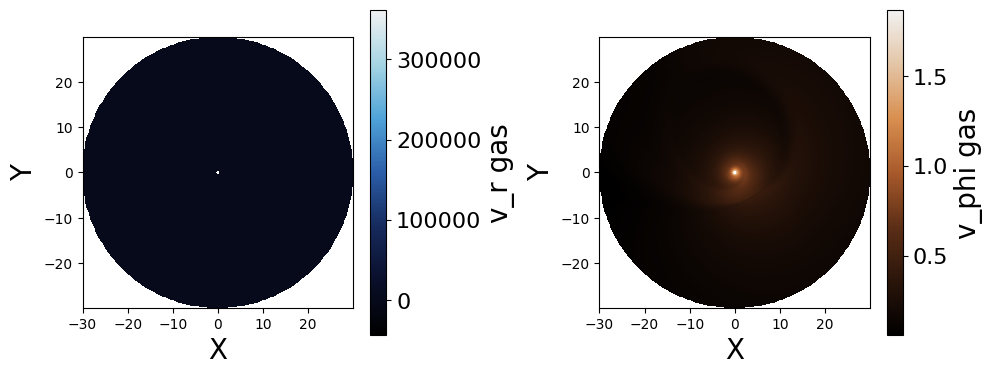

In [10]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_velocity(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(1, 2, figsize=(10, 4))

    gasdens = loader.load_gasdens(orbit)
    vr_gas, vphi_gas = loader.load_gasvel(orbit)
    print(max(vr_gas.flatten()), np.where(vr_gas == max(vr_gas.flatten())))
    print(min(vr_gas.flatten()), np.where(vr_gas == min(vr_gas.flatten())))
    r_grid = loader.r_grid
    print(r_grid[np.where(vr_gas == max(vr_gas.flatten()))[0][0]], r_grid[np.where(vr_gas == min(vr_gas.flatten()))[0][0]])
    print(f"v_kep = {np.sqrt(1 / r_grid[np.where(vr_gas == max(vr_gas.flatten()))[0][0]]):.3f}, {np.sqrt(1 / r_grid[np.where(vr_gas == min(vr_gas.flatten()))[0][0]]):.3f}")

    print(max(vphi_gas.flatten()), np.where(vphi_gas == max(vphi_gas.flatten())))
    pcm_gas = gasax[0].pcolormesh(loader.X, loader.Y, vr_gas, cmap=cmap,)
    cbar = gasfig.colorbar(pcm_gas, ax=gasax[0], label=r'v_r gas')
    cbar.set_label(r'v_r gas', fontsize=20)
    cbar.ax.tick_params(labelsize=16)
    gasax[0].set_xlabel('X', fontsize=20)
    gasax[0].set_ylabel('Y', fontsize=20)
    gasax[0].set_aspect('equal')


    pcm_dust = gasax[1].pcolormesh(loader.X, loader.Y, vphi_gas, cmap=cmap_dust)
    cbar = gasfig.colorbar(pcm_dust, ax=gasax[1], label=r'v_phi gas')
    cbar.set_label(r'v_phi gas', fontsize=20)
    cbar.ax.tick_params(labelsize=16)
    gasax[1].set_xlabel('X', fontsize=20)
    gasax[1].set_ylabel('Y', fontsize=20)
    gasax[1].set_aspect('equal')
    plt.tight_layout()

path = '/project/phys-k/fargo_share/gasdisk_m0.5_CFL0.44_finedt/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0001/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 9999
#orbit = 11
dusttype = 'stokes'
single_snapshot_velocity(path, orbit, 'dust', 1)
# see at last snapshot for crashed sims
# reduce boundary
# find where gas is crashing in the binary sim
# 0.67116889

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\utils\visualization.py:53: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_gas = ax[0].pcolormesh(
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\utils\visualization.py:57: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = ax[1].pcolormesh(
MovieWriter ffmpeg unavailable; using Pillow instead.


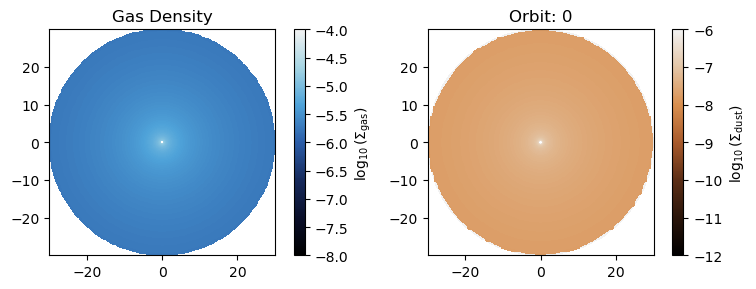

In [37]:
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.01_m0.3/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbits = np.arange(0, 20, 1)

loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
animation_dust_gas = animate_dust_gas(loader, variables, 1)
animation_dust_gas.create_animation(orbits)

C:\Users\david\AppData\Local\Temp\ipykernel_11632\755843083.py:14: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm_dust = gasax.pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-8, vmax=-2)


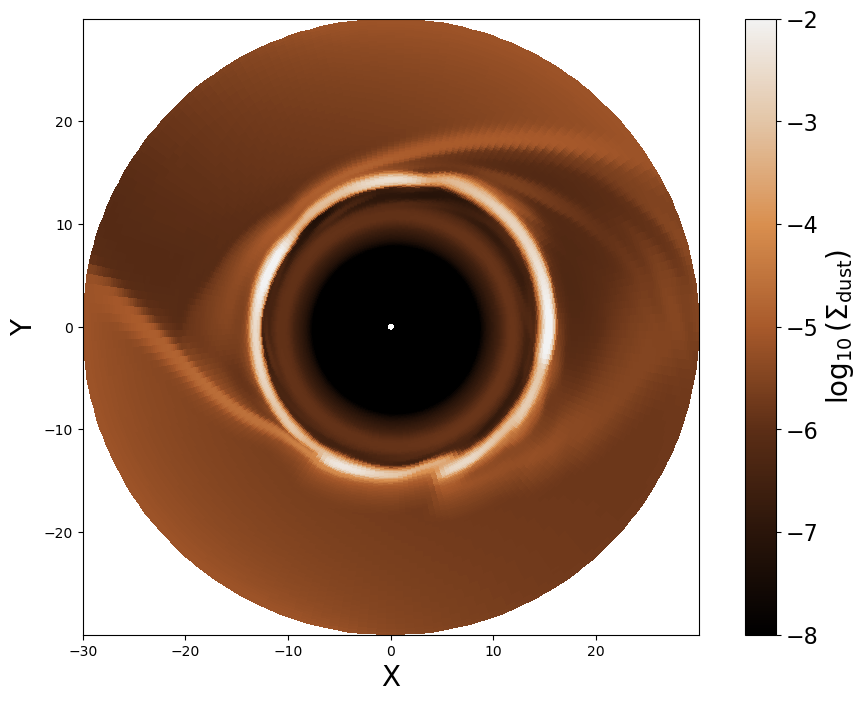

In [17]:
from analysis.orbital import fit_ellipse_polar, polar_ellipse
def single_snapshot_streamline(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    phi_grid = loader.phi_grid
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    gasfig, gasax = plt.subplots(figsize=(12, 8))
    dustdens = loader.load_dustdens(orbit, 1)

    pcm_dust = gasax.pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap_dust, vmin=-8, vmax=-2)
    cbar = gasfig.colorbar(pcm_dust, ax=gasax, label=r'$\log_{10}(\Sigma_{\rm dust})$')
    cbar.set_label(r'$\log_{10}(\Sigma_{\rm dust})$', fontsize=20)
    cbar.ax.tick_params(labelsize=16)
    gasax.set_xlabel('X', fontsize=20)
    gasax.set_ylabel('Y', fontsize=20)
    gasax.set_aspect('equal')

    #streamline = streamlines.get_streamline(13, 0, orbit, 'dust', 1)
    #a, e, varpi = fit_ellipse_polar(streamline, phi_grid)
    #streamline = polar_ellipse(phi_grid, a, e, varpi)
    #x, y = streamline * np.cos(phi_grid), streamline * np.sin(phi_grid)
    #gasax.plot(x, y, 'cyan')

    #streamline = streamlines.get_streamline(15, 0, orbit, 'dust', 1)
    #a, e, varpi = fit_ellipse_polar(streamline, phi_grid)
    #streamline = polar_ellipse(phi_grid, a, e, varpi)
    #x, y = streamline * np.cos(phi_grid), streamline * np.sin(phi_grid)
    #gasax.plot(x, y, 'magenta')


path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002_nooutdamptest/'

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 30
dusttype = 'stokes'
single_snapshot_streamline(path, orbit, 'dust', 1)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


-4.077567376664199e-14 1.8236690283609605


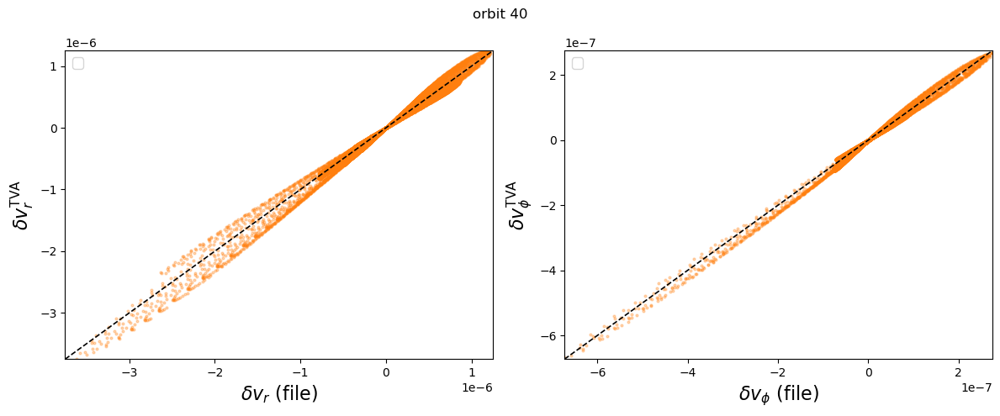

In [13]:
def plot_delta_v_xy_scatter(path, orbit, material, dust_num, dusttype,
                             a_min=1, a_max=15, s=4, alpha=0.3):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    # TVA prescription (reference / y-axis)
    a_map_tva, _, dvr_tva, dvphi_tva = da_dt.compute_da_dt_mass_flux(orbit, material, 'drag')

    # File output (x-axis): direct dust - gas velocity difference from the binary files
    vr_gas, vphi_gas = loader.load_gasvel(orbit)
    vr_dust, vphi_dust = loader.load_dustvel(orbit, dust_num)
    dvr_file = vr_dust - vr_gas
    dvphi_file = vphi_dust - vphi_gas

    a_flat = a_map_tva.flatten()
    in_range = np.isfinite(a_flat) & (a_flat > a_min) & (a_flat < a_max)

    x_r, y_r = dvr_file.flatten(), dvr_tva.flatten()
    valid_r = in_range & np.isfinite(x_r) & np.isfinite(y_r)

    x_phi, y_phi = dvphi_file.flatten(), dvphi_tva.flatten()
    valid_phi = in_range & np.isfinite(x_phi) & np.isfinite(y_phi)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.scatter(x_r[valid_r], y_r[valid_r], s=s, alpha=alpha, color='tab:orange')
    lims_r = [min(x_r[valid_r].min(), y_r[valid_r].min()),
              max(x_r[valid_r].max(), y_r[valid_r].max())]
    ax1.plot(lims_r, lims_r, 'k--', lw=1.2)
    ax1.set_xlim(lims_r); ax1.set_ylim(lims_r)
    ax1.set_xlabel(r'$\delta v_r$ (file)', fontsize=16)
    ax1.set_ylabel(r'$\delta v_r^{\rm TVA}$', fontsize=16)
    ax1.legend(fontsize=12)

    ax2.scatter(x_phi[valid_phi], y_phi[valid_phi], s=s, alpha=alpha, color='tab:orange')
    lims_phi = [min(x_phi[valid_phi].min(), y_phi[valid_phi].min()),
                max(x_phi[valid_phi].max(), y_phi[valid_phi].max())]
    ax2.plot(lims_phi, lims_phi, 'k--', lw=1.2)
    ax2.set_xlim(lims_phi); ax2.set_ylim(lims_phi)
    ax2.set_xlabel(r'$\delta v_\phi$ (file)', fontsize=16)
    ax2.set_ylabel(r'$\delta v_\phi^{\rm TVA}$', fontsize=16)
    ax2.legend(fontsize=12)

    fig.suptitle(f'orbit {orbit}')
    plt.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002/'
orbit = 40
dusttype = 'stokes'
plot_delta_v_xy_scatter(path, orbit, 'dust', 1, dusttype)

-4.077567376664199e-14 1.8236690283609605


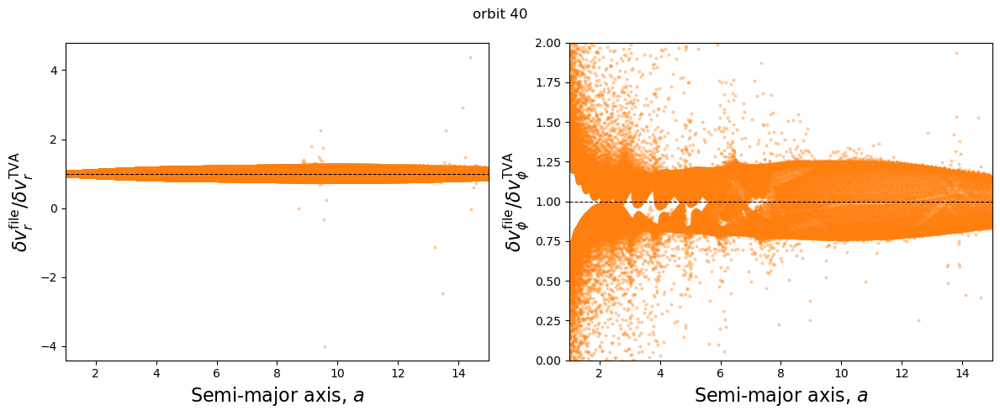

In [17]:
def plot_delta_v_ratio_vs_a_scatter(path, orbit, material, dust_num, dusttype,
                                     a_min=1, a_max=15, s=4, alpha=0.3):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    # TVA prescription (reference / denominator)
    a_map_tva, _, dvr_tva, dvphi_tva = da_dt.compute_da_dt_mass_flux(orbit, material, 'drag')

    # File output (numerator): direct dust - gas velocity difference from the binary files
    vr_gas, vphi_gas = loader.load_gasvel(orbit)
    vr_dust, vphi_dust = loader.load_dustvel(orbit, dust_num)
    dvr_file = vr_dust - vr_gas
    dvphi_file = vphi_dust - vphi_gas

    a_flat = a_map_tva.flatten()
    in_range = np.isfinite(a_flat) & (a_flat > a_min) & (a_flat < a_max)

    ratio_r = (dvr_file / dvr_tva).flatten()
    ratio_phi = (dvphi_file / dvphi_tva).flatten()

    valid_r = in_range & np.isfinite(ratio_r)
    valid_phi = in_range & np.isfinite(ratio_phi)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

    ax1.scatter(a_flat[valid_r], ratio_r[valid_r], s=s, alpha=alpha, color='tab:orange')
    ax1.axhline(1, color='k', lw=0.8, ls='--')
    ax1.set_xlabel('Semi-major axis, $a$', fontsize=16)
    ax1.set_ylabel(r'$\delta v_r^{\rm file} / \delta v_r^{\rm TVA}$', fontsize=16)
    ax1.set_xlim(a_min, a_max)

    ax2.scatter(a_flat[valid_phi], ratio_phi[valid_phi], s=s, alpha=alpha, color='tab:orange')
    ax2.axhline(1, color='k', lw=0.8, ls='--')
    ax2.set_xlabel('Semi-major axis, $a$', fontsize=16)
    ax2.set_ylabel(r'$\delta v_\phi^{\rm file} / \delta v_\phi^{\rm TVA}$', fontsize=16)
    ax2.set_xlim(a_min, a_max)
    ax2.set_ylim(0, 2)

    fig.suptitle(f'orbit {orbit}')
    plt.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002/'
orbit = 40
dusttype = 'stokes'
plot_delta_v_ratio_vs_a_scatter(path, orbit, 'dust', 1, dusttype)

Stopping time: 0.00010146473984204257 300832.4107444881
Stokes: 0.0006009245733892639-2753.5133644023963
-5.684341886080802e-14 1.6208864505079816


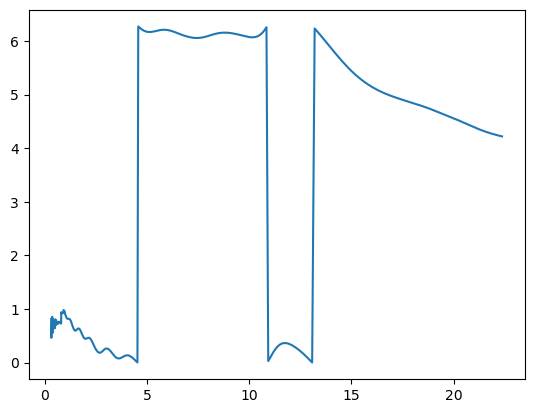

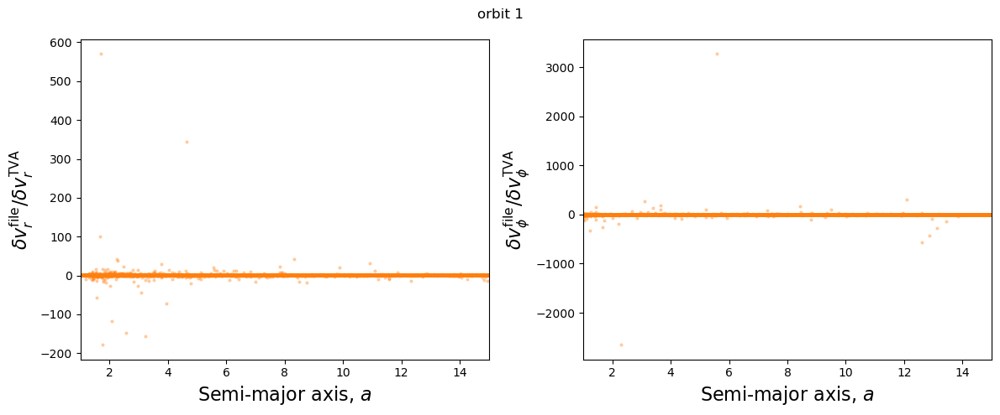

Stopping time: 0.00010146473984204257 300832.4107444881
Stokes: 0.0006009245733892639-2753.5133644023963
-5.684341886080802e-14 1.6208864505079816


C:\Users\david\AppData\Local\Temp\ipykernel_24356\4197537576.py:106: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(loader.X, loader.Y, data, cmap=cmap, norm=norm)


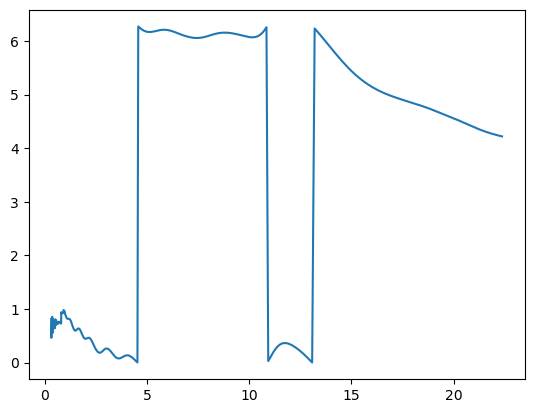

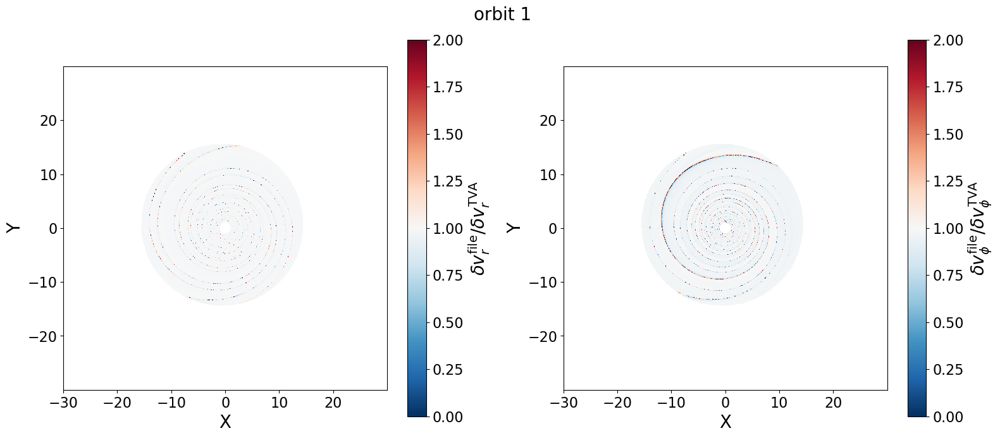

Stopping time: 0.00010146473984204257 300832.4107444881
Stokes: 0.0006009245733892639-2753.5133644023963
-5.684341886080802e-14 1.6208864505079816


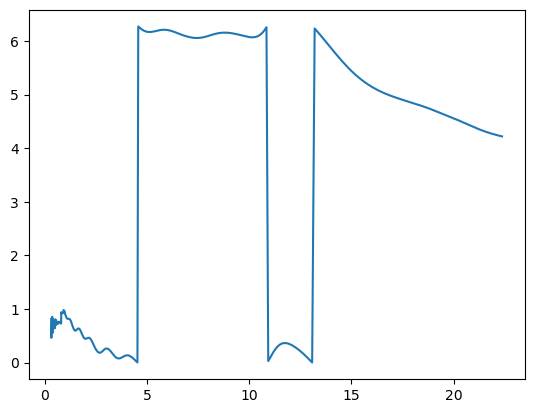

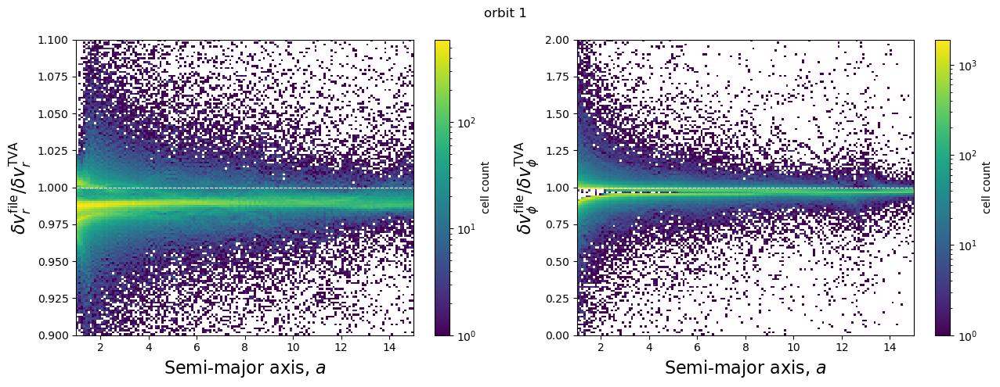

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LogNorm

# Assumes these are already defined/imported in your environment:
# SimulationDataLoader, SimulationVariablesCalculator,
# SimulationDataStreamlines, da_dt_calculator

RATIO_LABELS = (r'$\delta v_r^{\rm file}/\delta v_r^{\rm TVA}$',
                r'$\delta v_\phi^{\rm file}/\delta v_\phi^{\rm TVA}$')





def _compute_ratios(path, orbit, material, dust_num, dusttype):
    """Load data once and return (loader, a_map, ratio_r, ratio_phi).

    ratio = (dust - gas velocity from files) / (TVA drag prescription)
    """
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    # TVA prescription (reference / denominator)
    a_map, _, dvr_tva, dvphi_tva = da_dt.compute_da_dt_mass_flux(orbit, material, 'drag')

    # File output (numerator): direct dust - gas velocity difference
    vr_gas, vphi_gas = loader.load_gasvel(orbit)
    vr_dust, vphi_dust = loader.load_dustvel(orbit, dust_num)

    ratio_r = (vr_dust - vr_gas) / dvr_tva
    ratio_phi = (vphi_dust - vphi_gas) / dvphi_tva
    return loader, a_map, ratio_r, ratio_phi


def plot_delta_v_ratio_vs_a_scatter(path, orbit, material, dust_num, dusttype,
                                    a_min=1, a_max=15, s=4, alpha=0.3):
    _, a_map, ratio_r, ratio_phi = _compute_ratios(path, orbit, material, dust_num, dusttype)

    a_flat = a_map.flatten()
    in_range = np.isfinite(a_flat) & (a_flat > a_min) & (a_flat < a_max)

    ratio_r = ratio_r.flatten()
    ratio_phi = ratio_phi.flatten()
    valid_r = in_range & np.isfinite(ratio_r)
    valid_phi = in_range & np.isfinite(ratio_phi)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

    ax1.scatter(a_flat[valid_r], ratio_r[valid_r], s=s, alpha=alpha, color='tab:orange')
    #ax1.axhline(1, color='k', lw=0.8, ls='--')
    ax1.set_xlabel('Semi-major axis, $a$', fontsize=16)
    ax1.set_ylabel(RATIO_LABELS[0], fontsize=16)
    ax1.set_xlim(a_min, a_max)

    ax2.scatter(a_flat[valid_phi], ratio_phi[valid_phi], s=s, alpha=alpha, color='tab:orange')
    #ax2.axhline(1, color='k', lw=0.8, ls='--')
    ax2.set_xlabel('Semi-major axis, $a$', fontsize=16)
    ax2.set_ylabel(RATIO_LABELS[1], fontsize=16)
    ax2.set_xlim(a_min, a_max)
    #ax2.set_ylim(0, 2)

    fig.suptitle(f'orbit {orbit}')
    plt.tight_layout()
    plt.show()


def plot_delta_v_ratio_hist2d(path, orbit, material, dust_num, dusttype,
                              a_min=1, a_max=15, bins=(150, 150),
                              r_ylim=(0.9, 1.1), phi_ylim=(0, 2)):
    """2D density of ratio vs a (alternative to the overplotted scatter)."""
    _, a_map, ratio_r, ratio_phi = _compute_ratios(path, orbit, material, dust_num, dusttype)
    a_flat = a_map.flatten()
    in_range = np.isfinite(a_flat) & (a_flat > a_min) & (a_flat < a_max)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
    for ax, ratio, ylim, lab in zip(
            axes, (ratio_r.flatten(), ratio_phi.flatten()), (r_ylim, phi_ylim), RATIO_LABELS):
        ok = in_range & np.isfinite(ratio)

        h = ax.hist2d(a_flat[ok], ratio[ok], bins=bins,
                      range=[[a_min, a_max], list(ylim)],
                      cmap='viridis', norm=LogNorm())
        fig.colorbar(h[3], ax=ax, label='cell count')
        ax.axhline(1, color='w', lw=0.8, ls='--')
        ax.set_xlabel('Semi-major axis, $a$', fontsize=16)
        ax.set_ylabel(lab, fontsize=16)
    fig.suptitle(f'orbit {orbit}')
    plt.tight_layout()
    plt.show()


def plot_delta_v_ratio_xy(path, orbit, material, dust_num, dusttype,
                          a_min=1, a_max=15, vmin=0, vmax=2, cmap='RdBu_r'):
    """Face-on X-Y maps of the file/TVA velocity ratios."""
    loader, a_map, ratio_r, ratio_phi = _compute_ratios(path, orbit, material, dust_num, dusttype)

    mask = ~(np.isfinite(a_map) & (a_map > a_min) & (a_map < a_max))
    norm = TwoSlopeNorm(vcenter=1, vmin=vmin, vmax=vmax)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, ratio, lab in zip(axes, (ratio_r, ratio_phi), RATIO_LABELS):
        data = np.ma.masked_where(mask | ~np.isfinite(ratio), ratio)
        pcm = ax.pcolormesh(loader.X, loader.Y, data, cmap=cmap, norm=norm)
        cbar = fig.colorbar(pcm, ax=ax)
        cbar.set_label(lab, fontsize=20)
        cbar.ax.tick_params(labelsize=16)
        ax.set_xlabel('X', fontsize=20)
        ax.set_ylabel('Y', fontsize=20)
        ax.tick_params(labelsize=16)
        ax.set_aspect('equal')

    fig.suptitle(f'orbit {orbit}', fontsize=20)
    plt.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.0002/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.00004_nooutdamptest_outflow/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_contd_nr1024/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_size_eps0.01_1024x400/'
orbit = 1
dusttype = 'particle'

plot_delta_v_ratio_vs_a_scatter(path, orbit, 'dust', 1, dusttype)
plot_delta_v_ratio_xy(path, orbit, 'dust', 1, dusttype)
#for o in range(1, 18):
plot_delta_v_ratio_hist2d(path, orbit, 'dust', 1, dusttype)  # optional

# compare stopping time
# reduce viscosity

# do shorter runs - turn off feedback
# expand range of Stokes number (go super low and higher)
# change resolution - increase and decrease

# change epsilon
# run simulation for longer to see if issue is purely resolution-dependent
# change azimuthal resolution


-3.322329850866929 6.51954646353812


C:\Users\david\AppData\Local\Temp\ipykernel_12468\3082349837.py:18: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  ax.pcolormesh(loader.X, loader.Y, da_dt_map, cmap='RdBu_r', vmin=-1e-6, vmax=1e-6)
C:\Users\david\AppData\Local\Temp\ipykernel_12468\3082349837.py:19: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  cbar = fig.colorbar(ax.pcolormesh(loader.X, loader.Y, da_dt_map, cmap='RdBu_r', vmin=-1e-6, vmax=1e-6), ax=ax)


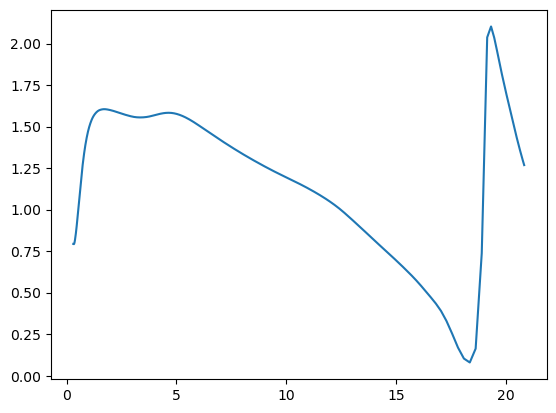

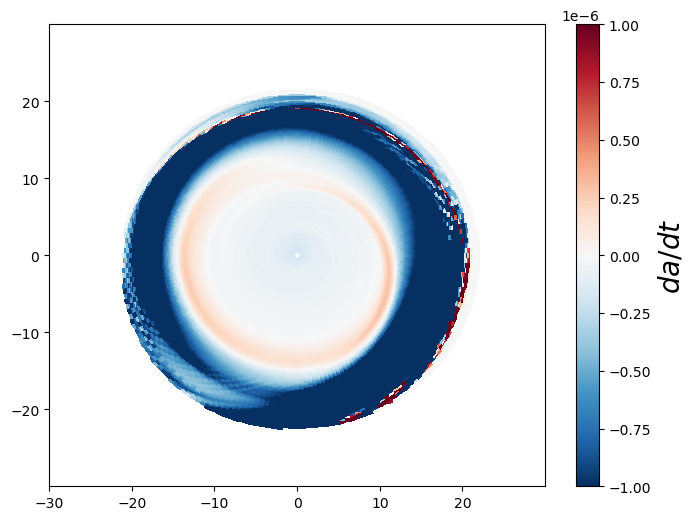

In [2]:
# %reload_ext autoreload
# %autoreload 2

def make_nabla_a_2d_plot(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    method = 'sim'

    a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, 'dust', method)

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.pcolormesh(loader.X, loader.Y, da_dt_map, cmap='RdBu_r', vmin=-1e-6, vmax=1e-6)
    cbar = fig.colorbar(ax.pcolormesh(loader.X, loader.Y, da_dt_map, cmap='RdBu_r', vmin=-1e-6, vmax=1e-6), ax=ax)
    cbar.set_label(r'$da/dt$', fontsize=20)

path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.00004_nooutdamptest_outflow/'
orbit = 40
dust_num = 1
dusttype = 'stokes'

make_nabla_a_2d_plot(path, orbit)
    

-3.322329850866929 6.51954646353812


(<Figure size 800x500 with 1 Axes>,
 <Axes: xlabel='$\\phi$ [rad]', ylabel='$da/dt$'>)

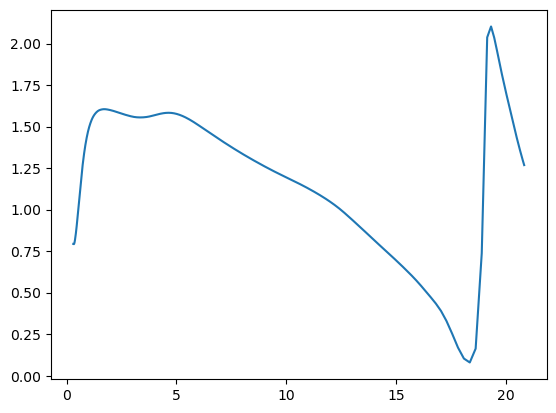

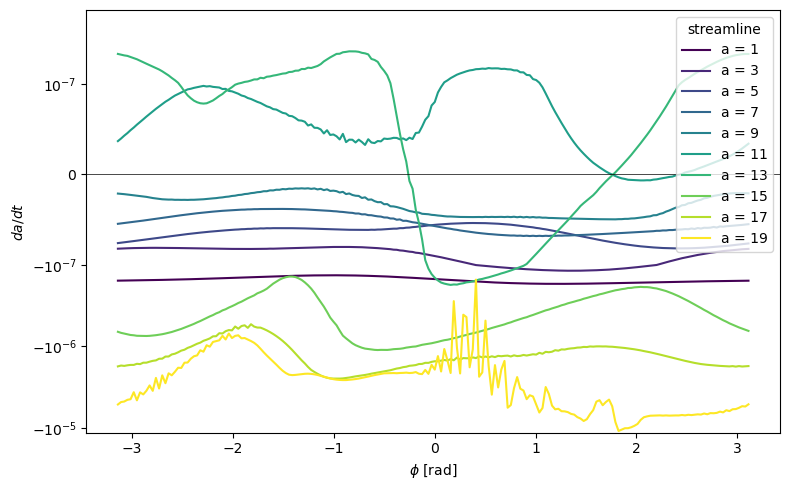

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def da_dt_along_streamline(a_map, da_dt_map, a_target):
    """Return da/dt on the streamline a = a_target, one value per phi column.
    Assumes arrays are shaped (Nr, Nphi), i.e. same layout as loader.X / loader.Y."""
    n_phi = a_map.shape[1]
    out = np.full(n_phi, np.nan)
    for j in range(n_phi):
        a_col = a_map[:, j]
        d_col = da_dt_map[:, j]
        good = np.isfinite(a_col) & np.isfinite(d_col)
        if good.sum() < 2:
            continue
        a_g, d_g = a_col[good], d_col[good]
        order = np.argsort(a_g)          # np.interp needs increasing x
        a_g, d_g = a_g[order], d_g[order]
        if a_g[0] <= a_target <= a_g[-1]:  # skip columns that don't bracket a_target
            out[j] = np.interp(a_target, a_g, d_g)
    return out


def make_da_dt_vs_phi_plot(path, orbit, a_targets):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num, dusttype)

    a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, 'dust', 'sim')

    # phi axis: take it from any radial row of the mesh
    phi = np.arctan2(loader.Y[0, :], loader.X[0, :])
    order = np.argsort(phi)
    phi = phi[order]

    fig, ax = plt.subplots(figsize=(8, 5))
    colors = plt.cm.viridis(np.linspace(0, 1, len(a_targets)))
    for a_t, c in zip(a_targets, colors):
        y = da_dt_along_streamline(a_map, da_dt_map, a_t)[order]
        ax.plot(phi, y, color=c, label=f'a = {a_t:g}')

    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel(r'$\phi$ [rad]')
    ax.set_ylabel(r'$da/dt$')
    ax.legend(title='streamline')
    ax.set_yscale('symlog', linthresh=1e-7)
    fig.tight_layout()
    return fig, ax

# pick a values that span your disk, e.g. 5 values between the inner/outer region of interest
a_targets = np.arange(1, 20, 2)
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St0.00004_nooutdamptest_outflow/'
orbit = 40
dust_num = 1
dusttype = 'stokes'
make_da_dt_vs_phi_plot(path, orbit, a_targets=a_targets)

# 0.0001cm-sized particles - Axisymmetric Disk

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital.py:66: SyntaxWarning: invalid escape sequence '\o'
  """
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:331: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  print('median v_K llambay:', np.nanmedian(v_K))


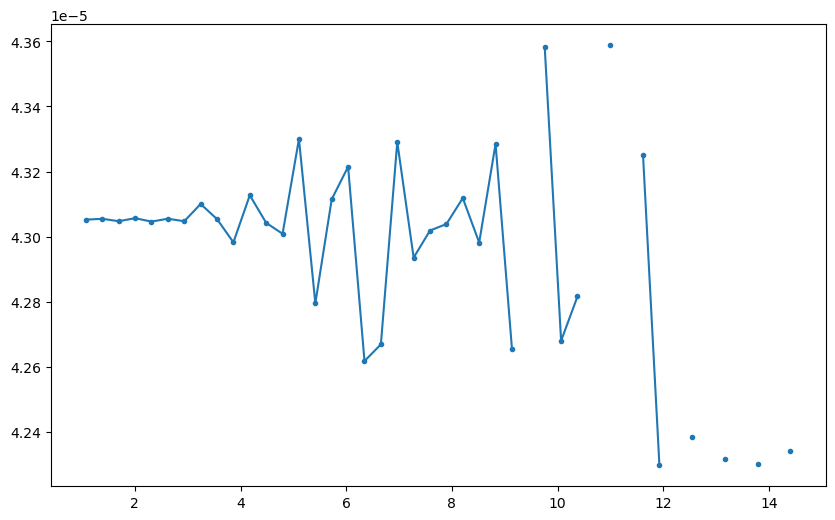

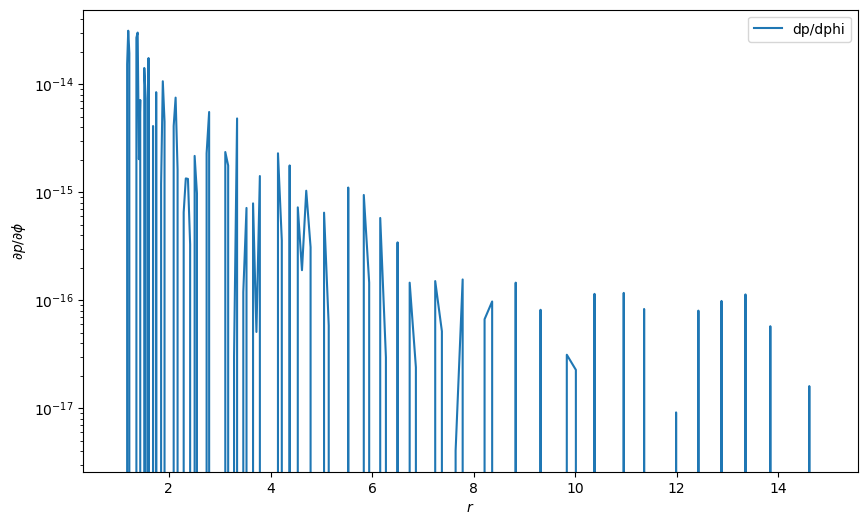

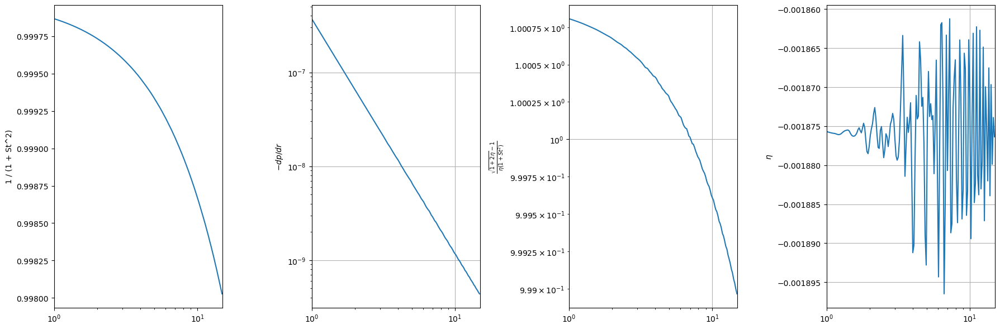

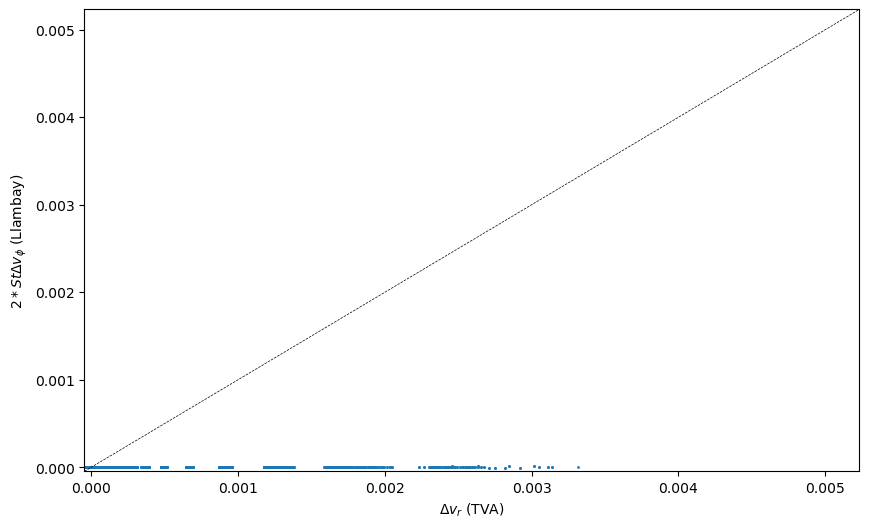

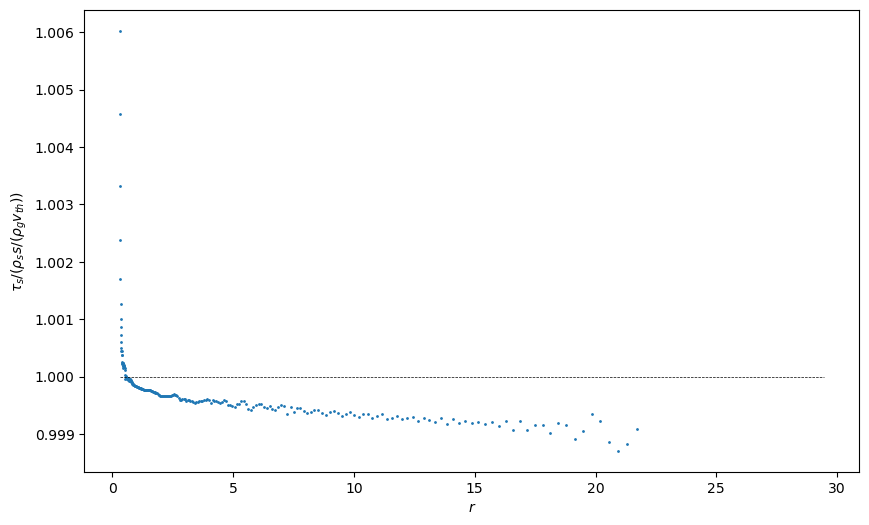

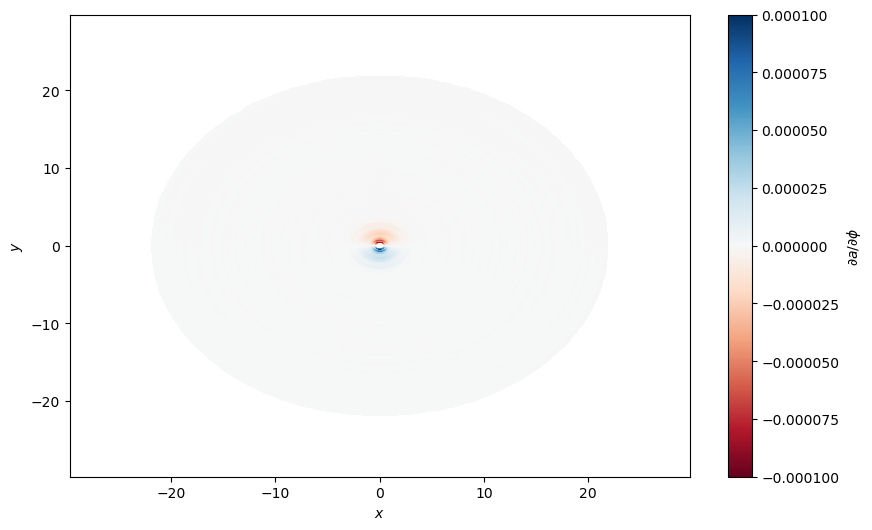

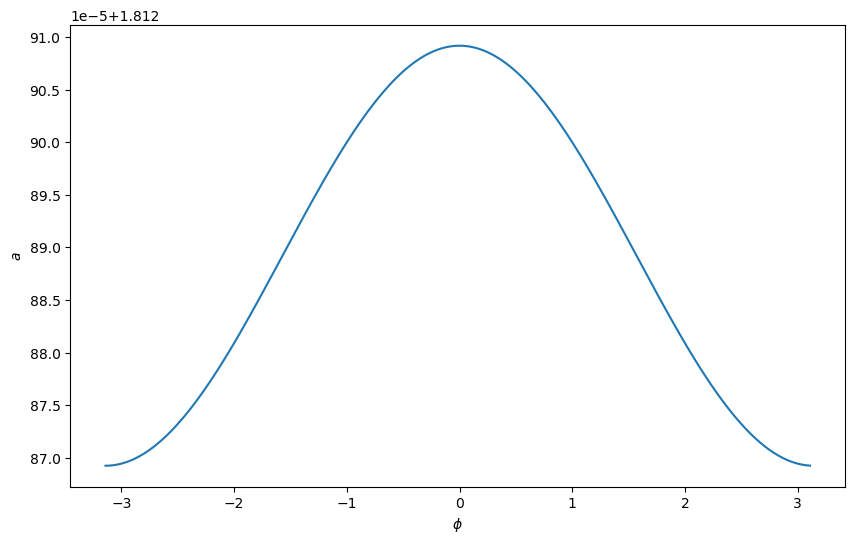

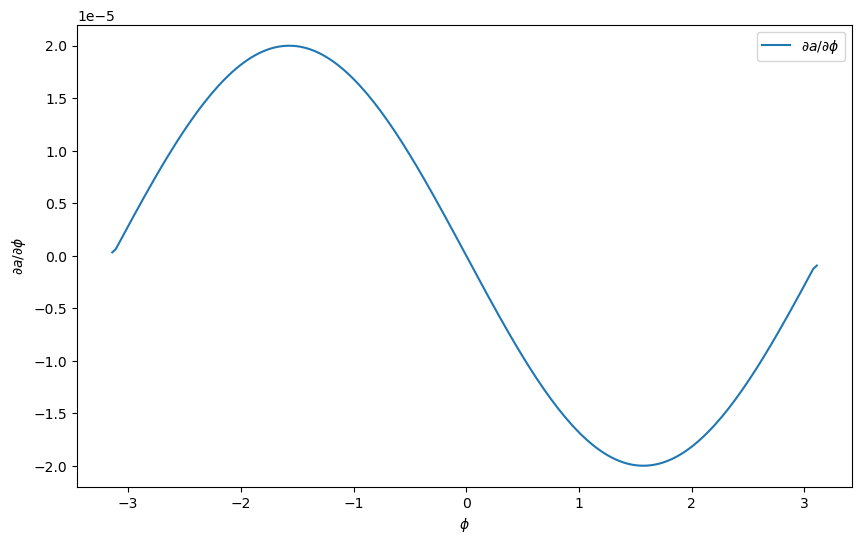

median phi term llambay: -0.0009491055410165504
median first phi term llambay: -0.0009491055415140714
median second phi term llambay: 4.0156764452204565e-13
median v_K llambay: 0.6232278863933868
median eta llambay: -0.0018747628191798488
1.0004058561731175


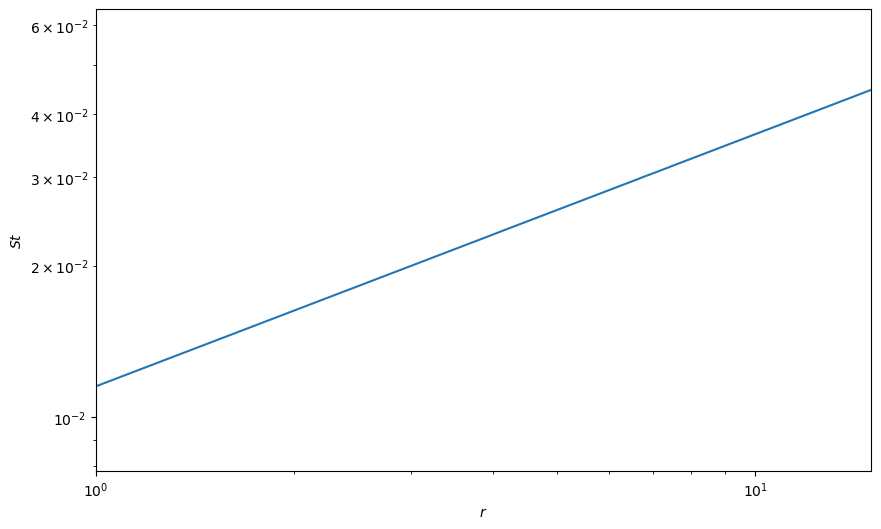

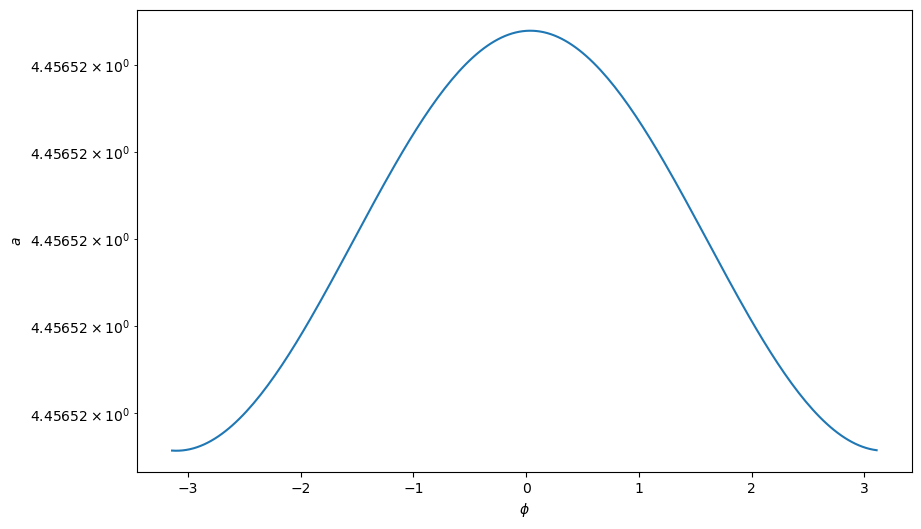

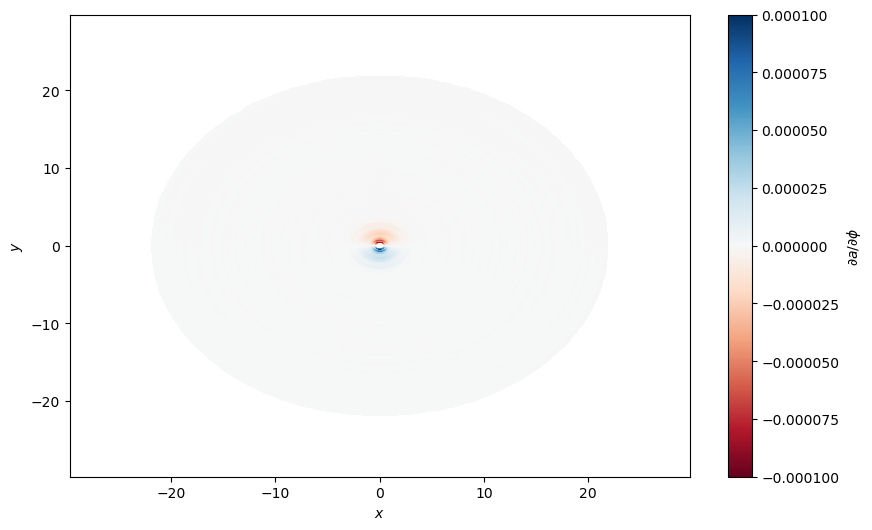

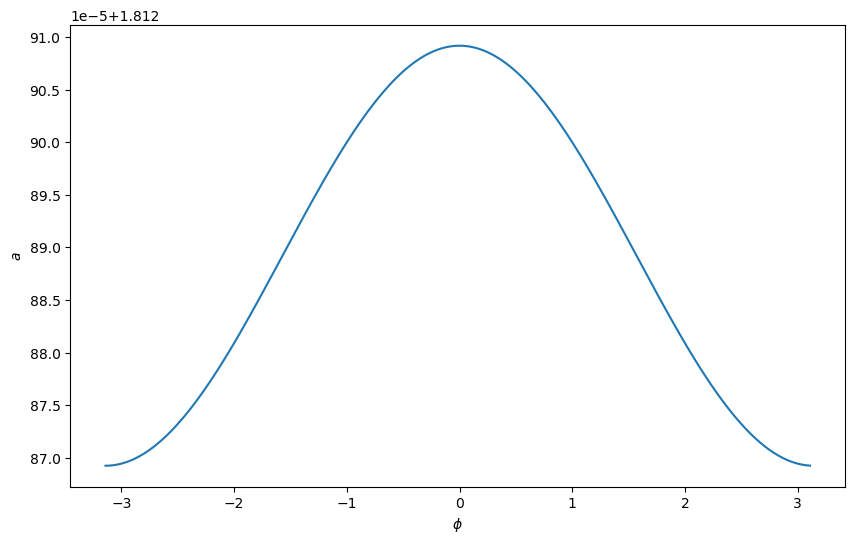

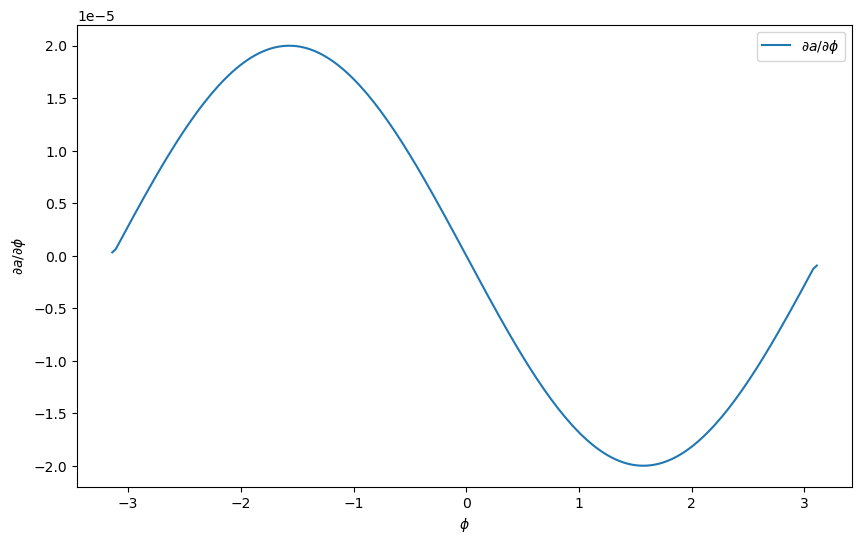

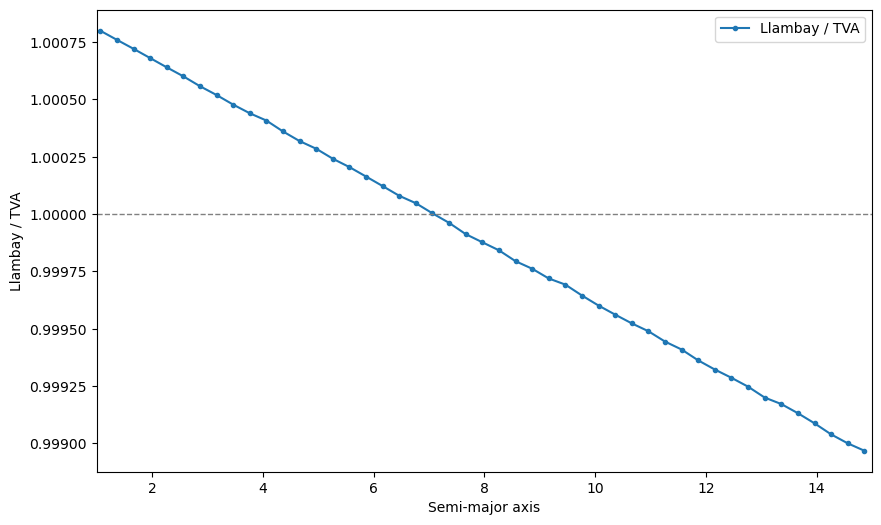

In [20]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    #methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    methods = ['drag', 'llambay']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        #centers, means = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        results[m] = (centers, means)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(1, 15)
    ax1.legend()

    # --- Ratio: Llambay / TVA(drag) ---
    centers_drag, means_drag = results['drag']
    centers_llambay, means_llambay = results['llambay']

    # interpolate llambay onto drag's bin centers (or pick whichever range you prefer)
    means_llambay_interp = np.interp(centers_drag, centers_llambay, means_llambay,
                                      left=np.nan, right=np.nan)

    ratio = means_llambay_interp / means_drag

    fig3, ax3 = plt.subplots(1, 1, figsize=(10, 6))
    mask_ratio = (centers_drag > 1) & (centers_drag < 15)
    ax3.plot(centers_drag[mask_ratio], ratio[mask_ratio], '.-', label='Llambay / TVA')
    ax3.axhline(1, color='gray', ls='--', lw=1)
    ax3.set_xlabel('Semi-major axis')
    ax3.set_ylabel('Llambay / TVA')
    ax3.set_xlim(1, 15)
    ax3.legend()

    return fig1, ax1, fig3, ax3


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 8
fig1, ax1, fig3, ax3 = single_snapshot_compare(path, orbit, 'dust', 1)

median phi term llambay: -0.0009491059371103027
median first phi term llambay: -0.0009491059376078593
median second phi term llambay: 4.0156764452221175e-13
median v_K llambay: 0.6232278739046226
median eta llambay: -0.0018747628191798488
1.0004058561731177


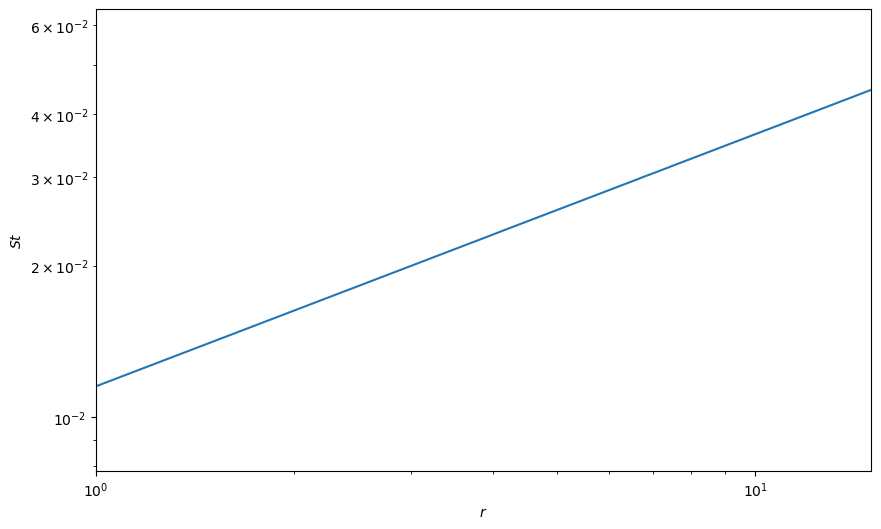

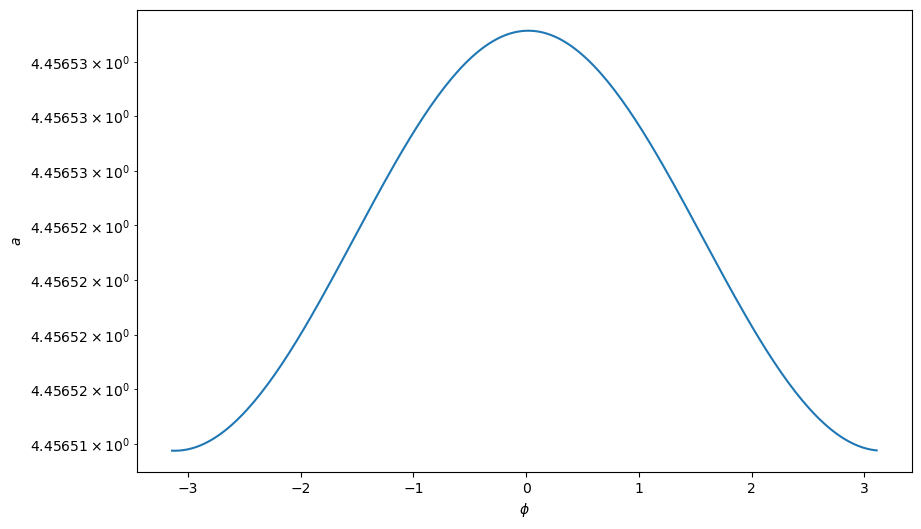

In [19]:
%reload_ext autoreload
%autoreload 2
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alpha1e-3_test2/'
orbit = 8
loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
streamlines = SimulationDataStreamlines(loader, variables)
method = 'sim'
rvc = relative_velocity_calculator(loader, variables, streamlines, 1, method)
da_dt = da_dt_calculator(loader, variables, streamlines, 1)

a_map_llambay, delta_v_r_llambay, delta_v_phi_llambay = da_dt.compute_da_dt_llambay(orbit)

In [121]:
%reload_ext autoreload
%autoreload 2

loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
streamlines = SimulationDataStreamlines(loader, variables)
method = 'sim'
rvc = relative_velocity_calculator(loader, variables, streamlines, 1, method)
da_dt = da_dt_calculator(loader, variables, streamlines, 1)

a_map_drag, delta_v_r_drag, delta_v_phi_drag = da_dt.velocity_from_epstein_drag(orbit, 'dust', 'drag')
a_map_llambay, delta_v_r_llambay, delta_v_phi_llambay = da_dt.compute_da_dt_llambay(orbit)

# same a_map, so directly comparable elementwise
print("median |delta_v_r| ratio (llambay/drag):", np.nanmedian(np.abs(delta_v_r_llambay)/np.abs(delta_v_r_drag)))
print("median |delta_v_phi| ratio (llambay/drag):", np.nanmedian(np.abs(delta_v_phi_llambay)/np.abs(delta_v_phi_drag)))

da_dr = np.gradient(a_map_drag, loader.r_grid, axis=0)
da_dphi = np.gradient(a_map_drag, loader.phi_grid, axis=1)

term_r_drag = da_dr * delta_v_r_drag
term_phi_drag = da_dphi * delta_v_phi_drag / loader.r_grid[:, None]
term_r_llambay = da_dr * delta_v_r_llambay
term_phi_llambay = da_dphi * delta_v_phi_llambay / loader.r_grid[:, None]

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.scatter(delta_v_phi_drag.flatten(), delta_v_phi_llambay.flatten(), s=0.5, alpha=0.5)
ax.set_xlabel(r'$\Delta v_\phi$ (TVA)')
ax.set_ylabel(r'$\Delta v_\phi$ (Llambay et al. 19)')

print("median |radial term| drag vs llambay:", np.nanmedian(np.abs(term_r_drag)), np.nanmedian(np.abs(term_r_llambay)))
print("median |phi term| drag vs llambay:", np.nanmedian(np.abs(term_phi_drag)), np.nanmedian(np.abs(term_phi_llambay)))

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
mask = (loader.r_grid > 1) & (loader.r_grid < 15)
ax.plot(loader.r_grid[mask], -np.nanmedian(term_phi_drag, axis=1)[mask], label='drag phi term')
ax.plot(loader.r_grid[mask], -np.nanmedian(term_phi_llambay, axis=1)[mask], label='llambay phi term')
ax.set_xlabel(r'$r$')
ax.set_ylabel(r'$-v_{\phi} /r \partial a / \partial \phi$')
ax.set_yscale('log')
ax.legend()

print('median da/dphi / r value:', np.nanmedian(da_dphi / loader.r_grid[:, None]))
print('median da/dr value:', np.nanmedian(da_dr))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alpha1e-3_test6/dust1vy1.dat'

# 0.1cm-sized particles - Axisymmetric Disk

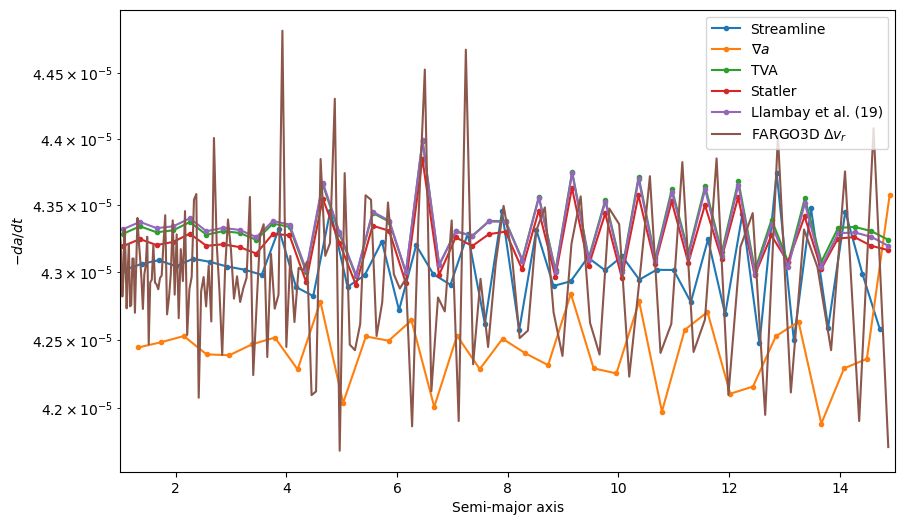

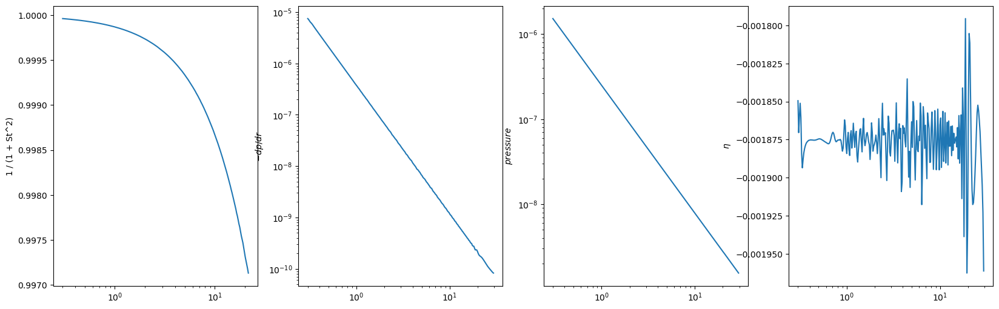

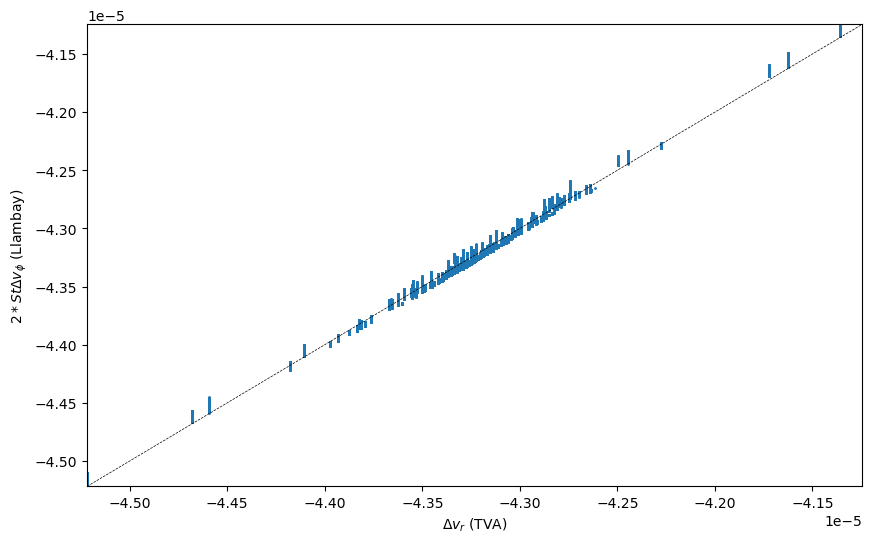

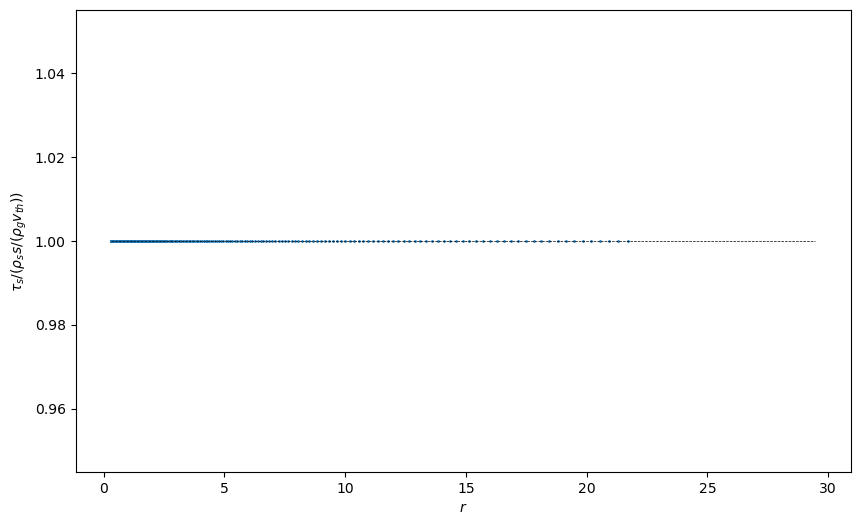

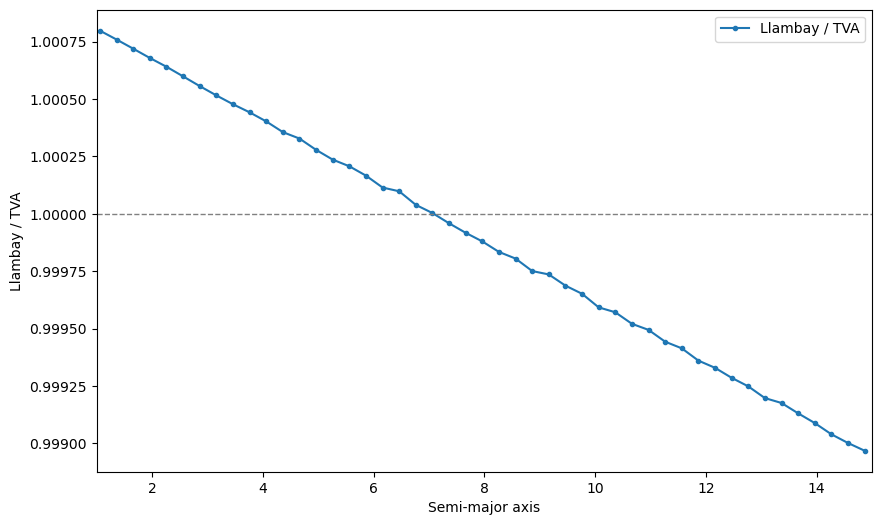

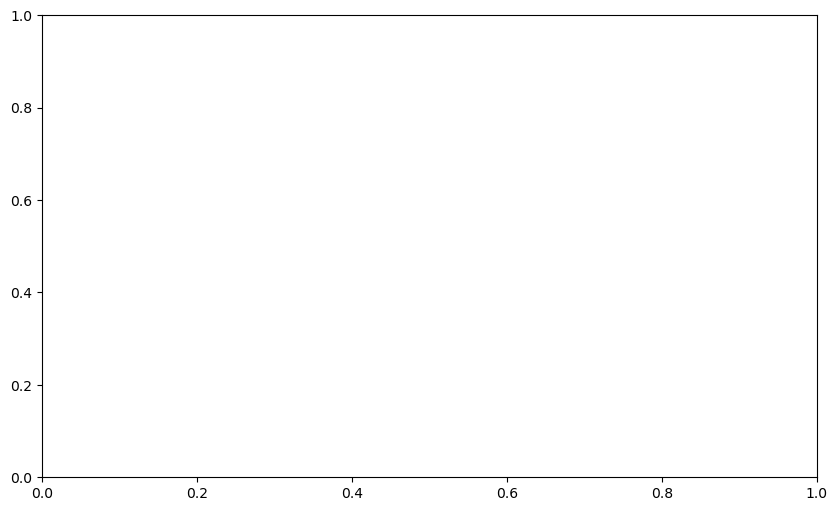

In [37]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    #methods = ['drag', 'llambay']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        #centers, means = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        results[m] = (centers, means)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(1, 15)
    ax1.legend()

    # --- Ratio: Llambay / TVA(drag) ---
    centers_drag, means_drag = results['drag']
    centers_llambay, means_llambay = results['llambay']


    # interpolate llambay onto drag's bin centers (or pick whichever range you prefer)
    means_llambay_interp = np.interp(centers_drag, centers_llambay, means_llambay,
                                      left=np.nan, right=np.nan)

    ratio = means_llambay_interp / means_drag

    fig3, ax3 = plt.subplots(1, 1, figsize=(10, 6))
    mask_ratio = (centers_drag > 1) & (centers_drag < 15)
    ax3.plot(centers_drag[mask_ratio], ratio[mask_ratio], '.-', label='Llambay / TVA')
    ax3.axhline(1, color='gray', ls='--', lw=1)
    ax3.set_xlabel('Semi-major axis')
    ax3.set_ylabel('Llambay / TVA')
    ax3.set_xlim(1, 15)
    ax3.legend()

    fig4, ax4 = plt.subplots(1, 1, figsize=(10, 6))

    return fig1, ax1, fig3, ax3


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_axi/'
orbit = 19
fig1, ax1, fig3, ax3 = single_snapshot_compare(path, orbit, 'dust', 1)

# 0.1cm-sized particle - Axisymmetric Disk - $v_{\phi}$ from Fargo

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  a_mesh = np.where(counts > 0, a_mesh / counts, np.nan)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\stokes.py:56: RuntimeWarning: invalid value encountered in divide
  return np.where(count_map > 0, stopping_time_map / count_map, np.nan)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\stokes.py:76: RuntimeWarning: invalid value encountered in divide
  frequency_map = np.where(count_map > 0, frequency_map / count_map, np.nan)
C:\Users\david\AppData\Local\Temp\ipykernel_16604\2016733509.py:56: RuntimeWarning: Mean of empty slice
  stream_avg = np.nanmean(stacked_stream, axis=0)
c:\Users\david\anaconda3\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\dav

Stokes number range: 0.006310366023543481 - 0.06267596082600406


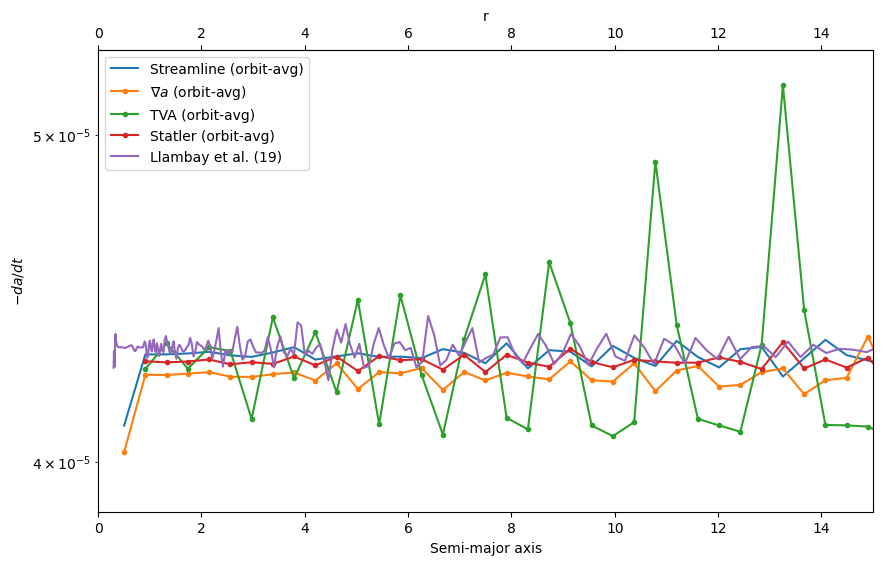

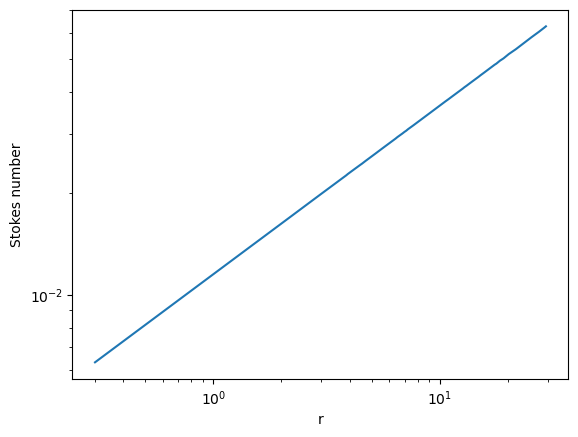

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (raw, unbinned) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    order = np.argsort(a_array)
    ax1.plot(a_array[order], -da_dt_arr[order], label='Streamline')

    # --- sim / drag / statler methods (raw, unbinned) ---
    for m in methods:
        a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        a_flat = a_map.flatten()
        da_dt_flat = da_dt_map.flatten()

        order = np.argsort(a_flat)
        ax1.plot(a_flat[order], -da_dt_flat[order], '.', ms=2, label=method_labels[m])

    # --- Llambay et al. (19) ---
    r_grid = loader.r_grid
    vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    ax1.plot(r_grid, -vr_llambay[:, 0], label='Llambay et al. (19)')

    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid, -delta_vr_files, label='FARGO3D')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(0, 15)
    ax1.legend()

    return fig1, ax1


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_axi/'
orbit = 19
fig, ax = single_snapshot_compare(path, orbit, 'dust', 1)

# 0.1cm-sized particles - Axisymmetric Disk - $\sqrt{v_{tot}^2 = v_{r}^{2} + v_{\phi}^{2}}$

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  a_mesh = np.where(counts > 0, a_mesh / counts, np.nan)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:121: RuntimeWarning: divide by zero encountered in divide
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:121: RuntimeWarning: invalid value encountered in multiply
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:124: RuntimeWarning: divide by zero encountered in divide
  r_grid = self.data_loader.r_grid
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:124: RuntimeWarning: invalid value encountered in divide
  r_grid = self.data_loader.r_grid
C:\Users\david\AppData\Local\Temp\ipykernel_16604\4238192521.py:56: RuntimeWarning: Mean 

Stokes number range: 0.006310366023543481 - 0.06267596082600406


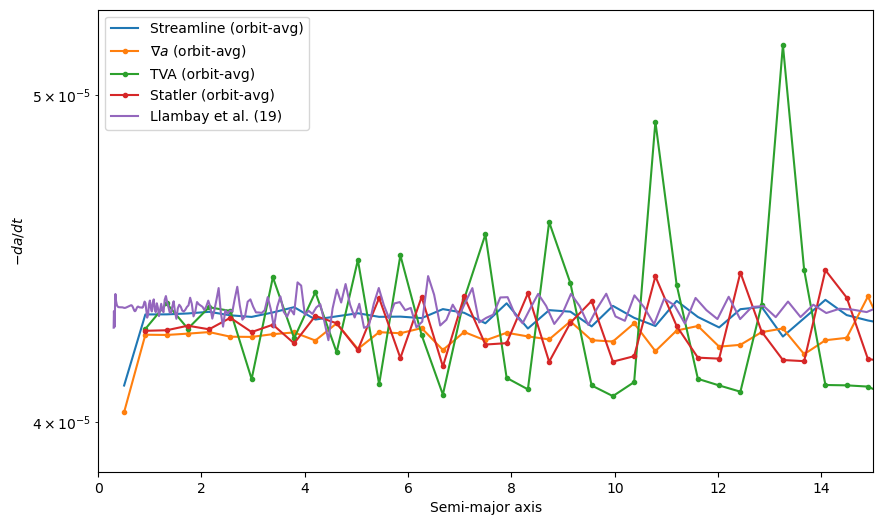

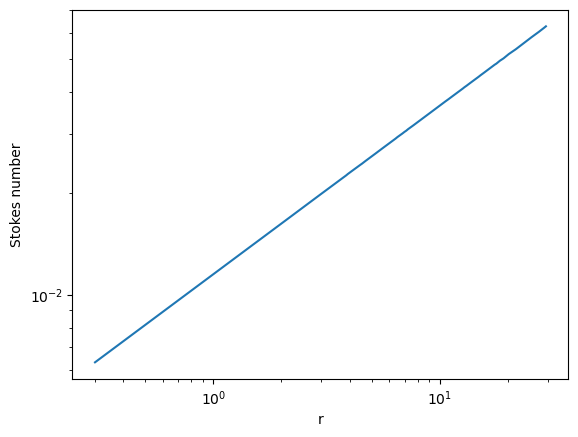

In [97]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    #methods = ['drag', 'statler']
    #method_labels = {'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.linspace(a_min, a_max, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
        da_dt_arr = (da_dt_arr - da_dt_arr_gas)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for m in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, m)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[m][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Figure 1: da/dt comparison across methods ---
    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))
    ax1.plot(bin_centers, -stream_avg, label='Streamline (orbit-avg)')
    ax1.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for m in methods:
        ax1.plot(bin_centers, -method_avg[m], '.-', label=f'{method_labels[m]} (orbit-avg)')
        ax1.fill_between(bin_centers, method_avg[m] - method_std[m],
                          method_avg[m] + method_std[m], alpha=0.15)

    r_grid = loader.r_grid
    # NOTE: rvc.llambay_19 currently uses the loop variable `orbit`, which after
    # the loop above is just the *last* orbit processed. If you want this tied
    # to a specific orbit regardless of what `orbits` contains, pass it explicitly.
    vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    ax1.plot(r_grid, -vr_llambay[:, 0], label='Llambay et al. (19)')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(0, 15)
    ax1.legend()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_axi/'
#path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_30orbits/'

orbits = range(19, 20)
orbit_averaged_compare(path, orbits, 'dust', 1)

# 0.1cm-sized particles - Eccentric Disk

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:156: RuntimeWarning: invalid value encountered in sqrt
  delta_v_gas_r, delta_v_gas_phi = self.calc_delta_v_gas(orbit)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:69: RuntimeWarning: invalid value encountered in sqrt
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:53: RuntimeWarning: invalid value encountered in sqrt
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:40: RuntimeWarning: invalid value encountered in sqrt
  dbeta_dr = np.gradient(beta, r_grid, axis=0)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:257: RuntimeWarning: invalid value encountered in sqrt
  delta_v_phi = 1 / (1 + St**2) * (beta - 1) * v_K + (2 * delta_v_gas_phi - St * delta_v_gas_r) / (2 * (1 + St**2))


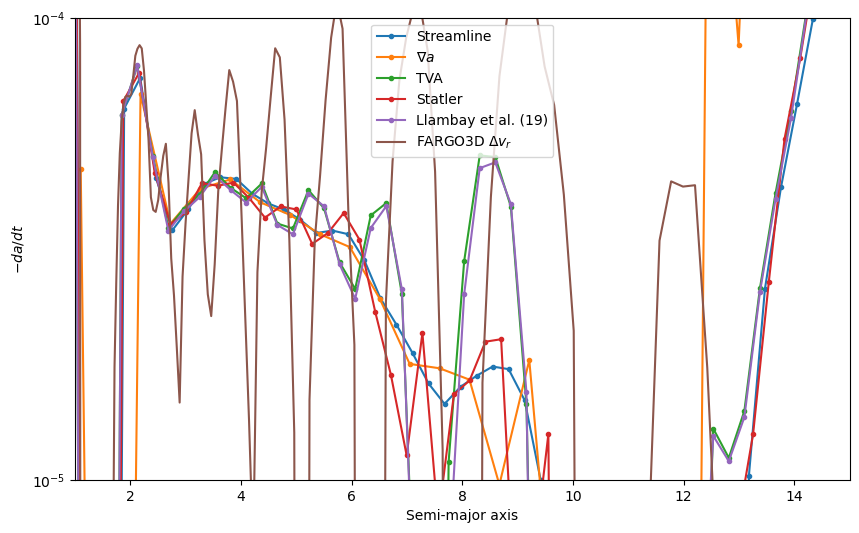

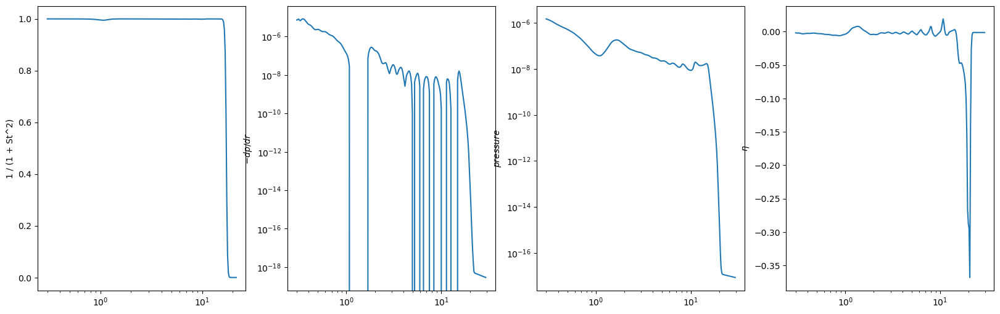

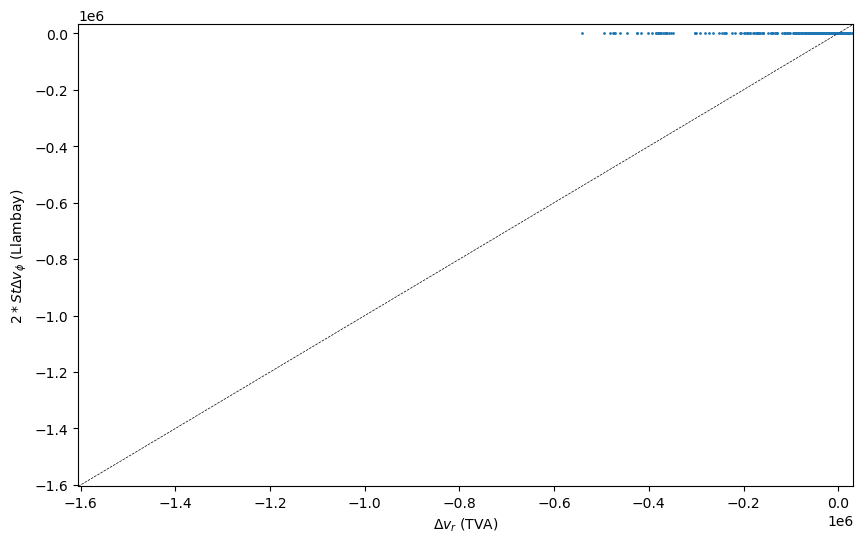

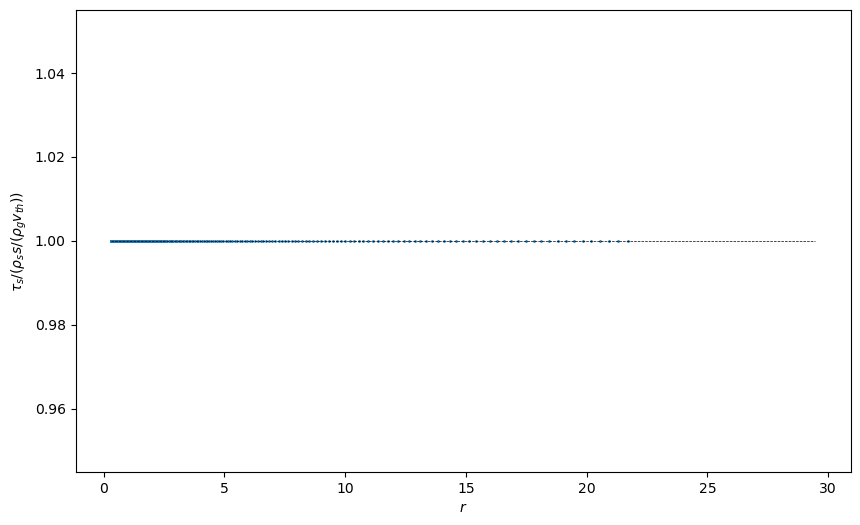

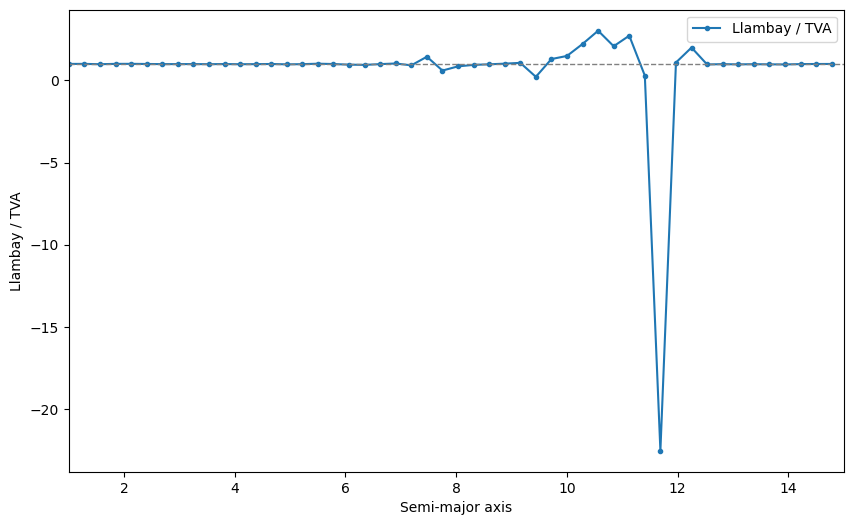

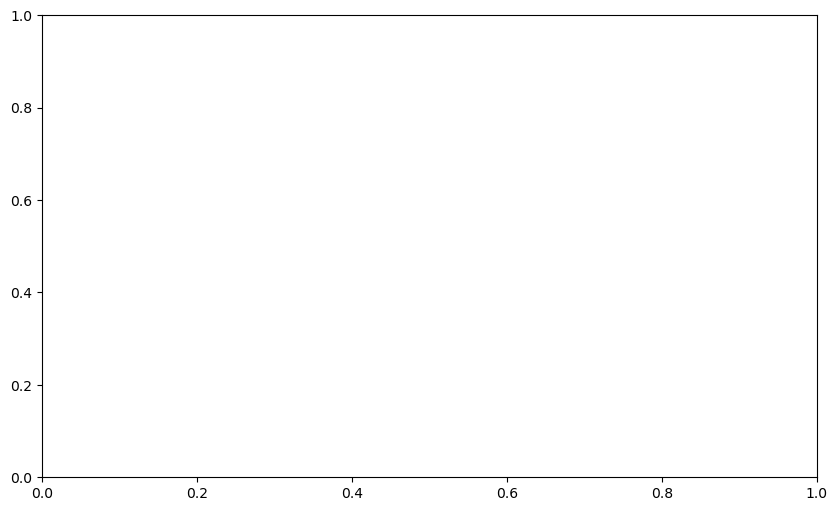

In [41]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    #methods = ['drag', 'llambay']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        #centers, means = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        results[m] = (centers, means)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('symlog', linthresh=1e-6)
    ax1.set_ylim(1e-5, 1e-4)
    ax1.set_xlim(1, 15)
    ax1.legend()

    # --- Ratio: Llambay / TVA(drag) ---
    centers_drag, means_drag = results['drag']
    centers_llambay, means_llambay = results['llambay']


    # interpolate llambay onto drag's bin centers (or pick whichever range you prefer)
    means_llambay_interp = np.interp(centers_drag, centers_llambay, means_llambay,
                                      left=np.nan, right=np.nan)

    ratio = means_llambay_interp / means_drag

    fig3, ax3 = plt.subplots(1, 1, figsize=(10, 6))
    mask_ratio = (centers_drag > 1) & (centers_drag < 15)
    ax3.plot(centers_drag[mask_ratio], ratio[mask_ratio], '.-', label='Llambay / TVA')
    ax3.axhline(1, color='gray', ls='--', lw=1)
    ax3.set_xlabel('Semi-major axis')
    ax3.set_ylabel('Llambay / TVA')
    ax3.set_xlim(1, 15)
    ax3.legend()

    fig4, ax4 = plt.subplots(1, 1, figsize=(10, 6))

    return fig1, ax1, fig3, ax3


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_30orbits/'
orbit = 19
fig1, ax1, fig3, ax3 = single_snapshot_compare(path, orbit, 'dust', 1)

# 100cm-sized particles - Eccentric Disk

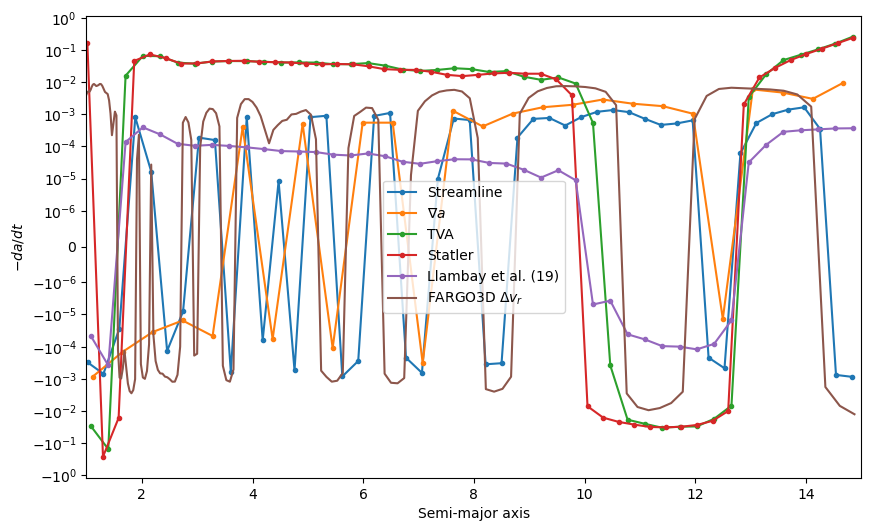

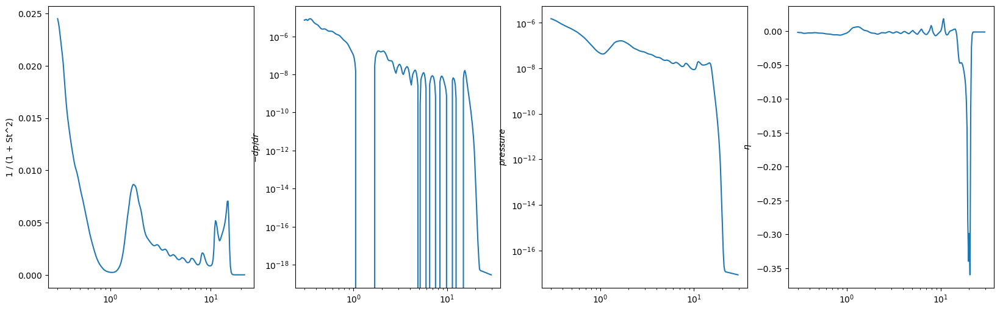

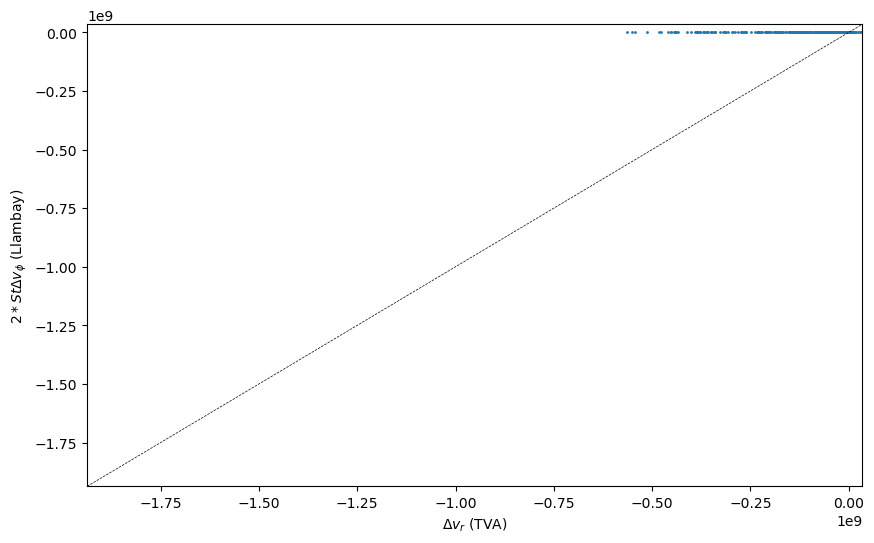

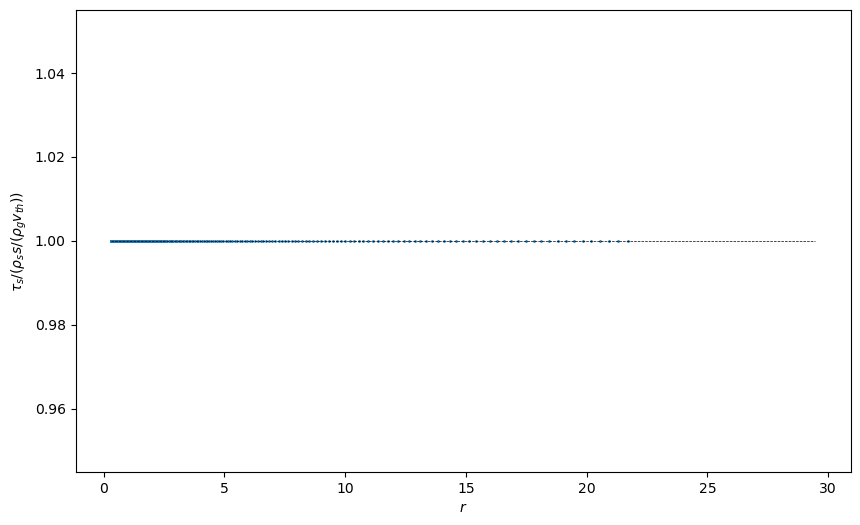

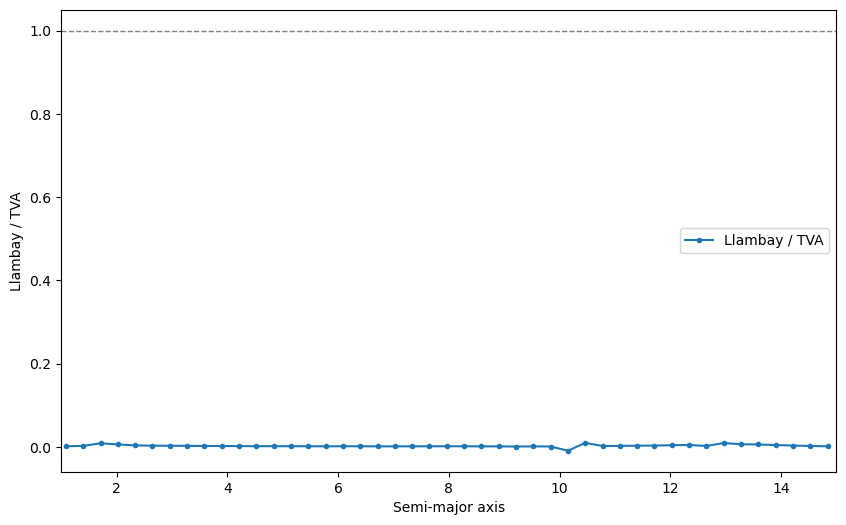

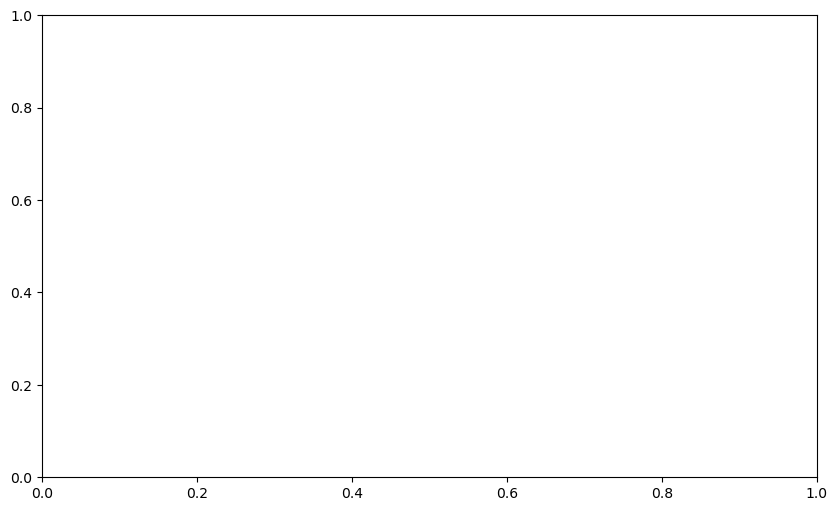

In [40]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}
    #methods = ['drag', 'llambay']

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler / llambay methods (each own bin range) ---
    results = {}
    for m in methods:
        a_map, da_dt_map, delta_v_r, delta_v_phi = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        #centers, means = bin_own_range(a_map.flatten(), delta_v_r.flatten(), n_bins)
        results[m] = (centers, means)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('symlog', linthresh=1e-6)
    ax1.set_xlim(1, 15)
    ax1.legend()

    # --- Ratio: Llambay / TVA(drag) ---
    centers_drag, means_drag = results['drag']
    centers_llambay, means_llambay = results['llambay']


    # interpolate llambay onto drag's bin centers (or pick whichever range you prefer)
    means_llambay_interp = np.interp(centers_drag, centers_llambay, means_llambay,
                                      left=np.nan, right=np.nan)

    ratio = means_llambay_interp / means_drag

    fig3, ax3 = plt.subplots(1, 1, figsize=(10, 6))
    mask_ratio = (centers_drag > 1) & (centers_drag < 15)
    ax3.plot(centers_drag[mask_ratio], ratio[mask_ratio], '.-', label='Llambay / TVA')
    ax3.axhline(1, color='gray', ls='--', lw=1)
    ax3.set_xlabel('Semi-major axis')
    ax3.set_ylabel('Llambay / TVA')
    ax3.set_xlim(1, 15)
    ax3.legend()

    fig4, ax4 = plt.subplots(1, 1, figsize=(10, 6))

    return fig1, ax1, fig3, ax3


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_30orbits/'
orbit = 19
fig1, ax1, fig3, ax3 = single_snapshot_compare(path, orbit, 'dust', 1)

# 100cm-sized particles - Axisymmetric Disk


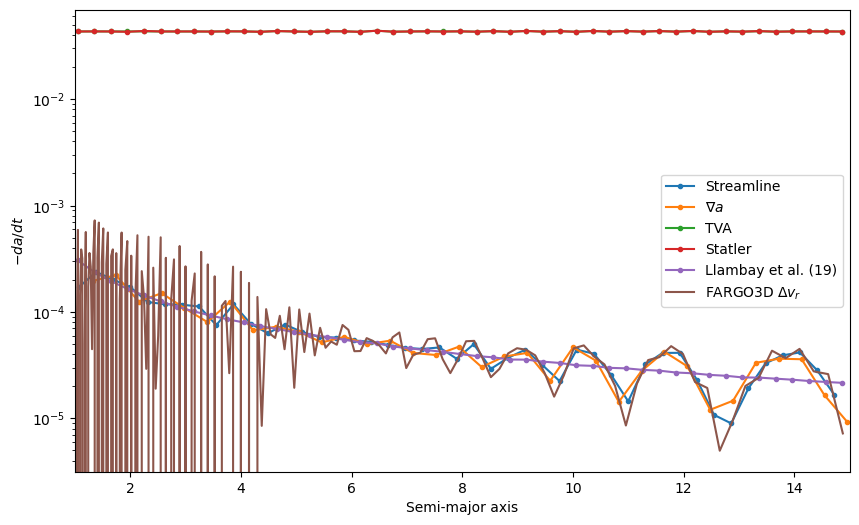

In [86]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def single_snapshot_compare(path, orbit, material, dust_num, n_bins=70):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler', 'llambay']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler', 'llambay': 'Llambay et al. (19)'}

    def bin_own_range(a_arr, da_dt_arr, n_bins):
        a_arr = np.asarray(a_arr)
        da_dt_arr = np.asarray(da_dt_arr)
        valid = np.isfinite(a_arr) & np.isfinite(da_dt_arr) & (a_arr > 0)
        a_arr, da_dt_arr = a_arr[valid], da_dt_arr[valid]
        if a_arr.size == 0:
            return np.array([]), np.array([])
        edges = np.linspace(a_arr.min(), a_arr.max(), n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        means, _, _ = binned_statistic(a_arr, da_dt_arr, statistic='mean', bins=edges)
        return centers, means

    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))

    # --- Streamline method (own bin range) ---
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
    da_dt_arr = da_dt_arr - da_dt_arr_gas

    centers, means = bin_own_range(a_array, da_dt_arr, n_bins)
    mask = (centers > 1) & (centers < 15)
    ax1.plot(centers[mask], -means[mask], '.-', label='Streamline')

    # --- sim / drag / statler methods (each own bin range) ---
    for m in methods:
        a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, m)
        centers, means = bin_own_range(a_map.flatten(), da_dt_map.flatten(), n_bins)
        mask = (centers > 1) & (centers < 15)
        ax1.plot(centers[mask], -means[mask], '.-', label=method_labels[m])

    # --- Llambay et al. (19) ---
    #r_grid = loader.r_grid
    #vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    #mask = (r_grid > 1) & (r_grid < 15)
    #ax1.plot(r_grid[mask], -vr_llambay[mask, 0], label='Llambay et al. (19)')

    # --- FARGO3D direct velocity difference ---
    r_grid = loader.r_grid
    mask = (r_grid > 1) & (r_grid < 15)
    delta_vr_files = loader.load_dustvel(orbit, 1)[0] - loader.load_gasvel(orbit)[0]
    ax1.plot(r_grid[mask], -delta_vr_files[mask, 0], label=r'FARGO3D $\Delta v_r$')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(1, 15)
    ax1.legend()

    return fig1, ax1


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_axi/'
orbit = 19
fig, ax = single_snapshot_compare(path, orbit, 'dust', 1)

# 100cm-sized particles - Axisymmetric Disk - $v_{\phi}$ from Fargo

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  a_mesh = np.where(counts > 0, a_mesh / counts, np.nan)


[-0.0425879  -0.04307075 -0.04278156 -0.04242024 -0.04170583 -0.04237429
 -0.04269272 -0.04248486 -0.04251132 -0.04237006 -0.04245766 -0.04227687
 -0.04026583 -0.04523805 -0.04320465 -0.04170552 -0.04300687 -0.04030933
 -0.04437656 -0.04188485 -0.04002176 -0.04490407 -0.04279992 -0.04171755
 -0.04309542 -0.04208467 -0.04302507 -0.04211472 -0.04269047 -0.04239827
 -0.04259274 -0.04246569 -0.03997712 -0.04575489 -0.04305388 -0.04034375
 -0.04478481 -0.04281858 -0.04212477 -0.04308756 -0.04241796 -0.04289837
 -0.04133799 -0.04483876 -0.04316868 -0.04231052 -0.04456918 -0.04304375
 -0.04232664 -0.04288628 -0.04250856 -0.04262533 -0.0443935  -0.04319628
 -0.04251822 -0.04261922 -0.0431933  -0.04255686 -0.04297673 -0.04266609
 -0.04211774 -0.04386028 -0.04276551 -0.04204867 -0.04309356 -0.04240366
 -0.04305502 -0.0428792  -0.04394515 -0.04303697 -0.04276062 -0.04390387
 -0.04300255 -0.04268595 -0.04301753 -0.04330821 -0.0429095  -0.04258226
 -0.04384154 -0.0429475  -0.04271533 -0.04317474 -0

C:\Users\david\AppData\Local\Temp\ipykernel_16604\952035922.py:56: RuntimeWarning: Mean of empty slice
  stream_avg = np.nanmean(stacked_stream, axis=0)
c:\Users\david\anaconda3\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\david\AppData\Local\Temp\ipykernel_16604\952035922.py:58: RuntimeWarning: Mean of empty slice
  method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}


Stokes number range: 6.3103660235434855 - 62.67596082591561


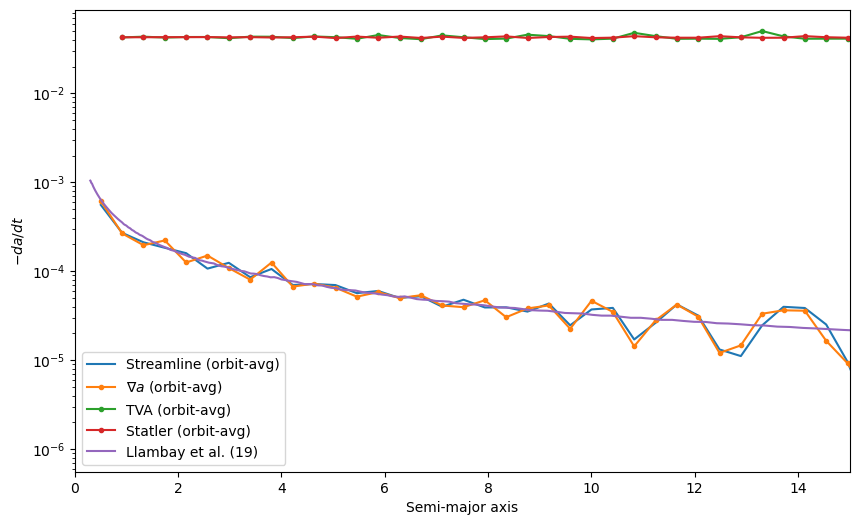

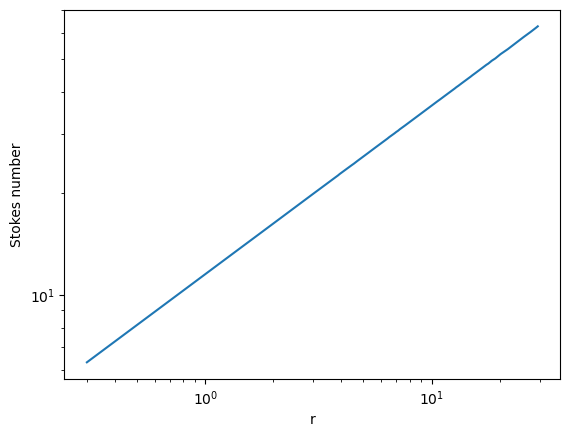

In [113]:
%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    #methods = ['drag', 'statler']
    #method_labels = {'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.linspace(a_min, a_max, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
        da_dt_arr = (da_dt_arr - da_dt_arr_gas)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for m in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, m)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[m][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Figure 1: da/dt comparison across methods ---
    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))
    ax1.plot(bin_centers, -stream_avg, label='Streamline (orbit-avg)')
    ax1.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for m in methods:
        ax1.plot(bin_centers, -method_avg[m], '.-', label=f'{method_labels[m]} (orbit-avg)')
        ax1.fill_between(bin_centers, method_avg[m] - method_std[m],
                          method_avg[m] + method_std[m], alpha=0.15)

    r_grid = loader.r_grid
    # NOTE: rvc.llambay_19 currently uses the loop variable `orbit`, which after
    # the loop above is just the *last* orbit processed. If you want this tied
    # to a specific orbit regardless of what `orbits` contains, pass it explicitly.
    vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    ax1.plot(r_grid, -vr_llambay[:, 0], label='Llambay et al. (19)')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(0, 15)
    ax1.legend()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_axi/'
#path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_30orbits/'

orbits = range(19, 20)
orbit_averaged_compare(path, orbits, 'dust', 1)

# 100cm-sized particles - Axisymmetric Disk - $\sqrt{v_{tot}^2 = v_{r}^{2} + v_{\phi}^{2}}$

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:23: RuntimeWarning: invalid value encountered in divide
  a_mesh = np.where(counts > 0, a_mesh / counts, np.nan)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:121: RuntimeWarning: divide by zero encountered in divide
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:121: RuntimeWarning: invalid value encountered in multiply
  
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:123: RuntimeWarning: invalid value encountered in sqrt
  def compute_da_dt_mass_flux(self, orbit, material, method):
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\orbital_evolution.py:124: RuntimeWarning: divide by zero encountered in divide
  r_grid = self.data_loader.r_grid
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulati

Stokes number range: 6.3103660235434855 - 62.67596082591561


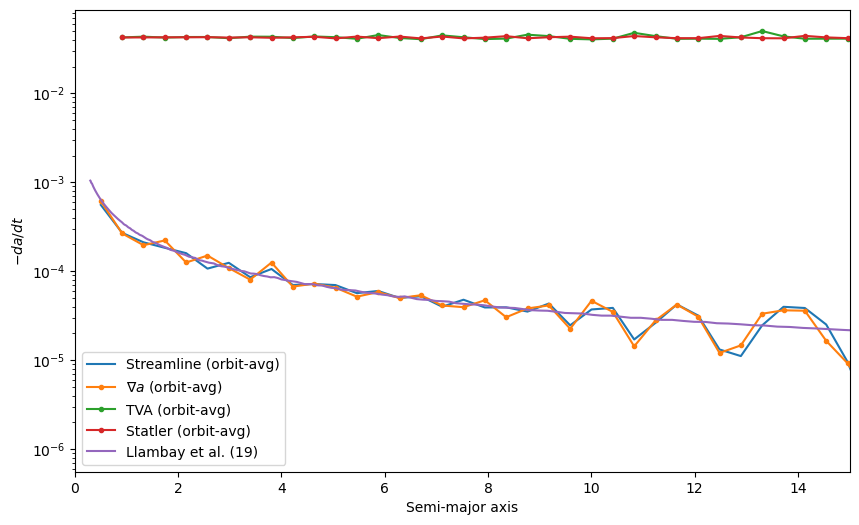

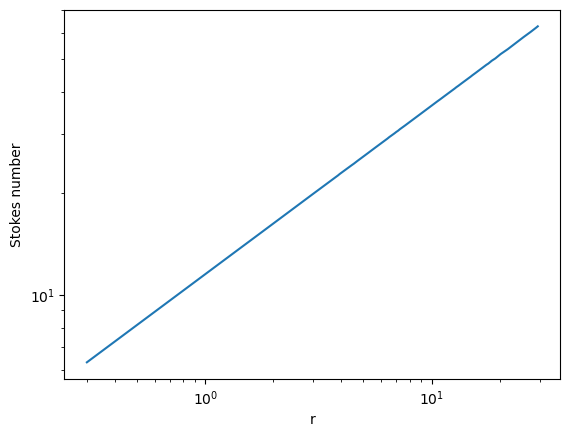

In [95]:
%reload_ext autoreload
%autoreload 2

%reload_ext autoreload
%autoreload 2

import numpy as np
from scipy.stats import binned_statistic
import matplotlib.pyplot as plt

def orbit_averaged_compare(path, orbits, material, dust_num, n_bins=70, a_min=None, a_max=None):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    method = 'sim'
    rvc = relative_velocity_calculator(loader, variables, streamlines, dust_num, method)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    methods = ['sim', 'drag', 'statler']
    method_labels = {'sim': r'$\nabla a$', 'drag': 'TVA', 'statler': 'Statler'}

    #methods = ['drag', 'statler']
    #method_labels = {'drag': 'TVA', 'statler': 'Statler'}

    # --- Pass 1: determine a common a-range across all orbits/methods ---
    if a_min is None or a_max is None:
        mins, maxs = [], []
        for orbit in orbits:
            for method in methods:
                a_map, _ = da_dt.compute_da_dt_mass_flux(orbit, material, method)
                a_flat = a_map.flatten()
                a_flat = a_flat[np.isfinite(a_flat) & (a_flat > 0)]
                if a_flat.size:
                    mins.append(a_flat.min())
                    maxs.append(a_flat.max())
        a_min, a_max = min(mins), max(maxs)

    bin_edges = np.linspace(a_min, a_max, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    # --- Pass 2: bin each orbit onto the shared grid, stack, then average ---
    stacked = {m: np.full((len(list(orbits)), n_bins), np.nan) for m in methods}
    stacked_stream = np.full((len(list(orbits)), n_bins), np.nan)

    for i, orbit in enumerate(orbits):
        a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
        a_array, da_dt_arr_gas = da_dt.compute_da_dt_2streams(path, orbit, 'gas')
        da_dt_arr = (da_dt_arr - da_dt_arr_gas)
        mean_s, _, _ = binned_statistic(a_array, da_dt_arr, statistic='mean', bins=bin_edges)
        stacked_stream[i] = mean_s

        for m in methods:
            a_map, da_dt_map = da_dt.compute_da_dt_mass_flux(orbit, material, m)
            mean_vals, _, _ = binned_statistic(
                a_map.flatten(), da_dt_map.flatten(), statistic='mean', bins=bin_edges
            )
            stacked[m][i] = mean_vals

    stream_avg = np.nanmean(stacked_stream, axis=0)
    stream_std = np.nanstd(stacked_stream, axis=0)
    method_avg = {m: np.nanmean(stacked[m], axis=0) for m in methods}
    method_std = {m: np.nanstd(stacked[m], axis=0) for m in methods}

    # --- Figure 1: da/dt comparison across methods ---
    fig1, ax1 = plt.subplots(1, 1, figsize=(10, 6))
    ax1.plot(bin_centers, -stream_avg, label='Streamline (orbit-avg)')
    ax1.fill_between(bin_centers, stream_avg - stream_std, stream_avg + stream_std, alpha=0.15)

    for m in methods:
        ax1.plot(bin_centers, -method_avg[m], '.-', label=f'{method_labels[m]} (orbit-avg)')
        ax1.fill_between(bin_centers, method_avg[m] - method_std[m],
                          method_avg[m] + method_std[m], alpha=0.15)

    r_grid = loader.r_grid
    # NOTE: rvc.llambay_19 currently uses the loop variable `orbit`, which after
    # the loop above is just the *last* orbit processed. If you want this tied
    # to a specific orbit regardless of what `orbits` contains, pass it explicitly.
    vr_llambay, St = rvc.llambay_19(orbit, path, 'particle')
    ax1.plot(r_grid, -vr_llambay[:, 0], label='Llambay et al. (19)')

    ax1.set_xlabel('Semi-major axis')
    ax1.set_ylabel(r'$-da/dt$')
    ax1.set_yscale('log')
    ax1.set_xlim(0, 15)
    ax1.legend()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_axi/'
#path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_30orbits/'

orbits = range(19, 20)
orbit_averaged_compare(path, orbits, 'dust', 1)

C:\Users\david\AppData\Local\Temp\ipykernel_10004\980941247.py:16: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)


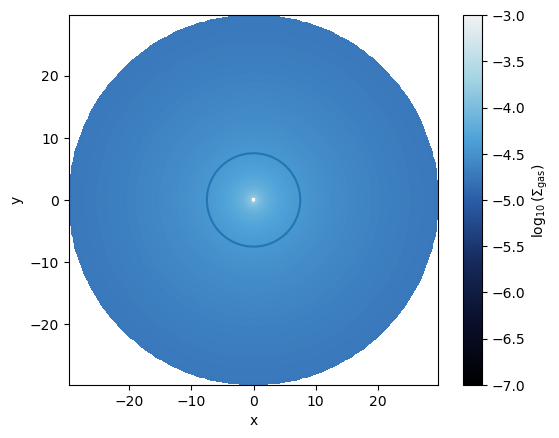

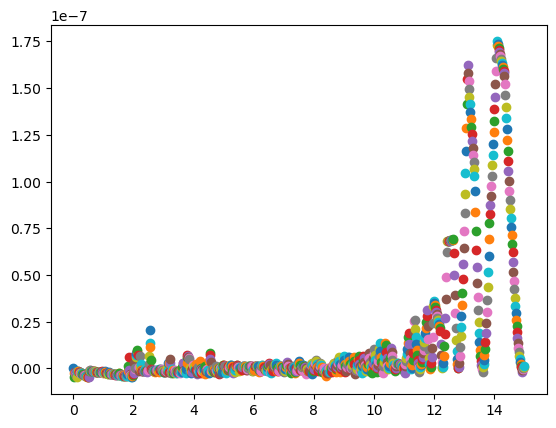

In [ ]:
%reload_ext autoreload
%autoreload 2

from analysis.orbital import fit_ellipse_polar

def check_streamline(path, orbit, material):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)

    r_vecs = streamlines.get_streamline_vectorized(np.linspace(0, 15, 1000), 0, 10, material, 1)

    r_grid = loader.r_grid
    phi_grid = loader.phi_grid

    gasdens = loader.load_gasdens(orbit)

    fig, ax = plt.subplots(1, 1)
    pcm = ax.pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
    cm = plt.colorbar(pcm, ax=ax, label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_aspect('equal')


    plt.plot(r_vecs[500] * np.cos(phi_grid), r_vecs[500] * np.sin(phi_grid))
    plt.show()

    for i in range(len(r_vecs)):
        a = fit_ellipse_polar(r_vecs[i], phi_grid)[0]

        plt.scatter(a, a - np.mean(r_vecs[i]))


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/'
orbits = 10
check_streamline(path, orbits, 'gas')

    



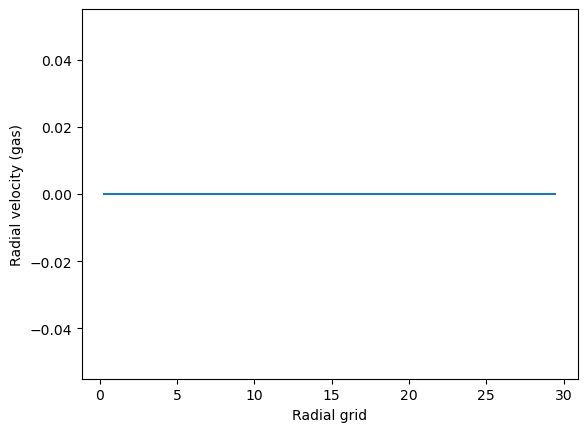

C:\Users\david\AppData\Local\Temp\ipykernel_10004\2237397686.py:19: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(loader.X, loader.Y, v_r_gas, cmap=cmap)


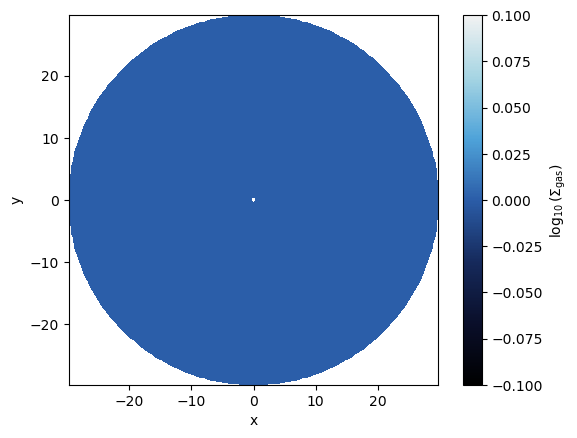

In [ ]:
%reload_ext autoreload
%autoreload 2

path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100_axi/'

loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
orbit = 0

v_r_gas, _ = loader.load_gasvel(orbit)

r_grid = loader.r_grid

plt.plot(r_grid, np.mean(v_r_gas, axis=1))
plt.xlabel('Radial grid')
plt.ylabel('Radial velocity (gas)')
plt.show()



fig, ax = plt.subplots(1, 1)
pcm = ax.pcolormesh(loader.X, loader.Y, v_r_gas, cmap=cmap)
cm = plt.colorbar(pcm, ax=ax, label=r'$\log_{10}(\Sigma_{\rm gas})$')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_aspect('equal')


(1024, 1)


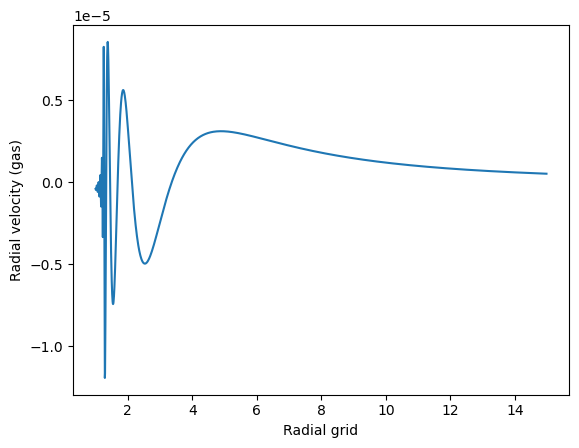

r_f = 1.217e+00


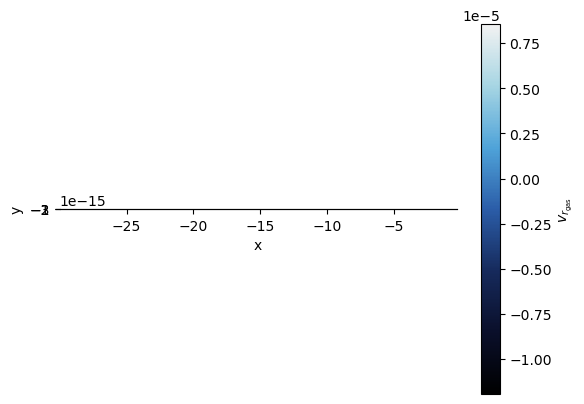

In [6]:
%reload_ext autoreload
%autoreload 2

#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_nu1e-5/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alpha1e-3_powerlaw/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alpha1e-3_test6/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_nodensdamp_syminner_lores/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr2/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha/'


loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
streamlines = SimulationDataStreamlines(loader, variables)
orbit = 3

c_s = variables.calculate_sound_speed()
v_r_gas, _ = loader.load_gasvel(orbit)
print(v_r_gas.shape)

r_grid = loader.r_grid

#plt.plot(r_grid, np.mean(v_r_gas, axis=1), label='Mean gas radial velocity')
mask = (r_grid > 1) & (r_grid < 15)
plt.plot(r_grid[mask], v_r_gas[mask, 0], label='Mean gas radial velocity')
plt.xlabel('Radial grid')
plt.ylabel('Radial velocity (gas)')
#plt.legend()
plt.show()

print(f"r_f = {(15 * np.pi * 0.05 / 2 + 0.3**(3/2))**(2/3):.3e}")

fig, ax = plt.subplots(1, 1)
pcm = ax.pcolormesh(loader.X, loader.Y, v_r_gas, cmap=cmap)
cm = plt.colorbar(pcm, ax=ax, label=r'$v_{r_{\rm gas}}$')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_aspect('equal')
#make movie of v_r_gas over time
#change viscosity (higher/lower)

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\utils\visualization.py:123: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax[1].set_xscale('log')
MovieWriter ffmpeg unavailable; using Pillow instead.


[-6.83838119e-07 -6.82302169e-07 -6.80769681e-07 -6.79240633e-07
 -6.77715019e-07 -6.76192830e-07 -6.74674060e-07 -6.73158701e-07
 -6.71646746e-07 -6.70138187e-07]
[-6.83838119e-07 -6.82302169e-07 -6.80769681e-07 -6.79240633e-07
 -6.77715019e-07 -6.76192830e-07 -6.74674060e-07 -6.73158701e-07
 -6.71646746e-07 -6.70138187e-07]
[-6.83838193e-07 -6.82302242e-07 -6.80769753e-07 -6.79240707e-07
 -6.77715094e-07 -6.76192907e-07 -6.74674139e-07 -6.73158783e-07
 -6.71646830e-07 -6.70138271e-07]
[-6.83838286e-07 -6.82302335e-07 -6.80769848e-07 -6.79240801e-07
 -6.77715188e-07 -6.76193001e-07 -6.74674233e-07 -6.73158875e-07
 -6.71646920e-07 -6.70138361e-07]
[-6.83838356e-07 -6.82302405e-07 -6.80769916e-07 -6.79240868e-07
 -6.77715255e-07 -6.76193068e-07 -6.74674299e-07 -6.73158941e-07
 -6.71646987e-07 -6.70138428e-07]
[-6.83838454e-07 -6.82302503e-07 -6.80770014e-07 -6.79240968e-07
 -6.77715355e-07 -6.76193167e-07 -6.74674399e-07 -6.73159041e-07
 -6.71647086e-07 -6.70138526e-07]
[-6.83838581e-07

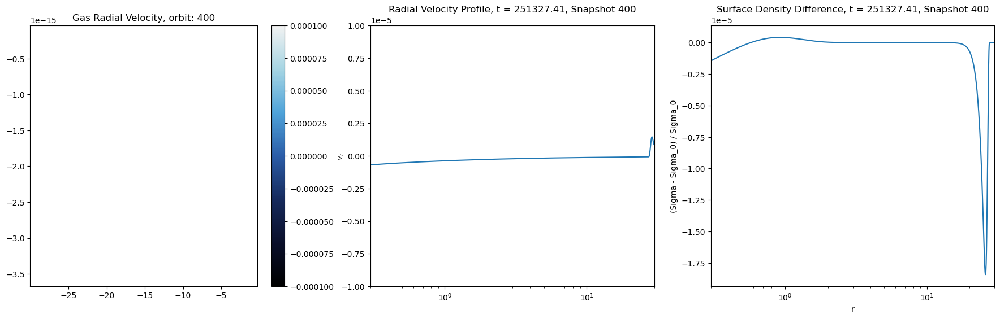

In [26]:
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lowdamp_hihires_evenfinerdt/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_size_eps0.01/'

from utils.visualization import animate_dust_gas
loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
visualizer = animate_dust_gas(loader, variables, 1)

orbit_list = np.linspace(360, 400, 41, dtype=int)

visualizer.radial_vel_animation(orbit_list)

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\utils\visualization.py:53: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  fig.colorbar(pcm_gas,      ax=ax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\utils\visualization.py:57: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  def _title(panel, label, orbit):
MovieWriter ffmpeg unavailable; using Pillow instead.


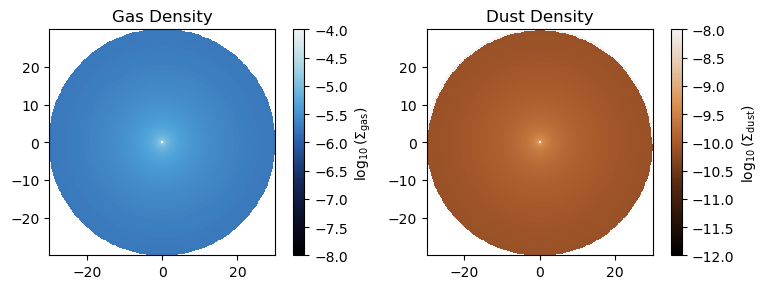

In [58]:
%reload_ext autoreload
%autoreload 2


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lowdamp_hihires_evenfinerdt_openinner/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lowdamp_hihires_superfinedt_openinner/'

path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_alpha_def_longrun/'
path = '/Users/david/Documents/CircumstellarDisks/fargo/dustydisk_binary_St1/'


from utils.visualization import animate_dust_gas
loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
visualizer = animate_dust_gas(loader, variables, 1)

orbit_list = np.linspace(0, 40, 41, dtype=int)

visualizer.create_animation(orbit_list)

(2054,) (2055,) (2054,) (2054,) (1,)
r_grid: [1.83191035 1.82985187 1.82779571 ... 0.18236903 0.18216411 0.18195941]
v_phi: [1.82744412 1.82539066 1.82333951 ... 0.18212907 0.18192441 0.18171999]
r_mid (alg): [1.83088024 1.82882293 1.82676792 ... 0.18247152 0.18226648 0.18206167]
r_mid (geo): [1.83088082 1.8288235  1.8267685  ... 0.18247158 0.18226654 0.18206173]


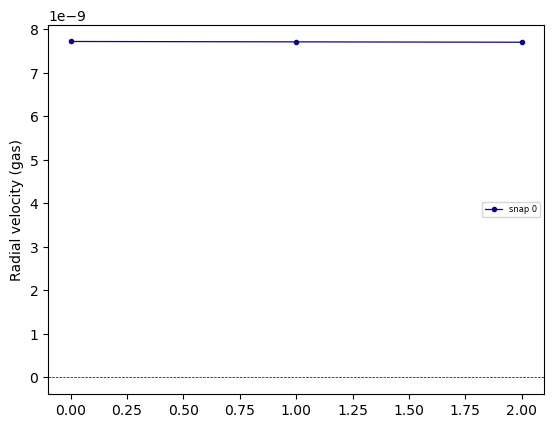

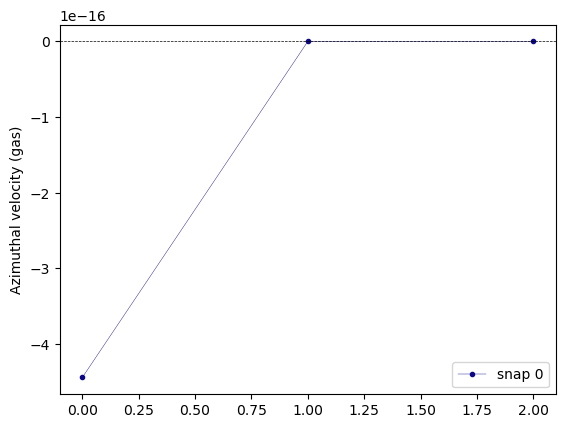

In [196]:
import os
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr_ghosttest/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr_hires4/'


paths = ['/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_middamp_hihires_superfinedt_openinner_ghost/',
        '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lowdamp_hihires_superfinedt_openinner_ghost/',
        '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lomiddamp_hihires_superfinedt_openinner_ghost/',
        '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_superlowdamp_hihires_superfinedt_openinner_ghost/'
]
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_nodamp_viscr/'

cmap = plt.get_cmap('plasma')

ncore = 1
orbits = 1
r_grid   = np.loadtxt(os.path.join(path, "domain_y.dat"))

#r_grid = (r_grid[1:] + r_grid[:-1]) / 2

#print(r_grid[0:4])
phi_grid = np.loadtxt(os.path.join(path, "domain_x.dat"))[:-1]

PHI, R = np.meshgrid(phi_grid, r_grid, indexing="xy")

X, Y = R * np.cos(PHI), R * np.sin(PHI)

#for path in paths:
for j in range(1):
    figvr, axvr = plt.subplots(1, 1)
    figphi, axphi = plt.subplots(1, 1)
    #figdens, axdens = plt.subplots(1, 1)
    for i in range(orbits):
        active_idx = 3
        #i *= 5
        active_r = (r_grid[active_idx + 1] + r_grid[active_idx]) / 2
        ghost_r = (r_grid[1:active_idx + 1] + r_grid[:active_idx]) / 2
        active_r = np.array(r_grid[active_idx])
        ghost_r = r_grid[:active_idx]

        #print(active_r, ghost_r)

        
        gasdens  = []

        vrs = []

        vphis = []
        dustvrs = []

        v_r_0 = np.fromfile(os.path.join(path, f"gasvy0_0.dat"))
        vphi_0 = np.fromfile(os.path.join(path, f"gasvx0_0.dat"))

        for core in range(0, ncore):
            gasdens_0 = np.fromfile(os.path.join(path, f"gasdens{i}_{core}.dat"))
            v_r = np.fromfile(os.path.join(path, f"gasvy{i}_{core}.dat"))
            vphi = np.fromfile(os.path.join(path, f"gasvx{i}_{core}.dat"))

            print(vphi.shape, r_grid.shape, gasdens_0.shape, v_r.shape, phi_grid.shape)



            print(f"r_grid: {1 / np.sqrt(np.array(r_grid))}")

            print(f"v_phi: {vphi}")

            r_mid = np.sqrt(r_grid[1:] * r_grid[:-1])
            r_mid = (r_grid[1:] + r_grid[:-1]) / 2
            print(f"r_mid (alg): {1 / np.sqrt(np.array(r_mid))}")

            r_mid = np.sqrt(r_grid[1:] * r_grid[:-1])
            print(f"r_mid (geo): {1 / np.sqrt(np.array(r_mid))}")
            #print(1 / np.sqrt(np.array(r_mid)))
            #dust_vr = np.fromfile(os.path.join(path, f"dust1vy{i}_{core}.dat"))
            vrs.append(v_r[3:-4])
            vphis.append(vphi)
            #dustvrs.append(dust_vr)
            gasdens.append(gasdens_0)
            #print((len(np.array(gasdens).flatten())-200*6*(snap+1)) / 200)

            v_r_powerlaw = np.array(v_r[active_idx] * np.sqrt(active_r / ghost_r))
            vphi_powerlaw = np.array(vphi[active_idx] * np.sqrt(active_r / ghost_r))

        #gasdens = np.array(gasdens).reshape((len(r_grid), len(phi_grid)))

        axvr.plot(np.array(v_r).flatten()[:active_idx] - np.array(v_r_powerlaw).flatten()[:active_idx], '.-', linewidth=0.9, label=f'snap {i}', color=cmap(i/orbits))
        #axvr.plot(np.array(v_r).flatten()[:active_idx], '.-', linewidth=0.3, label=f'snap {i}', color=cmap(i/orbits))

        #axvr.plot(np.array(v_r_powerlaw).flatten()[:active_idx], '.-', linewidth=0.9, label=f'powerlaw', color='black')
        axvr.set_ylabel('Radial velocity (gas)')
        axvr.legend(ncol=5, fontsize = 6)
        axvr.axhline(0, color='black', ls='--', lw=0.5)
        #axvr.set_title(f'{path.split("/")[-2]}')
        #axvr.set_ylim(-8e-6, -5e-6)


        axphi.plot(np.array(vphi).flatten()[:active_idx] - np.array(vphi_powerlaw).flatten()[:active_idx], '.-', linewidth=0.3, label=f'snap {i}', color=cmap(i/orbits))
        axphi.set_ylabel('Azimuthal velocity (gas)')
        axphi.axhline(0, color='black', ls='--', lw=0.5)
        #axphi.plot(np.array(vphi_powerlaw).flatten()[:active_idx], '.-', linewidth=0.9, label=f'powerlaw', color='black')
        axphi.legend()

        #axdens.plot(np.array(gasdens).flatten(), '-', linewidth=0.3, label=f'snap {i}', color=cmap(i/orbits))
        #axdens.set_ylabel('Gas density')
        #axdens.legend()

    #axdust.plot(np.array(dustvrs).flatten(), '-', linewidth = 0.3, label=f'snap {i}')
    #axdust.set_ylabel('Radial velocity (dust)')
   # axdust.legend()

In [126]:
r = np.logspace(0.3, 30, 100)
r[1] / r[0]

1.9952623149688795

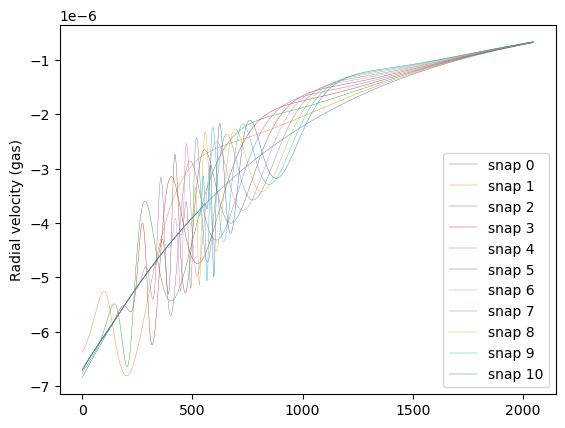

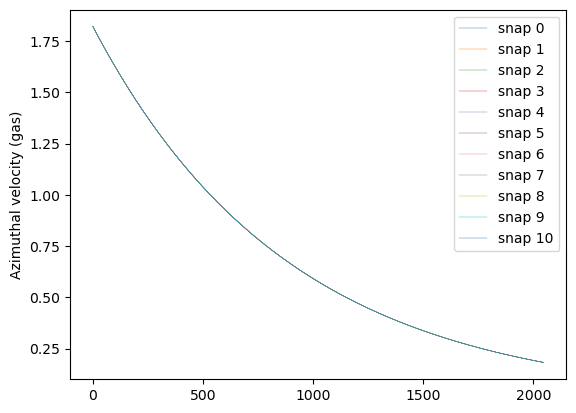

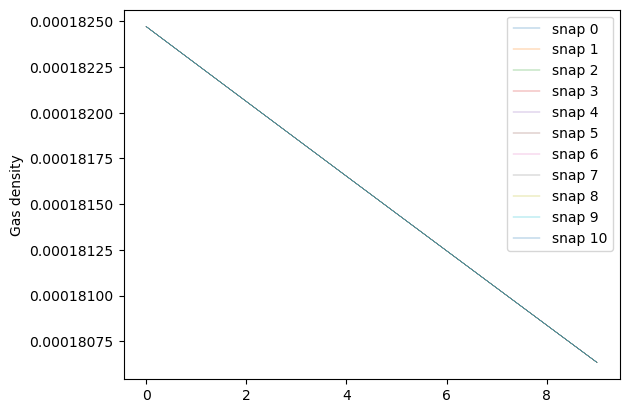

In [33]:
import os
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_gasdisk_alldamp_viscr_lowdamp_hihires_finedt/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr_hires4/'


ncore = 2
r_grid   = np.loadtxt(os.path.join(path, "domain_y.dat"))
phi_grid = np.loadtxt(os.path.join(path, "domain_x.dat"))[:-1]

PHI, R = np.meshgrid(phi_grid, r_grid, indexing="xy")

X, Y = R * np.cos(PHI), R * np.sin(PHI)

figvr, axvr = plt.subplots(1, 1)
figphi, axphi = plt.subplots(1, 1)
figdens, axdens = plt.subplots(1, 1)

for i in range(11):

    gasdens  = []
    vrs = []
    vphis = []

    gasdens_0 = np.fromfile(os.path.join(path, f"gasdens{i}.dat"))
    v_r = np.fromfile(os.path.join(path, f"gasvy{i}.dat"))
    vphi = np.fromfile(os.path.join(path, f"gasvx{i}.dat"))
    vrs.append(v_r)
    vphis.append(vphi)
    gasdens.append(gasdens_0)
        #print((len(np.array(gasdens).flatten())-200*6*(snap+1)) / 200)
    #gasdens = np.array(gasdens).reshape((len(r_grid), len(phi_grid)))

    axvr.plot(np.array(vrs).flatten(), '-', linewidth=0.3, label=f'snap {i}')
    axvr.set_ylabel('Radial velocity (gas)')
    axvr.legend()

    axphi.plot(np.array(vphis).flatten(), '-', linewidth=0.3, label=f'snap {i}')
    axphi.set_ylabel('Azimuthal velocity (gas)')
    axphi.legend()

    axdens.plot(np.array(gasdens).flatten()[:10], '-', linewidth=0.3, label=f'snap {i}')
    axdens.set_ylabel('Gas density')
    axdens.legend()

[-2.90213626e-06 -2.88911397e-06 -2.21330613e-06 -1.52126120e-06
 -1.15295434e-06 -1.43277986e-06 -2.45452050e-06 -3.93434704e-06
 -5.33170902e-06 -6.17417604e-06 -6.35930682e-06 -6.29183025e-06
 -6.22396083e-06 -6.15579033e-06 -6.08739405e-06 -6.01884937e-06
 -5.95031728e-06 -5.88206552e-06 -5.81440424e-06 -5.74768788e-06
 -5.68240556e-06 -5.61917017e-06 -5.55862143e-06 -5.50146423e-06
 -5.44855933e-06 -5.40082794e-06 -5.35917056e-06 -5.32456242e-06
 -5.29799733e-06 -5.28031046e-06 -5.27227006e-06 -5.27457686e-06
 -5.28765384e-06 -5.31175212e-06 -5.34690722e-06 -5.39267471e-06
 -5.44832759e-06 -5.51269036e-06 -5.58405202e-06 -5.66045458e-06
 -5.73930765e-06 -5.81780446e-06 -5.89263031e-06 -5.96031506e-06
 -6.01721943e-06 -6.05982216e-06 -6.08483790e-06 -6.08941963e-06
 -6.07134293e-06 -6.02923386e-06 -5.96281101e-06 -5.87304342e-06
 -5.76223011e-06 -5.63397868e-06 -5.49317430e-06 -5.34588857e-06
 -5.19913214e-06 -5.06043918e-06 -4.93735857e-06 -4.83695495e-06
 -4.76528033e-06 -4.72676

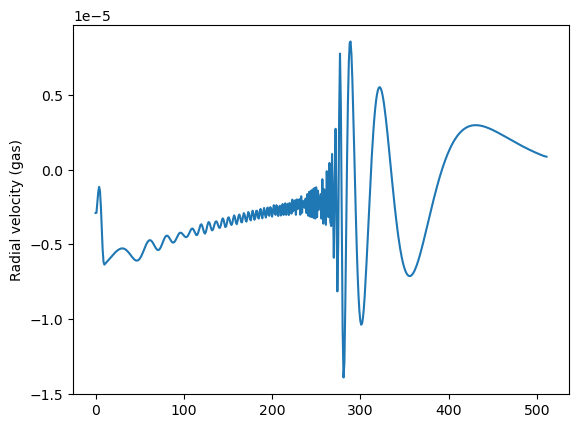

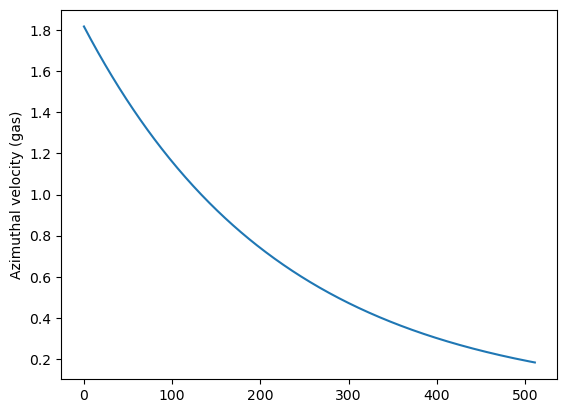

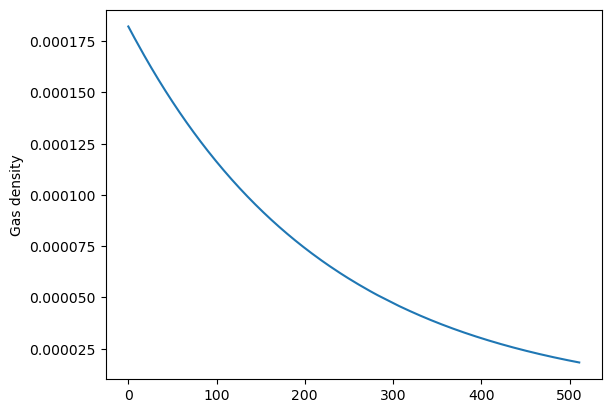

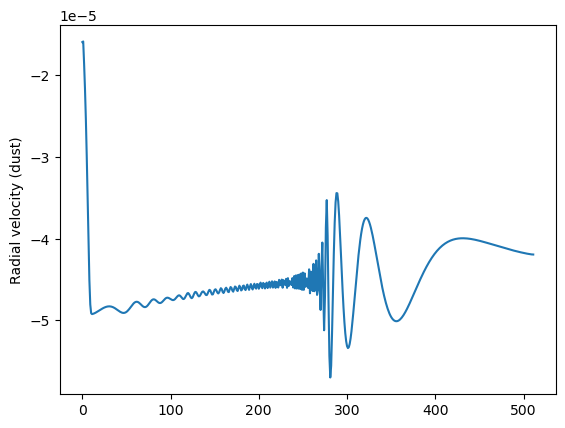

In [5]:
import os
path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr_noghosttest/'
#path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_alldamp_viscr_hires4/'

snap = 3

r_grid   = np.loadtxt(os.path.join(path, "domain_y.dat"))[3:-4]
r_grid
phi_grid = np.loadtxt(os.path.join(path, "domain_x.dat"))[:-1]

PHI, R = np.meshgrid(phi_grid, r_grid, indexing="xy")

X, Y = R * np.cos(PHI), R * np.sin(PHI)

gasdens  = []

vrs = []

vphis = []
dustvrs = []

for snap in [3]:
    gasdens_0 = np.fromfile(os.path.join(path, f"gasdens{snap}.dat")).reshape((len(r_grid), len(phi_grid)))
    v_r = np.fromfile(os.path.join(path, f"gasvy{snap}.dat")).reshape((len(r_grid), len(phi_grid)))
    vphi = np.fromfile(os.path.join(path, f"gasvx{snap}.dat")).reshape((len(r_grid), len(phi_grid)))
    dust_vr = np.fromfile(os.path.join(path, f"dust1vy{snap}.dat")).reshape((len(r_grid), len(phi_grid)))
    vrs.append(v_r[:, 0])
    vphis.append(vphi[:, 0])
    dustvrs.append(dust_vr[:, 0])
    print(v_r[:, 0])
    print(vphi[:, 0])
    print(dust_vr[:, 0])
    print(gasdens_0[:, 0])
    gasdens.append(gasdens_0)
    #print((len(np.array(gasdens).flatten())-200*6*(snap+1)) / 200)
#gasdens = np.array(gasdens).reshape((len(r_grid), len(phi_grid)))

plt.plot(np.array(vrs).flatten(), '-')
plt.ylabel('Radial velocity (gas)')
plt.show()

plt.plot(np.array(vphis).flatten(), '-')
plt.ylabel('Azimuthal velocity (gas)')
plt.show()

plt.plot(np.array(gasdens).flatten(), '-')
plt.ylabel('Gas density')
plt.show()

plt.plot(np.array(dustvrs).flatten(), '-')
plt.ylabel('Radial velocity (dust)')
plt.show()
#pcm = plt.pcolormesh(X, Y, gasdens, cmap='viridis')

# Statler Disk of Axisymmetric Disk

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\core\processor.py:194: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[0, 0].pcolormesh(X, Y, np.log10(gas_dens), cmap="viridis", vmin=-7, vmax=-3)


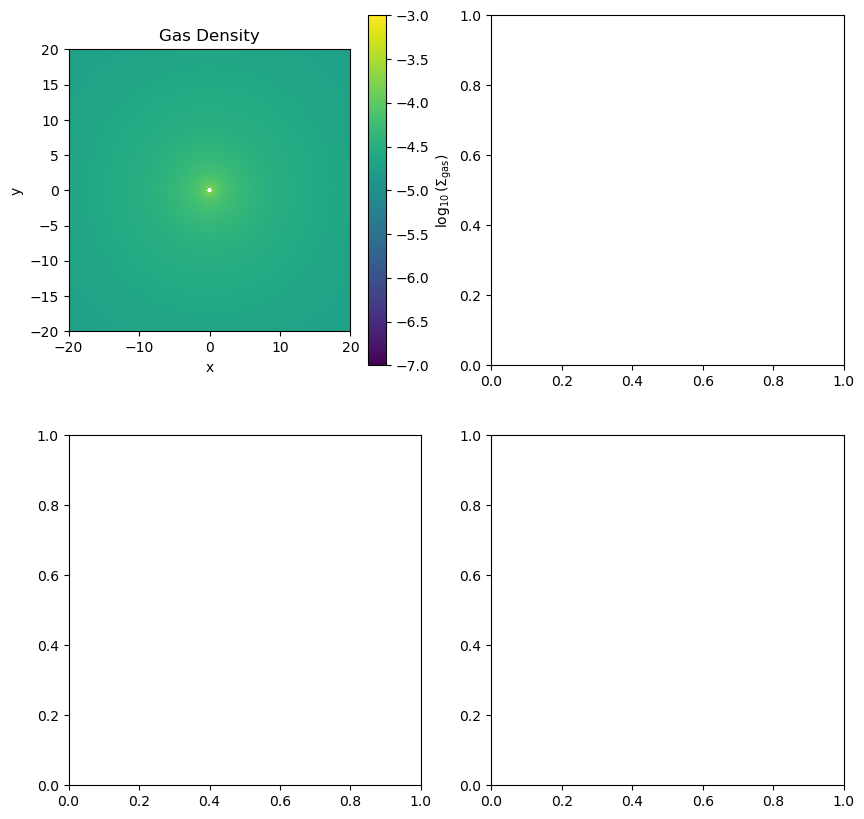

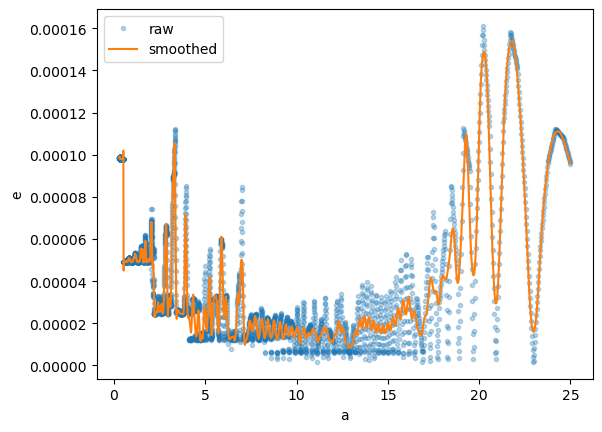

c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\core\processor.py:267: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[0, 1].pcolormesh(X, Y, np.log10(Sigma), cmap="viridis", vmin=-7, vmax=-3)
c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\core\processor.py:272: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1, 0].pcolormesh(X, Y, 1 - Sigma_ratio, cmap="viridis", vmin=-0.2, vmax=0.2)


<Figure size 640x480 with 0 Axes>

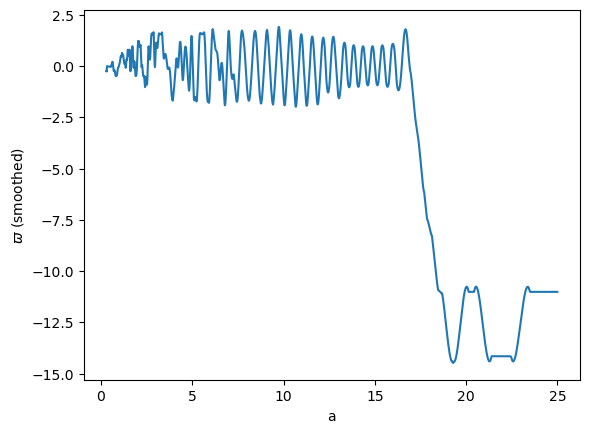

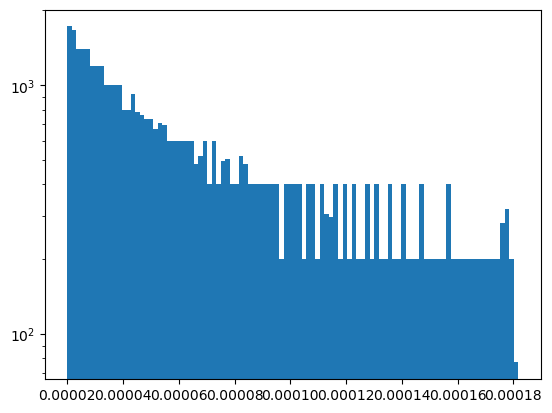

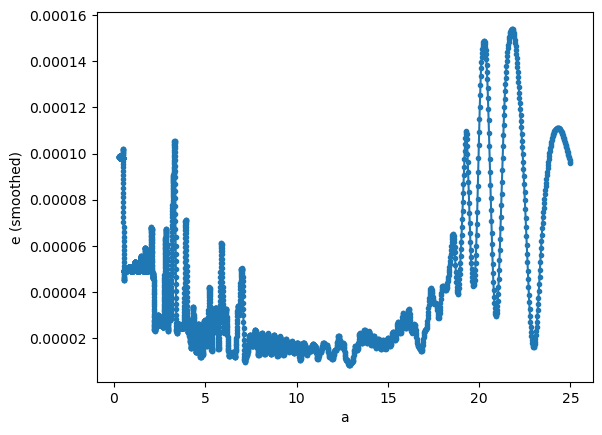

C:\Users\david\AppData\Local\Temp\ipykernel_16604\221048859.py:17: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma), cmap=cmap, vmin = -7, vmax = -3)
C:\Users\david\AppData\Local\Temp\ipykernel_16604\221048859.py:24: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin = -7, vmax = -3)
C:\Users\david\AppData\Local\Temp\ipykernel_16604\221048859.py:31: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically

Text(0.5, 1.0, '1 - log10(Statler)/log10(Fargo)')

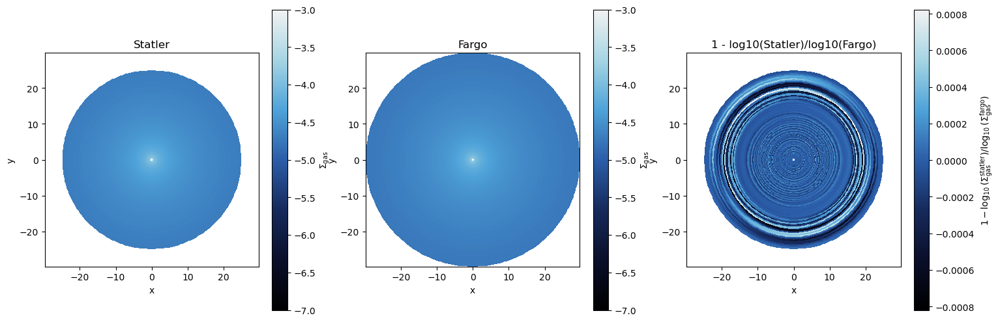

In [121]:
%reload_ext autoreload
%autoreload 2

path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1_axi/'

loader = SimulationDataLoader(path)
variables = SimulationVariablesCalculator(loader)
streamlines = SimulationDataStreamlines(loader, variables)
stokes_calc = Stokes_from_Particle(loader, variables, streamlines, 1)
rvc = relative_velocity_calculator(loader, variables, streamlines, 1, 'statler')
orbit = 19

gasdens = loader.load_gasdens(orbit)
_, _, Sigma, _, _, _ = rvc.calculate_statler_components(orbit)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma), cmap=cmap, vmin = -7, vmax = -3)
cm = plt.colorbar(pcm, ax=ax[0], label=r'$\Sigma_{\rm gas}$')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_aspect('equal')
ax[0].set_title('Statler')

pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin = -7, vmax = -3)
cm = plt.colorbar(pcm, ax=ax[1], label=r'$\Sigma_{\rm gas}$')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].set_aspect('equal')
ax[1].set_title('Fargo')

pcm = ax[2].pcolormesh(loader.X, loader.Y, 1 - np.log10(Sigma) / np.log10(gasdens), cmap=cmap)
cm = plt.colorbar(pcm, ax=ax[2], label=r'$1 - \log_{10}(\Sigma_{\rm gas}^{\rm statler}) / \log_{10}(\Sigma_{\rm gas}^{\rm fargo})$')
ax[2].set_xlabel('x')
ax[2].set_ylabel('y')
ax[2].set_aspect('equal')
ax[2].set_title('1 - log10(Statler)/log10(Fargo)')

# Fourier Mode Analysis

[nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj
 nan+nanj nan+nanj nan+nanj nan+nanj nan+nanj nan+n

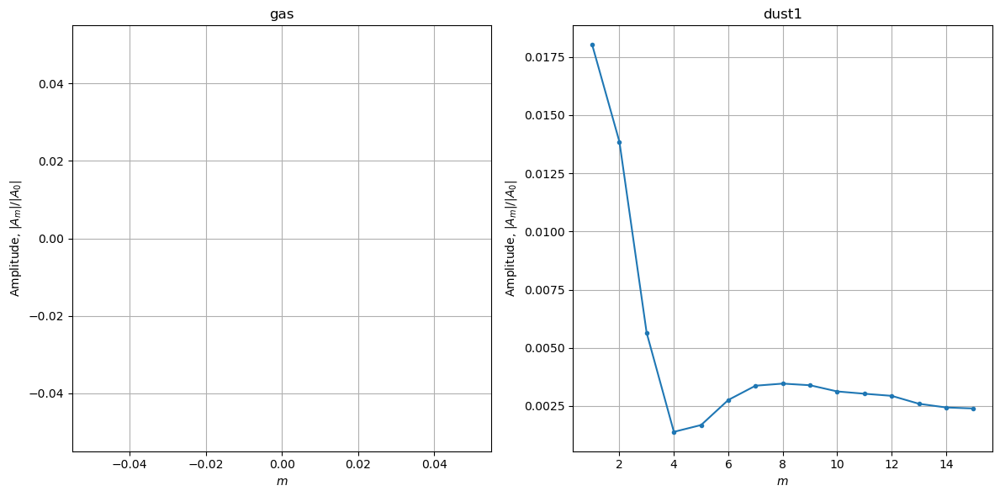

C:\Users\david\AppData\Local\Temp\ipykernel_45528\26993287.py:18: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_45528\26993287.py:25: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap, vmin=-9, vmax=-5)


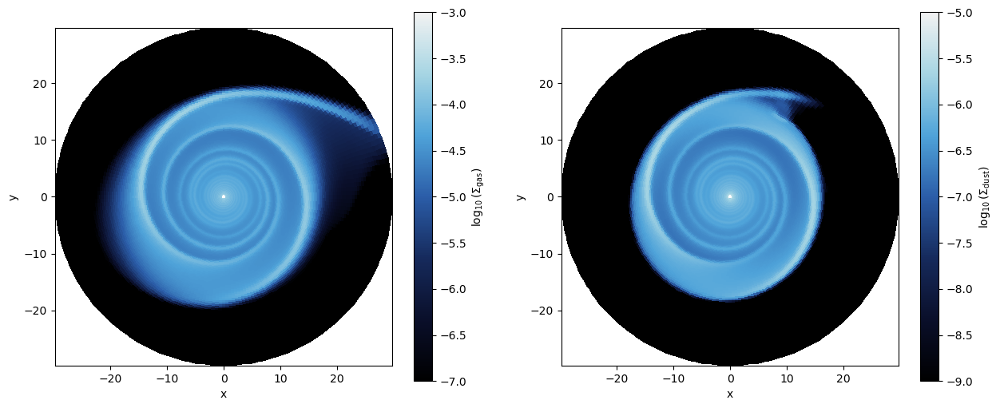

In [122]:
%reload_ext autoreload
%autoreload 2

path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1_30orbits/'
orbit = 1

loader = SimulationDataLoader(path)
stokes = relative_velocity_calculator(loader, variables, streamlines, 1, 'statler')
fft_analyzer = FFT_1D_Analyzer(loader)

Sigma = loader.load_gasdens(orbit)
#pres_map, dp_dr, Sigma, gas_dens, a_list, r_vec_list = stokes.calculate_statler_components(orbit)
dustdens = loader.load_dustdens(orbit, 1)

fft_analyzer.fft_amplitude_spectrum(orbit, dust_num=1, m_max=15)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma), cmap=cmap, vmin=-7, vmax=-3)
cm = plt.colorbar(pcm, ax=ax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_aspect('equal')


pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(dustdens), cmap=cmap, vmin=-9, vmax=-5)
cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm dust})$')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].set_aspect('equal')


In [ ]:
# run sim with no dust
# use llambay v_phi
# add delta_v_r to plots